# Small networks plot


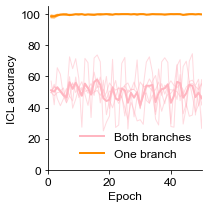

In [67]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np


seed_vals = [1,2,3,4,5]
# Plot training history
fig, ax = plt.subplots(1, 1, figsize=(3, 3))
fs = 12

# Plot 1: Loss curves

epochs = range(1, 1001)

sub_alpha = 0.5

color = 'lightpink'
icl_avs = np.zeros(len(epochs))
for seed in seed_vals:
    path = f"/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_nobase2/2_{seed}/"
    # Load the results
    results_path = path + "results.pkl"
    with open(results_path, "rb") as file:
        data = pickle.load(file)

    # Extract components
    results = data['results']
    history = data['history']
    params = data['params']
    execution_time = data['execution_time']


    icl_acc = np.array(history['icl_acc'])
    ax.plot(epochs, icl_acc, linewidth=1, color = color, alpha = sub_alpha)
    icl_avs += icl_acc
icl_avs /= len(seed_vals)
ax.plot(epochs, icl_avs, linewidth=2, color = color, label = 'Both branches')

color = 'darkorange'
icl_avs = np.zeros(len(epochs))
for seed in seed_vals:
    path = f"/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_max_nobase/2_{seed}/"
    # Load the results
    results_path = path + "results.pkl"
    with open(results_path, "rb") as file:
        data = pickle.load(file)

    # Extract components
    results = data['results']
    history = data['history']
    params = data['params']
    execution_time = data['execution_time']


    icl_acc = np.array(history['icl_acc'])
    ax.plot(epochs, icl_acc,  linewidth=1, color = color, alpha = sub_alpha)
    icl_avs += icl_acc
icl_avs /= len(seed_vals)
ax.plot(epochs, icl_avs, linewidth=2, color = color, label = 'One branch')






#ax.axhline(y=100, color='black', linestyle='--', linewidth=2, alpha=0.5, zorder = -10)

ax.set_xlabel('Epoch', fontsize=fs)
ax.set_ylabel('ICL accuracy', fontsize=fs)
ax.tick_params(axis='x', labelsize=fs)
ax.tick_params(axis='y', labelsize=fs)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim(0, 105)
ax.set_xlim(0, 50)
#ax.set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
ax.grid(False)#, alpha=0.3)
ax.legend(fontsize=fs, frameon=False, loc='lower right', ncol=1)

plt.tight_layout()
plt.show()
# Save the figure in high resolution
save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'ICLAccuracyTwoNodes.png', dpi=300, bbox_inches='tight')




  Initialized ICL Attention model (L=128 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: 0.0
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (12/12 active)
  base_W sparsity: 0.000 (4/4 active)
  Parameters: 20


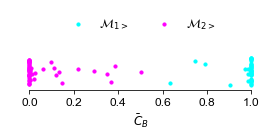

In [70]:
import ternary
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import matplotlib.colors as mcolors
import pickle
# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl
import torch
import random
from torch.utils.data import DataLoader

#path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_nobase2/2_5/"
path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_max_nobase2/2_4/"

seed = 5
random.seed(seed)

# Load the results
results_path = path + "results.pkl"
with open(results_path, "rb") as file:
    data = pickle.load(file)

# Extract components
results = data['results']
history = data['history']
params = data['params']
execution_time = data['execution_time']

# Assuming you have the model parameters
model = MatrixTreeMarkovICL(
    n_nodes=params['n_nodes'], 
    z_dim=params['D'], 
    L=params['L'], 
    N=params['N']
)

# Load the saved weights
model_path = path + 'model.pt'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model.load_state_dict(torch.load(model_path, map_location=device))

model.to(device)
model.eval()

gmm = GaussianMixtureModel(
    K=params['K'], 
    D=params['D'], 
    L=params['L'], 
    epsilon=params['epsilon'], 
    seed=params['seed'], 
    offset=params['offset']
)

train_data = generate_icl_gmm_data(gmm, params['train_samples'], params['N'], 
                                   novel_classes=False, exact_copy=params['exact_copy'], 
                                   B=params['B'], L=params['L'], shuffle_context=params['shuffle_context'], min_max_choice=params['min_max_choice'], unique_labels = params['unique_labels'])

train_loader = DataLoader(ICLGMMDataset(train_data), batch_size=params['batch_size'],
                          shuffle=True, collate_fn=collate_fn)





# Loop to collect n_samples points
n_samples = 100
p_steady_list = []
targets_list = []
class_list = []
min_max_list = []
model.eval()
with torch.no_grad():
    for i in range(n_samples):
        # Get a single example from the training dataset
        z_seq, labels, targets = train_loader.dataset[i]
        
        # Add batch dimension and move to device
        z_seq = z_seq.unsqueeze(0).to(device)  # Shape: (1, N+1, D)
        labels = labels.unsqueeze(0).to(device)  # Shape: (1, N)
        targets = targets.unsqueeze(0).to(device).long()  # Shape: (1,)
        # print(targets)
        # print(labels)
        # Find which element of labels equals the target
        matching_indices = (labels[0] == targets[0]).nonzero(as_tuple=True)[0]
        if len(matching_indices) > 0:
            class_idx = matching_indices[0].item()
        else:
            class_idx = -1  # No matching class found
        class_list.append(class_idx)
        
        # Flatten z_seq as the model expects
        z_flat = z_seq.reshape(1, -1)  # Shape: (1, (N+1)*D)
        
        # Compute the rate matrix K
        W_mat = model.compute_rate_matrix_W(z_flat)
        p_steady = model.direct_solve_steady_state(W_mat)  # default

        z_array = np.array(z_flat)[0]
        # if np.max(np.array(p_steady)) <= 0.6:
        #     print(z_array)

        if z_array[class_idx] > z_array[1-class_idx]:
            min_max_list.append(1)
        else:
            min_max_list.append(0)

        # Store results
        p_steady_list.append(p_steady.cpu())
        targets_list.append(targets.cpu())

# Convert lists to tensors for easier manipulation
p_steady_all = torch.cat(p_steady_list, dim=0)  # Shape: (n_samples, n_nodes)
targets_all = torch.cat(targets_list, dim=0)  # Shape: (n_samples,)


scale = 1
fs = 12
offset = 0.15

fig, ax = plt.subplots(figsize= 1 * np.array([4, 2]))
binary_points = (p_steady_all.numpy() * scale).tolist()


# Get unique classes for coloring
class_array = np.array(class_list)
unique_classes = np.unique(class_array)
colors = ['cyan', 'magenta', 'yellow', 'purple', 'orange', 'brown', 'pink', 'gray', 'cyan']

coloff = 0.5
def adjust_lightness(color, amount=0.5):
    """
    Lightens or darkens the given color.
    amount > 1.0 makes it lighter, amount < 1.0 makes it darker.
    """
    try:
        c = mcolors.cnames[color]
    except:
        c = color
    c = mcolors.to_rgb(c)
    # Convert to HSL (Hue, Saturation, Lightness)
    c = np.array(mcolors.rgb_to_hsv(c))
    # Adjust the lightness (V in HSV)
    c[2] = min(1.0, c[2] * amount)
    return mcolors.hsv_to_rgb(c)

# Plot points colored by class
labeled = set()  # Track which (class, min_max) combinations have been labeled
off_val = 0.15
for idx, class_idx in enumerate(unique_classes):
    mask = (class_array == class_idx)
    original_indices = np.where(mask)[0]
    
    for orig_idx in original_indices:
        point = binary_points[orig_idx]
        min_max_val = min_max_list[orig_idx]
        marker_shape = 's' if min_max_val == 0 else 'o'
        amt = 1 - coloff if min_max_val == 0 else 1 + coloff   
        color = adjust_lightness(colors[idx], amt)
        
        # Create unique key for this combination
        combo_key = (int(class_idx), min_max_val)
        
        # Only add label for first point of each (class, min_max) combination
        if combo_key not in labeled:
            suffix = "<" if min_max_val == 0 else ">"
            #label = f"ICL {int(class_idx + 1)}$_{{{suffix}}}$"
            #label = f"$M_{{{int(class_idx + 1)}{suffix}}}$"
            label = f"$\mathcal{{M}}_{{{int(class_idx + 1)}{suffix}}}$"
            labeled.add(combo_key)
        else:
            label = ""
        
        #off = off_val if min_max_val == 0 else -off_val
        off = np.random.uniform(-off_val, off_val)
        plot_point = np.array([1-point[0], off])
        ax.scatter(plot_point[0], plot_point[1], marker='o', color=color, 
                   label=label, s=10, alpha=1, zorder=random.randint(-100, 100))

    


#ax.set_xlabel(r"$\pi_A$", fontsize=fs+4)

ax.set_xlabel(r"$\bar{C}_B$", fontsize=fs)
ax.tick_params(axis='x', labelsize=fs)
#ax.set_ylabel(r"$\pi_B$", fontsize=fs+4)
ax.set_yticks([])
#ax.tick_params(axis='y', labelsize=fs, labelleft=False, labelright=False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_bounds(0, 1)

handles, labels = ax.get_legend_handles_labels()
#order = [0,1,3,2]
order = [0,1]

ax.legend([handles[i] for i in order], [labels[i] for i in order],fontsize=fs, frameon=False, loc='upper center', ncol=2)

ax.set_xlim(-0.1, 1.1)
ax.set_ylim(-0.2, 0.7)
plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'BinaryPlotOneBranch.png', dpi=300, bbox_inches='tight')
#fig.savefig(save_path + 'BinaryPlotBothBranches.png', dpi=300, bbox_inches='tight')

In [ ]:
# ============================================================================
# IMPORTS
# ============================================================================
import plotly.graph_objects as go
import numpy as np

#path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_nobase2/2_5/"
path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_max_nobase/2_4/"

seed = 5
random.seed(seed)

# Load the results
results_path = path + "results.pkl"
with open(results_path, "rb") as file:
    data = pickle.load(file)

# Extract components
results = data['results']
history = data['history']
params = data['params']
execution_time = data['execution_time']

# Assuming you have the model parameters
model = MatrixTreeMarkovICL(
    n_nodes=params['n_nodes'], 
    z_dim=params['D'], 
    L=params['L'], 
    N=params['N']
)

# Load the saved weights
model_path = path + 'model.pt'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model.load_state_dict(torch.load(model_path, map_location=device))

model.to(device)
model.eval()

gmm = GaussianMixtureModel(
    K=params['K'], 
    D=params['D'], 
    L=params['L'], 
    epsilon=params['epsilon'], 
    seed=params['seed'], 
    offset=params['offset']
)

train_data = generate_icl_gmm_data(gmm, params['train_samples'], params['N'], 
                                   novel_classes=False, exact_copy=params['exact_copy'], 
                                   B=params['B'], L=params['L'], shuffle_context=params['shuffle_context'], min_max_choice=params['min_max_choice'], unique_labels = params['unique_labels'])

train_loader = DataLoader(ICLGMMDataset(train_data), batch_size=params['batch_size'],
                          shuffle=True, collate_fn=collate_fn)

# ============================================================================
# CONFIGURATION
# ============================================================================

# Set number of states (2 or 3)
NUM_STATES = 2  # Change to 2 for 2-state case

# Index pairs for K_params access
INDEX_PAIRS = {
    'one': [0, 2],
    'two': [2, 1],
    'three': [0, 1],
    'four': [1, 2],
    'five': [1, 0],
    'six': [2, 0]
}

# Color scheme
VECTOR_COLORS = {
    'A': 'red',
    'B': 'blue',
    'C': 'green'
}

PLANE_COLORS = {
    'ICL1': 'darkturquoise',
    'ICL2': 'magenta'
}

# Visualization parameters
MAX_RANGE = 3
SHOW_LEGEND = False
COLOFF = 0.3  # Color offset for lightness adjustment
NUM_SAMPLES = 100
VEC_SCALE = 0.3 # 0.05, 0.15

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def add_arrow(fig, start, end, color, name, width=5, sizeref=0.6, showlegend=False):
    """Add a 3D arrow to the figure with a cone at the tip."""
    # Arrow shaft
    fig.add_trace(go.Scatter3d(
        x=[start[0], end[0]],
        y=[start[1], end[1]],
        z=[start[2], end[2]],
        mode='lines',
        line=dict(color=color, width=width),
        name=name,
        showlegend=showlegend if name else False
    ))
    
    # Arrowhead cone
    fig.add_trace(go.Cone(
        x=[end[0]], y=[end[1]], z=[end[2]],
        u=[end[0] - start[0]],
        v=[end[1] - start[1]],
        w=[end[2] - start[2]],
        colorscale=[[0, color], [1, color]],
        showscale=False,
        sizemode='absolute',
        sizeref=sizeref,
        showlegend=False
    ))


def get_k_param(model, key):
    """Extract K_params for a given index pair."""
    idx = INDEX_PAIRS[key]
    return model.K_params[idx[0], idx[1], :].detach().numpy()


def add_plane(fig, v1, v2, color, name, max_range, showlegend=False):
    """Add a semi-transparent plane to the figure."""
    t1 = np.linspace(-max_range, max_range, 20)
    t2 = np.linspace(-max_range, max_range, 20)
    T1, T2 = np.meshgrid(t1, t2)
    
    X = T2 * v2[0] + T1 * v1[0]
    Y = T2 * v2[1] + T1 * v1[1]
    Z = T2 * v2[2] + T1 * v1[2]
    
    fig.add_trace(go.Surface(
        x=X, y=Y, z=Z,
        opacity=0.1,
        colorscale=[[0, color], [1, color]],
        showscale=False,
        name=name,
        showlegend=showlegend
    ))


# ============================================================================
# COMPUTE VECTORS AND PROBABILITIES
# ============================================================================

if NUM_STATES == 2:
    # 2-state case: simple K_params extraction
    one_inds = [0, 1]
    two_inds = [1, 0]
    A = model.K_params[one_inds[0], one_inds[1], :].detach().numpy()
    B = model.K_params[two_inds[0], two_inds[1], :].detach().numpy()
    
    vectors = {
        'A': A,
        'B': B
    }
    
elif NUM_STATES == 3:
    # 3-state case: combined vectors from K_params
    A1 = get_k_param(model, 'one') + get_k_param(model, 'two')
    A2 = get_k_param(model, 'three') + get_k_param(model, 'four')
    A3 = get_k_param(model, 'one') + get_k_param(model, 'three')
    
    B1 = get_k_param(model, 'five') + get_k_param(model, 'one')
    B2 = get_k_param(model, 'four') + get_k_param(model, 'six')
    B3 = get_k_param(model, 'four') + get_k_param(model, 'five')
    
    C1 = get_k_param(model, 'six') + get_k_param(model, 'three')
    C2 = get_k_param(model, 'five') + get_k_param(model, 'two')
    C3 = get_k_param(model, 'six') + get_k_param(model, 'two')
    
    vectors = {
        'A1': A1, 'A2': A2, 'A3': A3,
        'B1': B1, 'B2': B2, 'B3': B3,
        'C1': C1, 'C2': C2, 'C3': C3
    }

# Compute class probabilities
if NUM_STATES == 2:
    piA = np.exp(z_flat @ vectors['A'])
    piB = np.exp(z_flat @ vectors['B'])
    Z = piA + piB
    piAf = (piA / Z).item()
    piBf = (piB / Z).item()
    print(f"Class probabilities: [A: {piAf:.4f}, B: {piBf:.4f}]")
    
elif NUM_STATES == 3:
    piA = np.exp(z_flat @ vectors['A1']) + np.exp(z_flat @ vectors['A2']) + np.exp(z_flat @ vectors['A3'])
    piB = np.exp(z_flat @ vectors['B1']) + np.exp(z_flat @ vectors['B2']) + np.exp(z_flat @ vectors['B3'])
    piC = np.exp(z_flat @ vectors['C1']) + np.exp(z_flat @ vectors['C2']) + np.exp(z_flat @ vectors['C3'])
    Z = piA + piB + piC
    piAf = (piA / Z).item()
    piBf = (piB / Z).item()
    piCf = (piC / Z).item()
    print(f"Class probabilities: [A: {piAf:.4f}, B: {piBf:.4f}, C: {piCf:.4f}]")


# ============================================================================
# INITIALIZE 3D FIGURE
# ============================================================================

fig = go.Figure()
origin = np.array([0, 0, 0])


# ============================================================================
# ADD VECTOR ARROWS
# ============================================================================

for idx, (name, vec) in enumerate(vectors.items()):
    letter = name[0]
    color = VECTOR_COLORS[letter]
    
    if NUM_STATES == 2:
        # For 2-state: show legend and use names 'A' and 'B'
        display_name = name
        showlegend = SHOW_LEGEND
    else:
        # For 3-state: show legend only for first vector of each group (A, B, C)
        display_name = letter if idx % 3 == 0 else None
        showlegend = (idx % 3 == 0) and SHOW_LEGEND

    vec_scale = VEC_SCALE # 0.05, 0.15
    add_arrow(fig, origin, vec_scale * vec, color, display_name, 
              width=5, sizeref=0.4, showlegend=showlegend)


# ============================================================================
# ADD GEOMETRIC ELEMENTS (PLANES AND LINES)
# ============================================================================

# Add ICL planes
add_plane(fig, 
          v1=np.array([1, 0, 1]), 
          v2=np.array([0, 1, 0]), 
          color=PLANE_COLORS['ICL1'], 
          name='ICL 1', 
          max_range=MAX_RANGE,
          showlegend=SHOW_LEGEND)

add_plane(fig, 
          v1=np.array([0, 1, 1]), 
          v2=np.array([1, 0, 0]), 
          color=PLANE_COLORS['ICL2'], 
          name='ICL 2', 
          max_range=MAX_RANGE,
          showlegend=SHOW_LEGEND)

# Add line through origin and (1,1,1)
t_line = np.linspace(-MAX_RANGE, MAX_RANGE, 100)
line_direction = np.array([1, 1, 1])

fig.add_trace(go.Scatter3d(
    x=t_line * line_direction[0],
    y=t_line * line_direction[1],
    z=t_line * line_direction[2],
    mode='lines',
    line=dict(color='black', width=6),
    name='Line (1,1,1)',
    showlegend=SHOW_LEGEND
))


# ============================================================================
# ADD DATA POINTS FROM TRAIN LOADER
# ============================================================================

scatter_x, scatter_y, scatter_z = [], [], []
point_colors = []

for i in range(NUM_SAMPLES):
    # Get batch data
    z_seq, labels, targets = train_loader.dataset[i]
    z_seq = z_seq.unsqueeze(0).to(device)
    z_flat = z_seq.reshape(1, -1)
    
    # Extract first 3 coordinates
    scatter_x.append(z_flat[0, 0].item())
    scatter_y.append(z_flat[0, 1].item())
    scatter_z.append(z_flat[0, 2].item())
    
    matching_indices = (labels.unsqueeze(0).to(device)[0] == targets.unsqueeze(0).to(device).long()[0]).nonzero(as_tuple=True)[0]
    if len(matching_indices) > 0:
        class_idx = matching_indices[0].item()
    else:
        class_idx = -1  # No matching class found
    z_array = np.array(z_flat)[0]
    class_dominant = 0 if z_array[class_idx] > z_array[1-class_idx] else 1
    lightness_amt = 1 - COLOFF if class_dominant == 1 else 1 + COLOFF
    
    if targets.item() == labels[0].item():
        color = adjust_lightness(PLANE_COLORS['ICL1'], lightness_amt)
    elif targets.item() == labels[1].item():
        color = adjust_lightness(PLANE_COLORS['ICL2'], lightness_amt)
    
    point_colors.append(color)
    
    # Add line from origin to data point
    vec = z_flat[0, 0:3].detach().numpy()
    t = np.linspace(0, 1, 100)
    
    fig.add_trace(go.Scatter3d(
        x=t * vec[0],
        y=t * vec[1],
        z=t * vec[2],
        mode='lines',
        opacity = 1,
        line=dict(color=[color for _ in range(len(t))], width=1),
        showlegend=False
    ))

# Add scatter plot of data points
fig.add_trace(go.Scatter3d(
    x=scatter_x, y=scatter_y, z=scatter_z,
    mode='markers',
    marker=dict(size=4, color=point_colors, opacity=1),
    name='Data pts'
))


# ============================================================================
# CONFIGURE LAYOUT AND DISPLAY
# ============================================================================

fig.update_layout(
    scene=dict(
        xaxis_title="z<sub>1</sub>",
        yaxis_title="z<sub>2</sub>",
        zaxis_title="z<sub>q</sub>",
        xaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 18), title_font = dict(size = 30)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        yaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 18), title_font = dict(size = 30)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        zaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 18), title_font = dict(size = 30)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        aspectmode='cube',
        camera=dict(eye=dict(x=-1.2, y=-1.2, z=-1)),
        bgcolor='white'
    ),
    width=1000,
    height=800,
    showlegend=SHOW_LEGEND,
    margin=dict(l=0, r=0, t=0, b=0), 
    font=dict(family="Arial, sans-serif", size=24, color='black')
)

fig.show()
save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'

#fig.write_image(save_path + '3DPlotTwoNodesOneBranch.png', scale=2)


  Initialized ICL Attention model (L=128 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: 0.0
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (12/12 active)
  base_W sparsity: 0.000 (4/4 active)
  Parameters: 20
Class probabilities: [A: 1.0000, B: 0.0000]


  Initialized ICL Attention model (L=128 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: 0.0
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (27/27 active)
  base_W sparsity: 0.000 (9/9 active)
  Parameters: 42


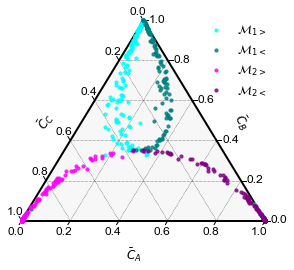

In [47]:
import ternary
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

plt.rcParams['font.family'] = 'Arial'

import ternary
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import matplotlib.colors as mcolors
import pickle
# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl
import torch
import random
from torch.utils.data import DataLoader

#path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3/2_5/"
#path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_nobase2/3_4/"
#path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_nobase2/3_1/"
path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_nobase2/3_1/"

seed = 50
random.seed(seed)

# Load the results
results_path = path + "results.pkl"
with open(results_path, "rb") as file:
    data = pickle.load(file)

# Extract components
results = data['results']
history = data['history']
params = data['params']
execution_time = data['execution_time']

# Assuming you have the model parameters
model = MatrixTreeMarkovICL(
    n_nodes=params['n_nodes'], 
    z_dim=params['D'], 
    L=params['L'], 
    N=params['N']
)

# Load the saved weights
model_path = path + 'model.pt'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model.load_state_dict(torch.load(model_path, map_location=device))

model.to(device)
model.eval()

gmm = GaussianMixtureModel(
    K=params['K'], 
    D=params['D'], 
    L=params['L'], 
    epsilon=params['epsilon'], 
    seed=params['seed'], 
    offset=params['offset']
)

train_data = generate_icl_gmm_data(gmm, params['train_samples'], params['N'], 
                                   novel_classes=False, exact_copy=params['exact_copy'], 
                                   B=params['B'], L=params['L'], shuffle_context=params['shuffle_context'], min_max_choice=params['min_max_choice'], unique_labels = params['unique_labels'])

train_loader = DataLoader(ICLGMMDataset(train_data), batch_size=params['batch_size'],
                          shuffle=True, collate_fn=collate_fn)





# Loop to collect n_samples points
n_samples = 1250
n_samples_2 = 750
p_steady_list = []
targets_list = []
class_list = []
min_max_list = []
model.eval()


with torch.no_grad():
    for i in list(range(n_samples)) + list(range(n_samples+50, n_samples+50+n_samples_2)):
        # Get a single example from the training dataset
        z_seq, labels, targets = train_loader.dataset[i]
        
        # Add batch dimension and move to device
        z_seq = z_seq.unsqueeze(0).to(device)  # Shape: (1, N+1, D)
        labels = labels.unsqueeze(0).to(device)  # Shape: (1, N)
        targets = targets.unsqueeze(0).to(device).long()  # Shape: (1,)
        # print(targets)
        # print(labels)
        # Find which element of labels equals the target
        matching_indices = (labels[0] == targets[0]).nonzero(as_tuple=True)[0]
        if len(matching_indices) > 0:
            class_idx = matching_indices[0].item()
        else:
            class_idx = -1  # No matching class found
        class_list.append(class_idx)
        
        # Flatten z_seq as the model expects
        z_flat = z_seq.reshape(1, -1)  # Shape: (1, (N+1)*D)
        
        # Compute the rate matrix K
        W_mat = model.compute_rate_matrix_W(z_flat)
        p_steady = model.direct_solve_steady_state(W_mat)  # default

        z_array = np.array(z_flat)[0]
        # if np.max(np.array(p_steady)) <= 0.6:
        #     print(z_array)

        if z_array[class_idx] > z_array[1-class_idx]:
            min_max_list.append(1)
        else:
            min_max_list.append(0)

        # Store results
        p_steady_list.append(p_steady.cpu())
        targets_list.append(targets.cpu())

# Convert lists to tensors for easier manipulation
p_steady_all = torch.cat(p_steady_list, dim=0)  # Shape: (n_samples, n_nodes)
targets_all = torch.cat(targets_list, dim=0)  # Shape: (n_samples,)


scale = 1
fs = 12
offset = 0.15

fig, ax = plt.subplots(figsize= 0.6 *  np.array([7, 6]))
#fig.set_size_inches(5, 5)
tax = ternary.TernaryAxesSubplot(scale=scale, ax=ax)
#tax.set_title("Steady State Distribution by Context Class", fontsize=fs)
tax.boundary(linewidth=2.0)
tax.gridlines(multiple=0.2, color="black")


ternary_points = (p_steady_all.numpy() * scale).tolist()

# Get unique classes for coloring
class_array = np.array(class_list)
unique_classes = np.unique(class_array)
colors = ['cyan', 'magenta', 'yellow', 'purple', 'orange', 'brown', 'pink', 'gray', 'cyan']

coloff = 0.5
def adjust_lightness(color, amount=0.5):
    """
    Lightens or darkens the given color.
    amount > 1.0 makes it lighter, amount < 1.0 makes it darker.
    """
    try:
        c = mcolors.cnames[color]
    except:
        c = color
    c = mcolors.to_rgb(c)
    # Convert to HSL (Hue, Saturation, Lightness)
    c = np.array(mcolors.rgb_to_hsv(c))
    # Adjust the lightness (V in HSV)
    c[2] = min(1.0, c[2] * amount)
    return mcolors.hsv_to_rgb(c)

# Plot points colored by class
labeled = set()
for idx, class_idx in enumerate(unique_classes):
    mask = (class_array == class_idx)
    # Get original indices where mask is True
    original_indices = np.where(mask)[0]
    
    for orig_idx in original_indices:
        point = ternary_points[orig_idx]
        marker_shape = 's' if min_max_list[orig_idx] == 0 else 'o'
        amt = 1-coloff if min_max_list[orig_idx] == 0 else 1+coloff   
        color = adjust_lightness(colors[idx], amt)
        # Only add label for first point of each class
        min_max_val = min_max_list[orig_idx]

        # Create unique key for this combination
        combo_key = (int(class_idx), min_max_val)
        
        # Only add label for first point of each (class, min_max) combination
        if combo_key not in labeled:
            suffix = ">" if min_max_val == 1 else "<"
            #label = f"ICL {int(class_idx + 1)}$_{{{suffix}}}$"
            #label = f"$M_{{{int(class_idx + 1)}{suffix}}}$"
            label = f"$\mathcal{{M}}_{{{int(class_idx + 1)}{suffix}}}$"
            labeled.add(combo_key)
        else:
            label = ""


        tax.scatter([point], marker='o', color=color, 
                    label=label, s=10, alpha=0.8, zorder=10)

tax.ticks(axis='lbr', multiple=0.2, linewidth=1, tick_formats="%.1f", offset=0.02, fontsize=fs)
# tax.bottom_axis_label(r"$\pi_A$", fontsize=fs+4, offset=offset)
# tax.right_axis_label(r"$\pi_B$", fontsize=fs+4, offset=offset)
# tax.left_axis_label(r"$\pi_C$", fontsize=fs+4, offset=offset)
tax.bottom_axis_label(r"$\bar{C}_A$", fontsize=fs, offset=offset)
tax.right_axis_label(r"$\bar{C}_B$", fontsize=fs, offset=offset)
tax.left_axis_label(r"$\bar{C}_C$", fontsize=fs, offset=offset)
tax.get_axes().axis('off')
ax = tax.get_axes()
handles, labels = ax.get_legend_handles_labels()
order = [1,0,3,2]
tax.legend([handles[i] for i in order], [labels[i] for i in order], 
           fontsize=fs, frameon=False, ncol=1, loc='upper right')

plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'TernaryPlotBothBranches.png', dpi=300, bbox_inches='tight')

In [2]:
# ============================================================================
# IMPORTS
# ============================================================================
import ternary
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import plotly.graph_objects as go
plt.rcParams['font.family'] = 'Arial'

import ternary
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.colors as mcolors
import pickle
# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl
import torch
import random
from torch.utils.data import DataLoader

#path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3/2_5/"
path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_nobase2/3_5/"


seed = 5
random.seed(seed)

# Load the results
results_path = path + "results.pkl"
with open(results_path, "rb") as file:
    data = pickle.load(file)

# Extract components
results = data['results']
history = data['history']
params = data['params']
execution_time = data['execution_time']

# Assuming you have the model parameters
model = MatrixTreeMarkovICL(
    n_nodes=params['n_nodes'], 
    z_dim=params['D'], 
    L=params['L'], 
    N=params['N']
)

# Load the saved weights
model_path = path + 'model.pt'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model.load_state_dict(torch.load(model_path, map_location=device))

model.to(device)
model.eval()

gmm = GaussianMixtureModel(
    K=params['K'], 
    D=params['D'], 
    L=params['L'], 
    epsilon=params['epsilon'], 
    seed=params['seed'], 
    offset=params['offset']
)

train_data = generate_icl_gmm_data(gmm, params['train_samples'], params['N'], 
                                   novel_classes=False, exact_copy=params['exact_copy'], 
                                   B=params['B'], L=params['L'], shuffle_context=params['shuffle_context'], min_max_choice=params['min_max_choice'], unique_labels = params['unique_labels'])

train_loader = DataLoader(ICLGMMDataset(train_data), batch_size=params['batch_size'],
                          shuffle=True, collate_fn=collate_fn)

# ============================================================================
# CONFIGURATION
# ============================================================================

# Set number of states (2 or 3)
NUM_STATES = 3  # Change to 2 for 2-state case

# Index pairs for K_params access
INDEX_PAIRS = {
    'one': [0, 2],
    'two': [2, 1],
    'three': [0, 1],
    'four': [1, 2],
    'five': [1, 0],
    'six': [2, 0]
}

# Color scheme
VECTOR_COLORS = {
    'A': 'red',
    'B': 'blue',
    'C': 'green'
}

PLANE_COLORS = {
    'ICL1': 'darkturquoise',
    'ICL2': 'magenta'
}

# Visualization parameters
MAX_RANGE = 3
SHOW_LEGEND = False
COLOFF = 0.3  # Color offset for lightness adjustment
NUM_SAMPLES = 100
VEC_SCALE = 0.075 # 0.05, 0.15

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def add_arrow(fig, start, end, color, name, width=5, sizeref=0.6, showlegend=False):
    """Add a 3D arrow to the figure with a cone at the tip."""
    # Arrow shaft
    fig.add_trace(go.Scatter3d(
        x=[start[0], end[0]],
        y=[start[1], end[1]],
        z=[start[2], end[2]],
        mode='lines',
        line=dict(color=color, width=width),
        name=name,
        showlegend=showlegend if name else False
    ))
    
    # Arrowhead cone
    fig.add_trace(go.Cone(
        x=[end[0]], y=[end[1]], z=[end[2]],
        u=[end[0] - start[0]],
        v=[end[1] - start[1]],
        w=[end[2] - start[2]],
        colorscale=[[0, color], [1, color]],
        showscale=False,
        sizemode='absolute',
        sizeref=sizeref,
        showlegend=False
    ))


def get_k_param(model, key):
    """Extract K_params for a given index pair."""
    idx = INDEX_PAIRS[key]
    return model.K_params[idx[0], idx[1], :].detach().numpy()


def add_plane(fig, v1, v2, color, name, max_range, showlegend=False):
    """Add a semi-transparent plane to the figure."""
    t1 = np.linspace(-max_range, max_range, 20)
    t2 = np.linspace(-max_range, max_range, 20)
    T1, T2 = np.meshgrid(t1, t2)
    
    X = T2 * v2[0] + T1 * v1[0]
    Y = T2 * v2[1] + T1 * v1[1]
    Z = T2 * v2[2] + T1 * v1[2]
    
    fig.add_trace(go.Surface(
        x=X, y=Y, z=Z,
        opacity=0.1,
        colorscale=[[0, color], [1, color]],
        showscale=False,
        name=name,
        showlegend=showlegend
    ))


# ============================================================================
# COMPUTE VECTORS AND PROBABILITIES
# ============================================================================

if NUM_STATES == 2:
    # 2-state case: simple K_params extraction
    one_inds = [0, 1]
    two_inds = [1, 0]
    A = model.K_params[one_inds[0], one_inds[1], :].detach().numpy()
    B = model.K_params[two_inds[0], two_inds[1], :].detach().numpy()
    
    vectors = {
        'A': A,
        'B': B
    }
    
elif NUM_STATES == 3:
    # 3-state case: combined vectors from K_params
    A1 = get_k_param(model, 'one') + get_k_param(model, 'two')
    A2 = get_k_param(model, 'three') + get_k_param(model, 'four')
    A3 = get_k_param(model, 'one') + get_k_param(model, 'three')
    
    B1 = get_k_param(model, 'five') + get_k_param(model, 'one')
    B2 = get_k_param(model, 'four') + get_k_param(model, 'six')
    B3 = get_k_param(model, 'four') + get_k_param(model, 'five')
    
    C1 = get_k_param(model, 'six') + get_k_param(model, 'three')
    C2 = get_k_param(model, 'five') + get_k_param(model, 'two')
    C3 = get_k_param(model, 'six') + get_k_param(model, 'two')
    
    vectors = {
        'A1': A1, 'A2': A2, 'A3': A3,
        'B1': B1, 'B2': B2, 'B3': B3,
        'C1': C1, 'C2': C2, 'C3': C3
    }

# # Compute class probabilities
# if NUM_STATES == 2:
#     piA = np.exp(z_flat @ vectors['A'])
#     piB = np.exp(z_flat @ vectors['B'])
#     Z = piA + piB
#     piAf = (piA / Z).item()
#     piBf = (piB / Z).item()
#     print(f"Class probabilities: [A: {piAf:.4f}, B: {piBf:.4f}]")
    
# elif NUM_STATES == 3:
#     piA = np.exp(z_flat @ vectors['A1']) + np.exp(z_flat @ vectors['A2']) + np.exp(z_flat @ vectors['A3'])
#     piB = np.exp(z_flat @ vectors['B1']) + np.exp(z_flat @ vectors['B2']) + np.exp(z_flat @ vectors['B3'])
#     piC = np.exp(z_flat @ vectors['C1']) + np.exp(z_flat @ vectors['C2']) + np.exp(z_flat @ vectors['C3'])
#     Z = piA + piB + piC
#     piAf = (piA / Z).item()
#     piBf = (piB / Z).item()
#     piCf = (piC / Z).item()
#     print(f"Class probabilities: [A: {piAf:.4f}, B: {piBf:.4f}, C: {piCf:.4f}]")


# ============================================================================
# INITIALIZE 3D FIGURE
# ============================================================================

fig = go.Figure()
origin = np.array([0, 0, 0])


# ============================================================================
# ADD VECTOR ARROWS
# ============================================================================

for idx, (name, vec) in enumerate(vectors.items()):
    letter = name[0]
    color = VECTOR_COLORS[letter]
    
    if NUM_STATES == 2:
        # For 2-state: show legend and use names 'A' and 'B'
        display_name = name
        showlegend = SHOW_LEGEND
    else:
        # For 3-state: show legend only for first vector of each group (A, B, C)
        display_name = letter if idx % 3 == 0 else None
        showlegend = (idx % 3 == 0) and SHOW_LEGEND

    vec_scale = VEC_SCALE # 0.05, 0.15
    add_arrow(fig, origin, vec_scale * vec, color, display_name, 
              width=5, sizeref=0.4, showlegend=showlegend)


# ============================================================================
# ADD GEOMETRIC ELEMENTS (PLANES AND LINES)
# ============================================================================

# Add ICL planes
add_plane(fig, 
          v1=np.array([1, 0, 1]), 
          v2=np.array([0, 1, 0]), 
          color=PLANE_COLORS['ICL1'], 
          name='ICL 1', 
          max_range=MAX_RANGE,
          showlegend=SHOW_LEGEND)

add_plane(fig, 
          v1=np.array([0, 1, 1]), 
          v2=np.array([1, 0, 0]), 
          color=PLANE_COLORS['ICL2'], 
          name='ICL 2', 
          max_range=MAX_RANGE,
          showlegend=SHOW_LEGEND)

# Add line through origin and (1,1,1)
t_line = np.linspace(-MAX_RANGE, MAX_RANGE, 100)
line_direction = np.array([1, 1, 1])

fig.add_trace(go.Scatter3d(
    x=t_line * line_direction[0],
    y=t_line * line_direction[1],
    z=t_line * line_direction[2],
    mode='lines',
    line=dict(color='black', width=6),
    name='Line (1,1,1)',
    showlegend=SHOW_LEGEND
))


# ============================================================================
# ADD DATA POINTS FROM TRAIN LOADER
# ============================================================================

scatter_x, scatter_y, scatter_z = [], [], []
point_colors = []

for i in range(NUM_SAMPLES):
    # Get batch data
    z_seq, labels, targets = train_loader.dataset[i]
    z_seq = z_seq.unsqueeze(0).to(device)
    z_flat = z_seq.reshape(1, -1)
    
    # Extract first 3 coordinates
    scatter_x.append(z_flat[0, 0].item())
    scatter_y.append(z_flat[0, 1].item())
    scatter_z.append(z_flat[0, 2].item())
    
    # Determine color based on class matching
    matching_indices = (labels.unsqueeze(0).to(device)[0] == targets.unsqueeze(0).to(device).long()[0]).nonzero(as_tuple=True)[0]
    if len(matching_indices) > 0:
        class_idx = matching_indices[0].item()
    else:
        class_idx = -1  # No matching class found
    z_array = np.array(z_flat)[0]
    class_dominant = 0 if z_array[class_idx] > z_array[1-class_idx] else 1
    lightness_amt = 1 - COLOFF if class_dominant == 1 else 1 + COLOFF
    
    if targets.item() == labels[0].item():
        color = adjust_lightness(PLANE_COLORS['ICL1'], lightness_amt)
    elif targets.item() == labels[1].item():
        color = adjust_lightness(PLANE_COLORS['ICL2'], lightness_amt)
    
    point_colors.append(color)
    
    # Add line from origin to data point
    vec = z_flat[0, 0:3].detach().numpy()
    t = np.linspace(0, 1, 100)
    
    fig.add_trace(go.Scatter3d(
        x=t * vec[0],
        y=t * vec[1],
        z=t * vec[2],
        mode='lines',
        opacity = 1,
        line=dict(color=[color for _ in range(len(t))], width=1),
        showlegend=False
    ))

# Add scatter plot of data points
fig.add_trace(go.Scatter3d(
    x=scatter_x, y=scatter_y, z=scatter_z,
    mode='markers',
    marker=dict(size=4, color=point_colors, opacity=1),
    name='Data pts'
))


# ============================================================================
# CONFIGURE LAYOUT AND DISPLAY
# ============================================================================

fig.update_layout(
    scene=dict(
        xaxis_title="z<sub>1</sub>",
        yaxis_title="z<sub>2</sub>",
        zaxis_title="z<sub>q</sub>",
        xaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 18), title_font = dict(size = 30)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        yaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 18), title_font = dict(size = 30)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        zaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 18), title_font = dict(size = 30)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        aspectmode='cube',
        camera=dict(eye=dict(x=-1.2, y=-1.2, z=-1)),
        bgcolor='white'
    ),
    width=1000,
    height=800,
    showlegend=SHOW_LEGEND,
    margin=dict(l=0, r=0, t=0, b=0), 
    font=dict(family="Arial, sans-serif", size=24, color='black')
)

fig.show()
save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.write_image(save_path + '3DPlotThreeNodesBothBranches.png', scale=2)


  Initialized ICL Attention model (L=128 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: 0.0
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (27/27 active)
  base_W sparsity: 0.000 (9/9 active)
  Parameters: 42


# WTA advantage

In [74]:
# ============================================================================
# IMPORTS
# ============================================================================
import ternary
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import plotly.graph_objects as go
plt.rcParams['font.family'] = 'Arial'

import ternary
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.colors as mcolors
import pickle
# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl
import torch
import random
from torch.utils.data import DataLoader
from models.wta_icl import load_model

seeds = [1,2,3,4,5]
for seed in seeds:
    path = f"/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/wta_3_2_seed/{seed}/"
    try:
        with open(path + "results.pkl", "rb") as f:
            data = pickle.load(f)
    except:
        continue
    
    params = data['params']
    history = data['history']
    
    model = load_model(params, path, print_creation=False)
    needed_dof = 2 * params['D'] * params['N'] * (params['N'] + 1)
    available_dof = model.get_non_zero_count_W()
    dof_diff = available_dof - needed_dof
    
    icl_acc = [v for v in history['icl_acc'] if v is not None][-1]
    if icl_acc > 99:
        print(icl_acc)
        break  # Exits the for loop, keeping current seed's data

print(icl_acc)

# Extract components
results = data['results']
history = data['history']
params = data['params']
execution_time = data['execution_time']


# Load the saved weights
model_path = path + 'model.pt'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model.load_state_dict(torch.load(model_path, map_location=device))

model.to(device)
model.eval()
    
gmm = GaussianMixtureModel(
    K=params['K'], 
    D=params['D'], 
    L=params['L'], 
    epsilon=params['epsilon'], 
    seed=params['seed'], 
    offset=params['offset']
)

train_data = generate_icl_gmm_data(gmm, params['train_samples'], params['N'], 
                                   novel_classes=False, exact_copy=params['exact_copy'], 
                                   B=params['B'], L=params['L'], shuffle_context=params['shuffle_context'], min_max_choice=params['min_max_choice'], unique_labels = params['unique_labels'])

train_loader = DataLoader(ICLGMMDataset(train_data), batch_size=params['batch_size'],
                          shuffle=True, collate_fn=collate_fn)


99.6
99.6


In [75]:
# ============================================================================
# CONFIGURATION
# ============================================================================

# Set number of states (2 or 3)
NUM_STATES = 3  # Change to 2 for 2-state case

# Index pairs for K_params access
INDEX_PAIRS = {
    'one': [0, 2],
    'two': [2, 1],
    'three': [0, 1],
    'four': [1, 2],
    'five': [1, 0],
    'six': [2, 0]
}

# Color scheme
VECTOR_COLORS = {
    'A': 'red',
    'B': 'blue',
    'C': 'green'
}

PLANE_COLORS = {
    'ICL1': 'darkturquoise',
    'ICL2': 'magenta'
}

# Visualization parameters
MAX_RANGE = 3
SHOW_LEGEND = False
COLOFF = 0.3  # Color offset for lightness adjustment
NUM_SAMPLES = 100
VEC_SCALE = 0.3 # 0.05, 0.15

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def add_arrow(fig, start, end, color, name, width=5, sizeref=0.6, showlegend=False):
    """Add a 3D arrow to the figure with a cone at the tip."""
    # Arrow shaft
    fig.add_trace(go.Scatter3d(
        x=[start[0], end[0]],
        y=[start[1], end[1]],
        z=[start[2], end[2]],
        mode='lines',
        line=dict(color=color, width=width),
        name=name,
        showlegend=showlegend if name else False
    ))
    
    # Arrowhead cone
    fig.add_trace(go.Cone(
        x=[end[0]], y=[end[1]], z=[end[2]],
        u=[end[0] - start[0]],
        v=[end[1] - start[1]],
        w=[end[2] - start[2]],
        colorscale=[[0, color], [1, color]],
        showscale=False,
        sizemode='absolute',
        sizeref=sizeref,
        showlegend=False
    ))


def get_k_param(model, key):
    """Extract K_params for a given index pair."""
    idx = INDEX_PAIRS[key]
    return model.K_params[idx[0], idx[1], :].detach().numpy()


def add_plane(fig, v1, v2, color, name, max_range, showlegend=False):
    """Add a semi-transparent plane to the figure."""
    t1 = np.linspace(-max_range, max_range, 20)
    t2 = np.linspace(-max_range, max_range, 20)
    T1, T2 = np.meshgrid(t1, t2)
    
    X = T2 * v2[0] + T1 * v1[0]
    Y = T2 * v2[1] + T1 * v1[1]
    Z = T2 * v2[2] + T1 * v1[2]
    
    fig.add_trace(go.Surface(
        x=X, y=Y, z=Z,
        opacity=0.1,
        colorscale=[[0, color], [1, color]],
        showscale=False,
        name=name,
        showlegend=showlegend
    ))


# ============================================================================
# COMPUTE VECTORS AND PROBABILITIES
# ============================================================================

A = model.W[0,:].detach().numpy() 
B = model.W[1,:].detach().numpy() 
C = model.W[2,:].detach().numpy() 
#D = model.W[3,:].detach().numpy() 

# Plot ONLY A and B as 3D arrows
vectors = {
    'A': A,
    'B': B,
    'C': C,
    # 'D': D,
}
colors = {
    'A': 'red',
    'B': 'blue',
    'C': 'green',
    'D': 'orange'
}

def adjust_lightness(color, amount=0.5):
    """
    Lightens or darkens the given color.
    amount > 1.0 makes it lighter, amount < 1.0 makes it darker.
    """
    try:
        c = mcolors.cnames[color]
    except:
        c = color
    c = mcolors.to_rgb(c)
    # Convert to HSL (Hue, Saturation, Lightness)
    c = np.array(mcolors.rgb_to_hsv(c))
    # Adjust the lightness (V in HSV)
    c[2] = min(1.0, c[2] * amount)
    return mcolors.hsv_to_rgb(c)

# ============================================================================
# INITIALIZE 3D FIGURE
# ============================================================================

fig = go.Figure()
origin = np.array([0, 0, 0])


# ============================================================================
# ADD VECTOR ARROWS
# ============================================================================

for idx, (name, vec) in enumerate(vectors.items()):
    letter = name[0]
    color = VECTOR_COLORS[letter]
    
    if NUM_STATES == 2:
        # For 2-state: show legend and use names 'A' and 'B'
        display_name = name
        showlegend = SHOW_LEGEND
    else:
        # For 3-state: show legend only for first vector of each group (A, B, C)
        display_name = letter if idx % 3 == 0 else None
        showlegend = (idx % 3 == 0) and SHOW_LEGEND

    vec_scale = VEC_SCALE # 0.05, 0.15
    add_arrow(fig, origin, vec_scale * vec, color, display_name, 
              width=5, sizeref=0.4, showlegend=showlegend)


# ============================================================================
# ADD GEOMETRIC ELEMENTS (PLANES AND LINES)
# ============================================================================

# Add ICL planes
add_plane(fig, 
          v1=np.array([1, 0, 1]), 
          v2=np.array([0, 1, 0]), 
          color=PLANE_COLORS['ICL1'], 
          name='ICL 1', 
          max_range=MAX_RANGE,
          showlegend=SHOW_LEGEND)

add_plane(fig, 
          v1=np.array([0, 1, 1]), 
          v2=np.array([1, 0, 0]), 
          color=PLANE_COLORS['ICL2'], 
          name='ICL 2', 
          max_range=MAX_RANGE,
          showlegend=SHOW_LEGEND)

# Add line through origin and (1,1,1)
t_line = np.linspace(-MAX_RANGE, MAX_RANGE, 100)
line_direction = np.array([1, 1, 1])

fig.add_trace(go.Scatter3d(
    x=t_line * line_direction[0],
    y=t_line * line_direction[1],
    z=t_line * line_direction[2],
    mode='lines',
    line=dict(color='black', width=6),
    name='Line (1,1,1)',
    showlegend=SHOW_LEGEND
))


# ============================================================================
# ADD DATA POINTS FROM TRAIN LOADER
# ============================================================================

scatter_x, scatter_y, scatter_z = [], [], []
point_colors = []

# Initialize lists for categorizing samples
icl1_class0_samples = []
icl1_class1_samples = []
icl2_class0_samples = []
icl2_class1_samples = []

for i in range(NUM_SAMPLES):
    # Get batch data
    z_seq, labels, targets = train_loader.dataset[i]
    z_seq = z_seq.unsqueeze(0).to(device)
    z_flat = z_seq.reshape(1, -1)
    
    # Extract first 3 coordinates
    scatter_x.append(z_flat[0, 0].item())
    scatter_y.append(z_flat[0, 1].item())
    scatter_z.append(z_flat[0, 2].item())
    
    # Determine color based on class matching
    matching_indices = (labels.unsqueeze(0).to(device)[0] == targets.unsqueeze(0).to(device).long()[0]).nonzero(as_tuple=True)[0]
    if len(matching_indices) > 0:
        class_idx = matching_indices[0].item()
    else:
        class_idx = -1  # No matching class found
    z_array = np.array(z_flat)[0]
    class_dominant = 0 if z_array[class_idx] > z_array[1-class_idx] else 1
    lightness_amt = 1 - COLOFF if class_dominant == 1 else 1 + COLOFF
    
    # Determine which ICL plane this sample belongs to
    is_icl1 = targets.item() == labels[0].item()
    is_icl2 = targets.item() == labels[1].item()
    
    if is_icl1:
        color = adjust_lightness(PLANE_COLORS['ICL1'], lightness_amt)
        if class_dominant == 0:
            icl1_class0_samples.append(z_flat)
        else:
            icl1_class1_samples.append(z_flat)
    elif is_icl2:
        color = adjust_lightness(PLANE_COLORS['ICL2'], lightness_amt)
        if class_dominant == 0:
            icl2_class0_samples.append(z_flat)
        else:
            icl2_class1_samples.append(z_flat)
    
    point_colors.append(color)
    
    # Add line from origin to data point
    vec = z_flat[0, 0:3].detach().numpy()
    t = np.linspace(0, 1, 100)
    
    fig.add_trace(go.Scatter3d(
        x=t * vec[0],
        y=t * vec[1],
        z=t * vec[2],
        mode='lines',
        opacity = 1,
        line=dict(color=[color for _ in range(len(t))], width=1),
        showlegend=False
    ))

# Add scatter plot of data points
fig.add_trace(go.Scatter3d(
    x=scatter_x, y=scatter_y, z=scatter_z,
    mode='markers',
    marker=dict(size=4, color=point_colors, opacity=1),
    name='Data pts'
))


# ============================================================================
# CONFIGURE LAYOUT AND DISPLAY
# ============================================================================

fig.update_layout(
    scene=dict(
        xaxis_title="z<sub>1</sub>",
        yaxis_title="z<sub>2</sub>",
        zaxis_title="z<sub>q</sub>",
        xaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 16), title_font = dict(size = 25)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        yaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 16), title_font = dict(size = 25)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        zaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 16), title_font = dict(size = 25)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        aspectmode='cube',
        camera=dict(eye=dict(x=-1.2, y=-1.2, z=-1)),
        bgcolor='white'
    ),
    width=1000,
    height=800,
    showlegend=SHOW_LEGEND,
    margin=dict(l=0, r=0, t=0, b=0), 
    font=dict(family="Arial, sans-serif", size=20, color='black')
)

fig.show()
save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.write_image(save_path + '3DPlotWTA32.png', scale=2)

In [97]:


# Dictionary to store results for each sample list
results_dict = {
    'icl1_class0': {'f': [], 'K': [], 'beta': [], 'Y_steady': []},
    'icl1_class1': {'f': [], 'K': [], 'beta': [], 'Y_steady': []},
    'icl2_class0': {'f': [], 'K': [], 'beta': [], 'Y_steady': []},
    'icl2_class1': {'f': [], 'K': [], 'beta': [], 'Y_steady': []}
}

model.eval()
with torch.no_grad():
    # Process icl1_class0_samples
    for sample in icl1_class0_samples:
        z_flat = sample
        
        f, K, beta = model.compute_reaction_rates(z_flat)
        Y_steady = model.winner_takes_all_softplus(f, K, beta)
        
        results_dict['icl1_class0']['f'].append(f.cpu())
        results_dict['icl1_class0']['K'].append(K.cpu())
        results_dict['icl1_class0']['beta'].append(beta.cpu())
        results_dict['icl1_class0']['Y_steady'].append(Y_steady.cpu())
    
    # Process icl1_class1_samples
    for sample in icl1_class1_samples:
        z_flat = sample
        
        f, K, beta = model.compute_reaction_rates(z_flat)
        Y_steady = model.winner_takes_all_softplus(f, K, beta)
        
        results_dict['icl1_class1']['f'].append(f.cpu())
        results_dict['icl1_class1']['K'].append(K.cpu())
        results_dict['icl1_class1']['beta'].append(beta.cpu())
        results_dict['icl1_class1']['Y_steady'].append(Y_steady.cpu())
    
    # Process icl2_class0_samples
    for sample in icl2_class0_samples:
        z_flat = sample
        
        f, K, beta = model.compute_reaction_rates(z_flat)
        Y_steady = model.winner_takes_all_softplus(f, K, beta)
        
        results_dict['icl2_class0']['f'].append(f.cpu())
        results_dict['icl2_class0']['K'].append(K.cpu())
        results_dict['icl2_class0']['beta'].append(beta.cpu())
        results_dict['icl2_class0']['Y_steady'].append(Y_steady.cpu())
    
    # Process icl2_class1_samples
    for sample in icl2_class1_samples:
        z_flat = sample
        
        f, K, beta = model.compute_reaction_rates(z_flat)
        Y_steady = model.winner_takes_all_softplus(f, K, beta)
        
        results_dict['icl2_class1']['f'].append(f.cpu())
        results_dict['icl2_class1']['K'].append(K.cpu())
        results_dict['icl2_class1']['beta'].append(beta.cpu())
        results_dict['icl2_class1']['Y_steady'].append(Y_steady.cpu())

# Compute statistics for each class type
stats_dict = {}
for class_type, data in results_dict.items():
    # Stack all Y_steady tensors for this class type
    Y_steady_stacked = torch.stack(data['Y_steady']).squeeze()  # Shape: [n_samples, 3]
    
    # Compute mean and std for each of the 3 species
    mean_Y = Y_steady_stacked.mean(dim=0).numpy()  # Shape: [3]
    std_Y = Y_steady_stacked.std(dim=0).numpy()    # Shape: [3]
    
    stats_dict[class_type] = {
        'mean': mean_Y,
        'std': std_Y,
        'all_samples': Y_steady_stacked.numpy()
    }


# ============================================================================
# 3D SCATTER PLOT OF STEADY STATE CONCENTRATIONS
# ============================================================================

import plotly.graph_objects as go
import numpy as np

# Create new figure
fig_steady = go.Figure()

# Define class types and their corresponding colors (matching the original scheme)
class_color_mapping = {
    'icl1_class0': adjust_lightness(PLANE_COLORS['ICL1'], 1 + COLOFF),  # lighter ICL1
    'icl1_class1': adjust_lightness(PLANE_COLORS['ICL1'], 1 - COLOFF),  # darker ICL1
    'icl2_class0': adjust_lightness(PLANE_COLORS['ICL2'], 1 + COLOFF),  # lighter ICL2
    'icl2_class1': adjust_lightness(PLANE_COLORS['ICL2'], 1 - COLOFF),  # darker ICL2
}

# class_labels = {
#     'icl1_class0': 'ICL1 Class 0',
#     'icl1_class1': 'ICL1 Class 1', 
#     'icl2_class0': 'ICL2 Class 0',
#     'icl2_class1': 'ICL2 Class 1'
# }

# class_labels = {
#     'icl1_class0': 'ℳ₁ₐ',  # Using Unicode script M and subscripts
#     'icl1_class1': 'ℳ₁ᵦ', 
#     'icl2_class0': 'ℳ₂ₐ',
#     'icl2_class1': 'ℳ₂ᵦ'
# }



# Plot scatter points for each class type
for class_type in ['icl1_class0', 'icl1_class1', 'icl2_class0', 'icl2_class1']:
    samples = stats_dict[class_type]['all_samples']  # Shape: [n_samples, 3]
    
    if len(samples) > 0:
        # Convert color to rgb string for plotly
        color_rgb = class_color_mapping[class_type]
        color_str = f'rgb({int(color_rgb[0]*255)}, {int(color_rgb[1]*255)}, {int(color_rgb[2]*255)})'
        
        fig_steady.add_trace(go.Scatter3d(
            x=samples[:, 0],
            y=samples[:, 1],
            z=samples[:, 2],
            mode='markers',
            marker=dict(size=5, color=color_str, opacity=0.8),
            name=class_labels[class_type],
            showlegend=True
        ))
        
        # Optionally add lines from origin to each point
        for i in range(len(samples)):
            fig_steady.add_trace(go.Scatter3d(
                x=[0, samples[i, 0]],
                y=[0, samples[i, 1]],
                z=[0, samples[i, 2]],
                mode='lines',
                line=dict(color=color_str, width=1),
                opacity=0.3,
                showlegend=False
            ))

# Configure layout
max_val = max([stats_dict[ct]['all_samples'].max() for ct in stats_dict if len(stats_dict[ct]['all_samples']) > 0])
axis_range = [-0.1, max_val * 1.1]
#axis_range = [0.01, 5]


fig_steady.update_layout(
    scene=dict(
        xaxis_title="C̄<sub>A</sub>",
        yaxis_title="C̄<sub>B</sub>",
        zaxis_title="C̄<sub>C</sub>",
        xaxis=dict(showgrid=True, showbackground=False, gridcolor="whitesmoke", 
                   tickfont=dict(size=15), title_font=dict(size=22)),
        yaxis=dict(showgrid=True, showbackground=False, gridcolor="whitesmoke", 
                   tickfont=dict(size=15), title_font=dict(size=22)),
        zaxis=dict(showgrid=True, showbackground=False, gridcolor="whitesmoke", 
                   tickfont=dict(size=15), title_font=dict(size=22)),

        camera=dict(eye=dict(x=2, y=.75, z=1.25)),
        bgcolor='white'
    ),
    width=1000,
    height=800,
    showlegend=False,
    legend=dict(x=0.02, y=0.98, xanchor='left', yanchor='top'),
    margin=dict(l=0, r=0, t=40, b=0),
    #title="Steady State Concentrations (Y_steady) in 3D",
    font=dict(family="Arial, sans-serif", size=20, color='black')
)

fig_steady.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig_steady.write_image(save_path + '3DPlotWTA32SteadyState.png', scale=2)



In [62]:
B_mat = model.B.detach().numpy()
# Analyze specific example
class_name = 'icl2_class1'
element = 10

print("=" * 60)
print(f"Analysis for {class_name}, element {element}")
print("=" * 60)
# Extract arrays from tensors
f_vals = results_dict[class_name]['f'][element].detach().numpy().flatten()
K_vals = results_dict[class_name]['K'][element].detach().numpy().flatten()
beta_vals = results_dict[class_name]['beta'][element].detach().numpy().flatten()
Y_vals = results_dict[class_name]['Y_steady'][element].detach().numpy().flatten()

# Display in column form
print(f"{'Species':<10} {'f':<15} {'K':<15} {'β':<15} {'Y_steady':<15}")
print("-" * 70)
for i in range(len(f_vals)):
    print(f"{i:<10} {f_vals[i]:<15.6f} {K_vals[i]:<15.6f} {beta_vals[i]:<15.6f} {Y_vals[i]:<15.6f}")
print()

# Compute and display output
output = np.dot(results_dict[class_name]['Y_steady'][element], B_mat)
print(f"Output (Y·B):          {output}")
print("=" * 60)

Analysis for icl2_class1, element 10
Species    f               K               β               Y_steady       
----------------------------------------------------------------------
0          170.748108      0.053755        0.447564        40.962158      
1          0.024747        0.262854        0.078753        0.000000       
2          0.000000        0.058409        0.390006        0.000000       

Output (Y·B):          [[-56.111794  52.903217]]


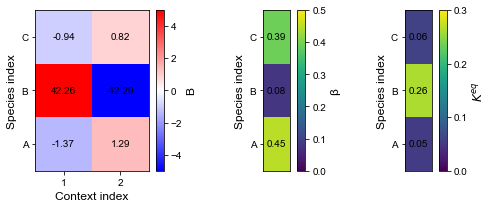

In [96]:
B_mat = model.B.detach().numpy()

# Reshape beta_vals and K_vals for visualization
beta_mat = beta_vals.reshape(-1, 1)
K_mat = K_vals.reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(7, 3))
fs = 12
# Plot B matrix
im0 = axes[0].imshow(B_mat, cmap='bwr', aspect='auto', origin='lower', vmin=-5, vmax=5)
cbar0 = plt.colorbar(im0, ax=axes[0])
cbar0.set_label("B", size=fs)
axes[0].set_xlabel('Context index', fontsize=fs)
axes[0].set_xticks([0, 1], ['1', '2'])
axes[0].set_ylabel('Species index', fontsize=fs)
axes[0].set_yticks([0, 1, 2], ['A', 'B', 'C'])
#axes[0].set_title('B Matrix', fontsize=fs)

# Add text annotations showing the values
for i in range(B_mat.shape[0]):
    for j in range(B_mat.shape[1]):
        text = axes[0].text(j, i, f'{B_mat[i, j]:.2f}',
                           ha="center", va="center", color="black", fontsize=10)

# Plot beta values
im1 = axes[1].imshow(beta_mat, cmap='viridis', aspect=2, origin='lower', vmin = 0, vmax = 0.5)
cbar1 = plt.colorbar(im1, ax=axes[1])
cbar1.set_label("β", size=fs)
axes[1].set_xlabel('', fontsize=fs)
axes[1].set_xticks([])
axes[1].set_ylabel('Species index', fontsize=fs)
axes[1].set_yticks([0, 1, 2], ['A', 'B', 'C'])
#axes[1].set_title('β values', fontsize=fs)

# Add text annotations for beta values
for i in range(beta_mat.shape[0]):
    text = axes[1].text(0, i, f'{beta_mat[i, 0]:.2f}',
                       ha="center", va="center", color="black", fontsize=10)

# Plot K values
im2 = axes[2].imshow(K_mat, cmap='viridis', aspect=2, origin='lower', vmin = 0, vmax = 0.3)
cbar2 = plt.colorbar(im2, ax=axes[2], ticks = [0, 0.1, 0.2, 0.3])
cbar2.set_label(r"$K^{eq}$", size=fs)
axes[2].set_xlabel('', fontsize=fs)
axes[2].set_xticks([])
axes[2].set_ylabel('Species index', fontsize=fs)
axes[2].set_yticks([0, 1, 2], ['A', 'B', 'C'])
#axes[2].set_title(r"$K^{eq}$", size=fs)

# Add text annotations for K values
for i in range(K_mat.shape[0]):
    text = axes[2].text(0, i, f'{K_mat[i, 0]:.2f}',
                       ha="center", va="center", color="black", fontsize=10)

plt.tight_layout()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'WTAMatrices.png', dpi=300, bbox_inches='tight')

# Trained vs constructed

In [1]:
import ternary
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

plt.rcParams['font.family'] = 'Arial'

import ternary
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import matplotlib.colors as mcolors
import pickle
# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl
import torch
import random
from torch.utils.data import DataLoader

#path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3/2_5/"
#path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_nobase2/3_4/"
#path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_nobase2/3_1/"
path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_3_nobase2/3_2/"

seed = 50
random.seed(seed)

# Load the results
results_path = path + "results.pkl"
with open(results_path, "rb") as file:
    data = pickle.load(file)

# Extract components
results = data['results']
history = data['history']
params = data['params']
execution_time = data['execution_time']

# Assuming you have the model parameters
model = MatrixTreeMarkovICL(
    n_nodes=params['n_nodes'], 
    z_dim=params['D'], 
    L=params['L'], 
    N=params['N']
)

# Load the saved weights
model_path = path + 'model.pt'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model.load_state_dict(torch.load(model_path, map_location=device))

model.to(device)
model.eval()

gmm = GaussianMixtureModel(
    K=params['K'], 
    D=params['D'], 
    L=params['L'], 
    epsilon=params['epsilon'], 
    seed=params['seed'], 
    offset=params['offset']
)

train_data = generate_icl_gmm_data(gmm, params['train_samples'], params['N'], 
                                   novel_classes=False, exact_copy=params['exact_copy'], 
                                   B=params['B'], L=params['L'], shuffle_context=params['shuffle_context'], min_max_choice=params['min_max_choice'], unique_labels = params['unique_labels'])

train_loader = DataLoader(ICLGMMDataset(train_data), batch_size=params['batch_size'],
                          shuffle=True, collate_fn=collate_fn)




  Initialized ICL Attention model (L=128 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: 0.0
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (27/27 active)
  base_W sparsity: 0.000 (9/9 active)
  Parameters: 42


In [5]:
import numpy as np

# Index pairs for K_params access
INDEX_PAIRS = {
    'one': [0, 2],
    'two': [2, 1],
    'three': [0, 1],
    'four': [1, 2],
    'five': [1, 0],
    'six': [2, 0]
}

def get_k_param(model, key):
    """Extract K_params for a given index pair."""
    idx = INDEX_PAIRS[key]
    return model.K_params[idx[0], idx[1], :].detach().numpy()


EQUATIONS = {
    'A1': [0, 1],      # one + two
    'A2': [2, 3],      # three + four
    'A3': [0, 2],      # one + three
    'B1': [4, 0],      # five + one
    'B2': [3, 5],      # four + six
    'B3': [3, 4],      # four + five
    'C1': [5, 2],      # six + three
    'C2': [4, 1],      # five + two
    'C3': [5, 1],      # six + two
}

def solve_for_K(specified):
    """
    Solve for K_1 through K_6 given 6 specified equation values.
    
    Parameters
    ----------
    specified : dict
        e.g., {'A1': [1,0,0], 'A2': [0,1,0], 'B1': [0,0,1], ...}
    
    Returns
    -------
    K : ndarray of shape (6, 3)
        K[i] = K_{i+1} vector
    """
    if len(specified) != 6:
        raise ValueError(f"Need exactly 6 equations, got {len(specified)}")
    
    # Build coefficient matrix and RHS
    M = np.zeros((6, 6))
    b = np.zeros((6, 3))
    
    for i, (name, value) in enumerate(specified.items()):
        for k_idx in EQUATIONS[name]:
            M[i, k_idx] = 1
        b[i] = value
    

    # Check if system is solvable
    if np.abs(np.linalg.det(M)) < 1e-10:
        raise ValueError("System is singular - choose different equations")
    
    # Solve for each component
    K = np.linalg.solve(M, b)
    return K

def verify_solution(K, specified):
    """Verify the solution satisfies the specified equations."""
    print("Verification:")
    for name, target in specified.items():
        computed = sum(K[idx] for idx in EQUATIONS[name])
        error = np.linalg.norm(computed - target)
        print(f"  {name}: target={target}, computed={computed}, error={error:.2e}")

def compute_all_equations(K):
    """Compute all 9 equation values from K vectors."""
    results = {}
    for name, indices in EQUATIONS.items():
        results[name] = sum(K[idx] for idx in indices)
    return results

# Mapping from K vector index (0-5) to INDEX_PAIRS key
K_INDEX_TO_KEY = {
    0: 'one',    # K_1
    1: 'two',    # K_2
    2: 'three',  # K_3
    3: 'four',   # K_4
    4: 'five',   # K_5
    5: 'six',    # K_6
}

def set_k_param(model, key, value):
    """Set K_params for a given index pair key."""
    idx = INDEX_PAIRS[key]
    with torch.no_grad():
        model.K_params[idx[0], idx[1], :] = torch.tensor(value, dtype=model.K_params.dtype)

def set_B(model, B):
    """Set B for a given index pair key."""
    with torch.no_grad():
        model.B[:,:] = torch.tensor(B, dtype=model.B.dtype)

def zero_base_rates(model):
    """Zero out all base rate parameters in the model."""
    with torch.no_grad():
        model.base_log_rates_W.fill_(0.0)



def set_k_params_from_solution(model, K):
    """
    Set all K_params in the model from solved K vectors.
    
    Parameters
    ----------
    model : MatrixTreeMarkovICL
        The model to update
    K : ndarray of shape (6, 3)
        Solved K vectors where K[i] corresponds to K_{i+1}
    """
    for i in range(6):
        key = K_INDEX_TO_KEY[i]
        set_k_param(model, key, K[i])


def get_all_k_params(model):
    """Get all K vectors from model as (6, 3) array."""
    K = np.zeros((6, 3))
    for i in range(6):
        key = K_INDEX_TO_KEY[i]
        K[i] = get_k_param(model, key)
    return K

# # === Example usage ===

# Specify any 6 of the 9 equations
my_constraints = {
    'A1': [1, -2, 1],
    'A2': [-1, 2, -1],
    'B1': [-2, 1, 1],
    'B2': [2, -1, -1],
    'A3': 1 * np.array([1 , 1, 1]),
    'C3': 1 * np.array([-1 , -1, -1]),
}

K = solve_for_K(my_constraints)
print(K)
verify_solution(K, my_constraints)


K = [[5, -5, 0],
 [0.0, -0.0, 0.0],
 [0.0, 0.0, -0.0],
 [-2, -2, 4],
 [2, 2, -4],
[-5, 5, 0]]


# Define the vector to rotate
m = -np.array([-2, 1, 1])
mp = np.array([1,-2,1])
# Define rotation axis (normalized)
v = np.array([1, 1, 1])
v = v / np.linalg.norm(v)

# Define rotation angle
theta = 2 * np.pi / 3  # Example angle, adjust as needed

# Rodrigues' rotation formula
m_rotated = m * np.cos(theta) + np.cross(v, m) * np.sin(theta) + v * np.dot(v, m) * (1 - np.cos(theta))
v = m_rotated

v = mp 
k1 = v
k2 = np.zeros(3)
k3 = np.zeros(3)
k5 = m - k1 
k4 = - k5 
k6 = - k1 
K = [k1, k2, k3, k4, k5, k6]

K = 10 * np.array(K)
# Reconstruct A, B, C vectors from K definition
K_array = np.array(K)
A1 = K_array[0] + K_array[1]  # one + two
A2 = K_array[2] + K_array[3]  # three + four
A3 = K_array[0] + K_array[2]  # one + three
B1 = K_array[4] + K_array[0]  # five + one
B2 = K_array[3] + K_array[5]  # four + six
B3 = K_array[3] + K_array[4]  # four + five
C1 = K_array[5] + K_array[2]  # six + three
C2 = K_array[4] + K_array[1]  # five + two
C3 = K_array[5] + K_array[1]  # six + two

print("Reconstructed vectors:")
print(f"A1: {A1}")
print(f"A2: {A2}")
print(f"A3: {A3}")
print(f"B1: {B1}")
print(f"B2: {B2}")
print(f"B3: {B3}")
print(f"C1: {C1}")
print(f"C2: {C2}")
print(f"C3: {C3}")


B_mat = np.array([[25, -25], [-50, 50], [25, -25]])

# array([[ 19.271326, -19.137005],
#        [-44.546497,  44.574326],
#        [ 17.599525, -17.500738]], dtype=float32)

# Create model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = MatrixTreeMarkovICL(
    n_nodes=3, 
    z_dim=1, 
    L=1, 
    N=2,
    learn_base_rates=False,  # Don't learn base rates
    sparsity_rho_edge=1.0,   # No sparsity
    sparsity_rho_all=1.0,
    sparsity_rho_edge_base_W=1.0,
)

# Set K params from solution and zero base rates
set_k_params_from_solution(model, K)
zero_base_rates(model)
set_B(model, B_mat)

# Move to device and set eval mode
model.to(device)
model.eval()

# Verify
print("K vectors set in model:")
for i in range(6):
    key = K_INDEX_TO_KEY[i]
    print(f"  K_{i+1} ({key}): {get_k_param(model, key)}")



[[ 3.  -1.5  1.5]
 [-2.  -0.5 -0.5]
 [-2.   2.5 -0.5]
 [ 1.  -0.5 -0.5]
 [-5.   2.5 -0.5]
 [ 1.  -0.5 -0.5]]
Verification:
  A1: target=[1, -2, 1], computed=[ 1. -2.  1.], error=0.00e+00
  A2: target=[-1, 2, -1], computed=[-1.  2. -1.], error=0.00e+00
  B1: target=[-2, 1, 1], computed=[-2.  1.  1.], error=0.00e+00
  B2: target=[2, -1, -1], computed=[ 2. -1. -1.], error=0.00e+00
  A3: target=[1 1 1], computed=[1. 1. 1.], error=0.00e+00
  C3: target=[-1 -1 -1], computed=[-1. -1. -1.], error=0.00e+00
Reconstructed vectors:
A1: [ 10. -20.  10.]
A2: [-10. -10.  20.]
A3: [ 10. -20.  10.]
B1: [ 20. -10. -10.]
B2: [-20.  10.  10.]
B3: [0. 0. 0.]
C1: [-10.  20. -10.]
C2: [ 10.  10. -20.]
C3: [-10.  20. -10.]
  Initialized ICL Attention model (L=1 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: False
  Base mask value: 0.0
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (27/27 active)
  base_W spa

<>:114: SyntaxWarning: invalid escape sequence '\m'
<>:114: SyntaxWarning: invalid escape sequence '\m'
/var/folders/vz/mzz963fn35g6stbyn1w_x0jc0000gn/T/ipykernel_22892/1214865598.py:114: SyntaxWarning: invalid escape sequence '\m'
  label = f"$\mathcal{{M}}_{{{int(class_idx + 1)}{suffix}}}$"


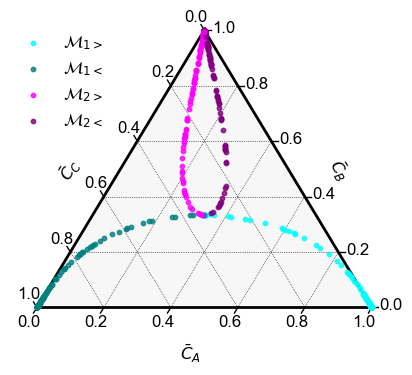

In [6]:

# Loop to collect n_samples points
n_samples = 1250
n_samples_2 = 70
p_steady_list = []
targets_list = []
class_list = []
min_max_list = []
model.eval()


with torch.no_grad():
    for i in list(range(n_samples)) + list(range(n_samples+50, n_samples+50+n_samples_2)):
        # Get a single example from the training dataset
        z_seq, labels, targets = train_loader.dataset[i]
        
        # Add batch dimension and move to device
        z_seq = z_seq.unsqueeze(0).to(device)  # Shape: (1, N+1, D)
        labels = labels.unsqueeze(0).to(device)  # Shape: (1, N)
        targets = targets.unsqueeze(0).to(device).long()  # Shape: (1,)
        # print(targets)
        # print(labels)
        # Find which element of labels equals the target
        matching_indices = (labels[0] == targets[0]).nonzero(as_tuple=True)[0]
        if len(matching_indices) > 0:
            class_idx = matching_indices[0].item()
        else:
            class_idx = -1  # No matching class found
        class_list.append(class_idx)
        
        # Flatten z_seq as the model expects
        z_flat = z_seq.reshape(1, -1)  # Shape: (1, (N+1)*D)
        
        # Compute the rate matrix K
        W_mat = model.compute_rate_matrix_W(z_flat)
        p_steady = model.direct_solve_steady_state(W_mat)  # default

        z_array = np.array(z_flat)[0]
        # if np.max(np.array(p_steady)) <= 0.6:
        #     print(z_array)

        if z_array[class_idx] > z_array[1-class_idx]:
            min_max_list.append(1)
        else:
            min_max_list.append(0)

        # Store results
        p_steady_list.append(p_steady.cpu())
        targets_list.append(targets.cpu())

# Convert lists to tensors for easier manipulation
p_steady_all = torch.cat(p_steady_list, dim=0)  # Shape: (n_samples, n_nodes)
targets_all = torch.cat(targets_list, dim=0)  # Shape: (n_samples,)


scale = 1
fs = 12
offset = 0.15

fig, ax = plt.subplots(figsize= 0.6 *  np.array([7, 6]))
#fig.set_size_inches(5, 5)
tax = ternary.TernaryAxesSubplot(scale=scale, ax=ax)
#tax.set_title("Steady State Distribution by Context Class", fontsize=fs)
tax.boundary(linewidth=2.0)
tax.gridlines(multiple=0.2, color="black")


ternary_points = (p_steady_all.numpy() * scale).tolist()

# Get unique classes for coloring
class_array = np.array(class_list)
unique_classes = np.unique(class_array)
colors = ['cyan', 'magenta', 'yellow', 'purple', 'orange', 'brown', 'pink', 'gray', 'cyan']

coloff = 0.5
def adjust_lightness(color, amount=0.5):
    """
    Lightens or darkens the given color.
    amount > 1.0 makes it lighter, amount < 1.0 makes it darker.
    """
    try:
        c = mcolors.cnames[color]
    except:
        c = color
    c = mcolors.to_rgb(c)
    # Convert to HSL (Hue, Saturation, Lightness)
    c = np.array(mcolors.rgb_to_hsv(c))
    # Adjust the lightness (V in HSV)
    c[2] = min(1.0, c[2] * amount)
    return mcolors.hsv_to_rgb(c)

# Plot points colored by class
labeled = set()
for idx, class_idx in enumerate(unique_classes):
    mask = (class_array == class_idx)
    # Get original indices where mask is True
    original_indices = np.where(mask)[0]
    
    for orig_idx in original_indices:
        point = ternary_points[orig_idx]
        marker_shape = 's' if min_max_list[orig_idx] == 0 else 'o'
        amt = 1-coloff if min_max_list[orig_idx] == 0 else 1+coloff   
        color = adjust_lightness(colors[idx], amt)
        # Only add label for first point of each class
        min_max_val = min_max_list[orig_idx]

        # Create unique key for this combination
        combo_key = (int(class_idx), min_max_val)
        
        # Only add label for first point of each (class, min_max) combination
        if combo_key not in labeled:
            suffix = ">" if min_max_val == 1 else "<"
            #label = f"ICL {int(class_idx + 1)}$_{{{suffix}}}$"
            #label = f"$M_{{{int(class_idx + 1)}{suffix}}}$"
            label = f"$\mathcal{{M}}_{{{int(class_idx + 1)}{suffix}}}$"
            labeled.add(combo_key)
        else:
            label = ""


        tax.scatter([point], marker='o', color=color, 
                    label=label, s=10, alpha=0.8, zorder=10)

tax.ticks(axis='lbr', multiple=0.2, linewidth=1, tick_formats="%.1f", offset=0.02, fontsize=fs)
# tax.bottom_axis_label(r"$\pi_A$", fontsize=fs+4, offset=offset)
# tax.right_axis_label(r"$\pi_B$", fontsize=fs+4, offset=offset)
# tax.left_axis_label(r"$\pi_C$", fontsize=fs+4, offset=offset)
tax.bottom_axis_label(r"$\bar{C}_A$", fontsize=fs, offset=offset)
tax.right_axis_label(r"$\bar{C}_B$", fontsize=fs, offset=offset)
tax.left_axis_label(r"$\bar{C}_C$", fontsize=fs, offset=offset)
tax.get_axes().axis('off')
ax = tax.get_axes()
handles, labels = ax.get_legend_handles_labels()
order = [0,1,2,3]
tax.legend([handles[i] for i in order], [labels[i] for i in order], 
           fontsize=fs, frameon=False, ncol=1, loc='upper left', bbox_to_anchor=(-0.05, 1.0))

plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.savefig(save_path + 'TernaryPlotTrained.png', dpi=300, bbox_inches='tight')
fig.savefig(save_path + 'TernaryPlotConstructed.png', dpi=300, bbox_inches='tight')

In [15]:
# ============================================================================
# IMPORTS
# ============================================================================
import ternary
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

import plotly.graph_objects as go
plt.rcParams['font.family'] = 'Arial'

import ternary
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.colors as mcolors
import pickle
# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl
import kaleido
import torch
import random
from torch.utils.data import DataLoader


# ============================================================================
# CONFIGURATION
# ============================================================================

# Set number of states (2 or 3)
NUM_STATES = 3  # Change to 2 for 2-state case

# Index pairs for K_params access
INDEX_PAIRS = {
    'one': [0, 2],
    'two': [2, 1],
    'three': [0, 1],
    'four': [1, 2],
    'five': [1, 0],
    'six': [2, 0]
}

# Color scheme
VECTOR_COLORS = {
    'A': 'red',
    'B': 'blue',
    'C': 'green'
}

PLANE_COLORS = {
    'ICL1': 'darkturquoise',
    'ICL2': 'magenta'
}

# Visualization parameters
MAX_RANGE = 3
SHOW_LEGEND = False
COLOFF = 0.3  # Color offset for lightness adjustment
NUM_SAMPLES = 100
VEC_SCALE = 0.1 # 0.05, 0.15

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def add_arrow(fig, start, end, color, name, width=5, sizeref=0.6, showlegend=False):
    """Add a 3D arrow to the figure with a cone at the tip."""
    # Arrow shaft
    fig.add_trace(go.Scatter3d(
        x=[start[0], end[0]],
        y=[start[1], end[1]],
        z=[start[2], end[2]],
        mode='lines',
        line=dict(color=color, width=width),
        name=name,
        showlegend=showlegend if name else False
    ))
    
    # Arrowhead cone
    fig.add_trace(go.Cone(
        x=[end[0]], y=[end[1]], z=[end[2]],
        u=[end[0] - start[0]],
        v=[end[1] - start[1]],
        w=[end[2] - start[2]],
        colorscale=[[0, color], [1, color]],
        showscale=False,
        sizemode='absolute',
        sizeref=sizeref,
        showlegend=False
    ))


def get_k_param(model, key):
    """Extract K_params for a given index pair."""
    idx = INDEX_PAIRS[key]
    return model.K_params[idx[0], idx[1], :].detach().numpy()


def add_plane(fig, v1, v2, color, name, max_range, showlegend=False):
    """Add a semi-transparent plane to the figure."""
    t1 = np.linspace(-max_range, max_range, 20)
    t2 = np.linspace(-max_range, max_range, 20)
    T1, T2 = np.meshgrid(t1, t2)
    
    X = T2 * v2[0] + T1 * v1[0]
    Y = T2 * v2[1] + T1 * v1[1]
    Z = T2 * v2[2] + T1 * v1[2]
    
    fig.add_trace(go.Surface(
        x=X, y=Y, z=Z,
        opacity=0.1,
        colorscale=[[0, color], [1, color]],
        showscale=False,
        name=name,
        showlegend=showlegend
    ))


# ============================================================================
# COMPUTE VECTORS AND PROBABILITIES
# ============================================================================

if NUM_STATES == 2:
    # 2-state case: simple K_params extraction
    one_inds = [0, 1]
    two_inds = [1, 0]
    A = model.K_params[one_inds[0], one_inds[1], :].detach().numpy()
    B = model.K_params[two_inds[0], two_inds[1], :].detach().numpy()
    
    vectors = {
        'A': A,
        'B': B
    }
    
elif NUM_STATES == 3:
    # 3-state case: combined vectors from K_params
    A1 = get_k_param(model, 'one') + get_k_param(model, 'two')
    A2 = get_k_param(model, 'three') + get_k_param(model, 'four')
    A3 = get_k_param(model, 'one') + get_k_param(model, 'three')
    
    B1 = get_k_param(model, 'five') + get_k_param(model, 'one')
    B2 = get_k_param(model, 'four') + get_k_param(model, 'six')
    B3 = get_k_param(model, 'four') + get_k_param(model, 'five')
    
    C1 = get_k_param(model, 'six') + get_k_param(model, 'three')
    C2 = get_k_param(model, 'five') + get_k_param(model, 'two')
    C3 = get_k_param(model, 'six') + get_k_param(model, 'two')
    
    vectors = {
        'A1': A1, 'A2': A2, 'A3': A3,
        'B1': B1, 'B2': B2, 'B3': B3,
        'C1': C1, 'C2': C2, 'C3': C3
    }



# ============================================================================
# INITIALIZE 3D FIGURE
# ============================================================================

fig = go.Figure()
origin = np.array([0, 0, 0])


# ============================================================================
# ADD VECTOR ARROWS
# ============================================================================

for idx, (name, vec) in enumerate(vectors.items()):
    letter = name[0]
    color = VECTOR_COLORS[letter]
    
    if NUM_STATES == 2:
        # For 2-state: show legend and use names 'A' and 'B'
        display_name = name
        showlegend = SHOW_LEGEND
    else:
        # For 3-state: show legend only for first vector of each group (A, B, C)
        display_name = letter if idx % 3 == 0 else None
        showlegend = (idx % 3 == 0) and SHOW_LEGEND

    vec_scale = VEC_SCALE # 0.05, 0.15
    add_arrow(fig, origin, vec_scale * vec, color, display_name, 
              width=5, sizeref=0.4, showlegend=showlegend)


# ============================================================================
# ADD GEOMETRIC ELEMENTS (PLANES AND LINES)
# ============================================================================

# Add ICL planes
add_plane(fig, 
          v1=np.array([1, 0, 1]), 
          v2=np.array([0, 1, 0]), 
          color=PLANE_COLORS['ICL1'], 
          name='ICL 1', 
          max_range=MAX_RANGE,
          showlegend=SHOW_LEGEND)

add_plane(fig, 
          v1=np.array([0, 1, 1]), 
          v2=np.array([1, 0, 0]), 
          color=PLANE_COLORS['ICL2'], 
          name='ICL 2', 
          max_range=MAX_RANGE,
          showlegend=SHOW_LEGEND)

# Add line through origin and (1,1,1)
t_line = np.linspace(-MAX_RANGE, MAX_RANGE, 100)
line_direction = np.array([1, 1, 1])

fig.add_trace(go.Scatter3d(
    x=t_line * line_direction[0],
    y=t_line * line_direction[1],
    z=t_line * line_direction[2],
    mode='lines',
    line=dict(color='black', width=6),
    name='Line (1,1,1)',
    showlegend=SHOW_LEGEND
))


# ============================================================================
# ADD DATA POINTS FROM TRAIN LOADER
# ============================================================================

scatter_x, scatter_y, scatter_z = [], [], []
point_colors = []

for i in range(NUM_SAMPLES):
    # Get batch data
    z_seq, labels, targets = train_loader.dataset[i]
    z_seq = z_seq.unsqueeze(0).to(device)
    z_flat = z_seq.reshape(1, -1)
    
    # Extract first 3 coordinates
    scatter_x.append(z_flat[0, 0].item())
    scatter_y.append(z_flat[0, 1].item())
    scatter_z.append(z_flat[0, 2].item())
    
    # Determine color based on class matching
    matching_indices = (labels.unsqueeze(0).to(device)[0] == targets.unsqueeze(0).to(device).long()[0]).nonzero(as_tuple=True)[0]
    if len(matching_indices) > 0:
        class_idx = matching_indices[0].item()
    else:
        class_idx = -1  # No matching class found
    z_array = np.array(z_flat)[0]
    class_dominant = 0 if z_array[class_idx] > z_array[1-class_idx] else 1
    lightness_amt = 1 - COLOFF if class_dominant == 1 else 1 + COLOFF
    
    if targets.item() == labels[0].item():
        color = adjust_lightness(PLANE_COLORS['ICL1'], lightness_amt)
    elif targets.item() == labels[1].item():
        color = adjust_lightness(PLANE_COLORS['ICL2'], lightness_amt)
    
    point_colors.append(color)
    
    # Add line from origin to data point
    vec = z_flat[0, 0:3].detach().numpy()
    t = np.linspace(0, 1, 100)
    
    fig.add_trace(go.Scatter3d(
        x=t * vec[0],
        y=t * vec[1],
        z=t * vec[2],
        mode='lines',
        opacity = 1,
        line=dict(color=[color for _ in range(len(t))], width=1),
        showlegend=False
    ))

# Add scatter plot of data points
fig.add_trace(go.Scatter3d(
    x=scatter_x, y=scatter_y, z=scatter_z,
    mode='markers',
    marker=dict(size=4, color=point_colors, opacity=1),
    name='Data pts'
))


# ============================================================================
# CONFIGURE LAYOUT AND DISPLAY
# ============================================================================

fig.update_layout(
    scene=dict(
        xaxis_title="z<sub>1</sub>",
        yaxis_title="z<sub>2</sub>",
        zaxis_title="z<sub>q</sub>",
        xaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 16), title_font = dict(size = 25)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        yaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 16), title_font = dict(size = 25)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        zaxis=dict(range=[-MAX_RANGE, MAX_RANGE], showgrid=True, showbackground=False, gridcolor="whitesmoke", tickfont = dict(size = 16), title_font = dict(size = 25)),#, title_font=dict(family="Arial, sans-serif", size=24, color='black')),
        aspectmode='cube',
        camera=dict(
            #eye=dict(x=-1.2, y=-1.2, z=-1)
            eye=dict(x=-1.1, y=-1.1, z=-1.1)
            ),
        bgcolor='white'
    ),
    width=1000,
    height=800,
    showlegend=SHOW_LEGEND,
    margin=dict(l=0, r=0, t=0, b=0), 
    font=dict(family="Arial, sans-serif", size=20, color='black')
)

fig.show()
save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.write_image(save_path + '3DPlotThreeNodesTrained.png', scale=2)
fig.write_image(save_path + '3DPlotThreeNodesConstructed.png', scale=2)


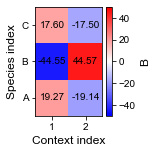

In [105]:
B_mat = model.B.detach().numpy()

fig, ax = plt.subplots(figsize=(1.5, 2))
fs = 12


im = ax.imshow(B_mat, cmap='bwr', aspect='auto', origin='lower', vmin = -50, vmax = 50)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("B", size = fs)
ax.set_xlabel('Context index', fontsize=fs)
ax.set_xticks([0,1], ['1','2'])
ax.set_ylabel('Species index', fontsize=fs)
ax.set_yticks([0, 1, 2], ['A', 'B', 'C'])

# Add text annotations showing the values
for i in range(B_mat.shape[0]):
    for j in range(B_mat.shape[1]):
        text = ax.text(j, i, f'{B_mat[i, j]:.2f}',
                           ha="center", va="center", color="black", fontsize=10)


save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'BMatrixTrained.png', dpi=300, bbox_inches='tight')

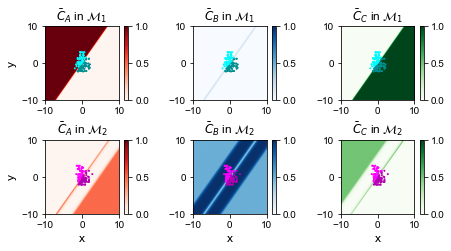

In [11]:
import numpy as np
import torch
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Arial'

n_coords = 200
rr = 10
num_samples = 250
fs = 12

# Get input dimension from params (assumes model/params loaded from previous cell)
input_dim = (params['N'] + 1) * params['D']

# Create 2x3 axes for plotting with reduced spacing
fig, axes = plt.subplots(2, 3, figsize=(6.5, 3.5))#, gridspec_kw={'wspace': 0.15})

x_coords = np.linspace(-rr, rr, n_coords)
y_coords = np.linspace(-rr, rr, n_coords)

# Define basis vectors - pad to full input dimension
def make_basis(vec):
    b = np.zeros(input_dim)
    b[:len(vec)] = vec
    return b

e1x = np.array([0, 1, 0])
e1x = e1x / np.linalg.norm(e1x)
e1y = np.array([1, 0, 1])
e1y = e1y / np.linalg.norm(e1y)
e2x = np.array([1, 0, 0])
e2x = e2x / np.linalg.norm(e2x)
e2y = np.array([0, 1, 1])
e2y= e2y / np.linalg.norm(e2y)

def proj_to_basis(point, basis_set):
    px = np.dot(point, basis_set[0])
    py = np.dot(point, basis_set[1])
    return np.array([px, py])

basis_options = [
    (make_basis(e1x), make_basis(e1y)),
    (make_basis(e2x), make_basis(e2y)),
]

component_titles = [r"$\bar{C}_A$", r"$\bar{C}_B$", r"$\bar{C}_C$"]



random.seed(10)
colors_1 = []
colors_2 = []
points_1x = []
points_1y = []
points_2x = []
points_2y = []
for i in range(num_samples):
    # Get batch data
    z_seq, labels, targets = train_loader.dataset[i]
    z_seq = z_seq.unsqueeze(0).to(device)
    z_flat = z_seq.reshape(1, -1)
    z_vec = z_flat[0, 0:3].detach().numpy()
    
    
    # Determine color based on class matching
    matching_indices = (labels.unsqueeze(0).to(device)[0] == targets.unsqueeze(0).to(device).long()[0]).nonzero(as_tuple=True)[0]
    if len(matching_indices) > 0:
        class_idx = matching_indices[0].item()
    else:
        class_idx = -1  # No matching class found
    z_array = np.array(z_flat)[0]
    class_dominant = 0 if z_array[class_idx] > z_array[1-class_idx] else 1
    lightness_amt = 1 - COLOFF if class_dominant == 1 else 1 + COLOFF
    
    if targets.item() == labels[0].item(): # ICL1
        color = adjust_lightness(PLANE_COLORS['ICL1'], lightness_amt)
        proj = proj_to_basis(z_vec, basis_options[0])
        colors_1.append(color)
        points_1x.append(proj[0])
        points_1y.append(proj[1])

    elif targets.item() == labels[1].item(): # ICL2
        color = adjust_lightness(PLANE_COLORS['ICL2'], lightness_amt)
        proj = proj_to_basis(z_vec, basis_options[1])
        colors_2.append(color)
        points_2x.append(proj[0])
        points_2y.append(proj[1])
    
  
model.eval()
with torch.no_grad():
    for row, (x_basis, y_basis) in enumerate(basis_options):
        # Storage for p_steady components
        p1 = np.zeros((n_coords, n_coords))
        p2 = np.zeros((n_coords, n_coords))
        p3 = np.zeros((n_coords, n_coords))

        for i, x in enumerate(x_coords):
            for j, y in enumerate(y_coords):
                z_vec = x * x_basis + y * y_basis
                z_flat = torch.tensor([z_vec], dtype=torch.float32).to(device)
                
                W_mat = model.compute_rate_matrix_W(z_flat)
                p_steady = model.direct_solve_steady_state(W_mat)

                vals = p_steady.cpu().numpy().flatten()
                p1[j, i] = vals[0] if len(vals) > 0 else np.nan
                p2[j, i] = vals[1] if len(vals) > 1 else np.nan
                p3[j, i] = vals[2] if len(vals) > 2 else np.nan

        

        comps = [p1, p2, p3]
        for col, (data, title) in enumerate(zip(comps, component_titles)):
            ax = axes[row, col]
            if col == 0:
                cmap = 'Reds'
            elif col == 1:
                cmap = 'Blues'
            else:
                cmap = 'Greens'
            im = ax.imshow(
                data,
                extent=(x_coords[0], x_coords[-1], y_coords[0], y_coords[-1]),
                origin="lower",
                interpolation="bilinear",
                vmin=0,
                vmax=1,
                cmap = cmap,
                alpha = 1,
                aspect="equal"
            )

            if row == 0:
                ax.scatter(points_1x, points_1y, marker='o', color=colors_1, 
                    label=label, s=1, alpha=1, zorder=10)
            else: 
                ax.scatter(points_2x, points_2y, marker='o', color=colors_2, 
                    label=label, s=1, alpha=1, zorder=10)

            ax.set_title(title +" in " + f"$\mathcal{{M}}_{{{int(row + 1)}}}$", fontsize = fs)
            ax.set_xlabel("", fontsize = fs)
            ax.set_ylabel("", fontsize = fs)
            if col == 0:
                ax.set_ylabel("y", fontsize = fs)
            if row == 1:
                ax.set_xlabel("x", fontsize = fs)

            ax.set_xticks([-10, 0, 10])
            ax.set_yticks([-10, 0, 10])
            fig.colorbar(im, ax=ax,  fraction=0.2, pad=0.05, ticks=[0, 0.5, 1])

plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'TrainedNetworkPlaneProbabilities.png', dpi=300, bbox_inches='tight')
#fig.savefig(save_path + 'ConstructedNetworkPlaneProbabilities.png', dpi=300, bbox_inches='tight')

# Learning parameter scans

{'B': 1,
 'D': 4,
 'K': 128,
 'L': 128,
 'N': 15,
 'base_mask_value': -inf,
 'batch_size': 64,
 'epochs': 100,
 'epsilon': 0.001,
 'exact_copy': True,
 'learn_base_rates': True,
 'lr': 0.0025,
 'method': 'direct_solve',
 'min_max_choice': None,
 'n_nodes': 15,
 'offset': 0.0,
 'seed': 5,
 'shuffle_context': True,
 'sparsity_rho_all': 1.0,
 'sparsity_rho_edge': 1.0,
 'sparsity_rho_edge_base_W': 1.0,
 'temperature': 1.0,
 'train_samples': 250000,
 'transform_func': 'exp',
 'unique_labels': False,
 'val_samples': 5000}


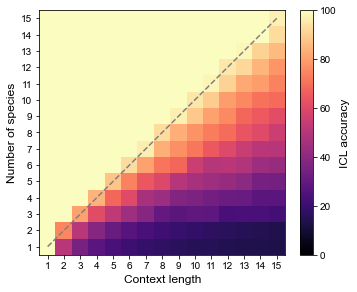

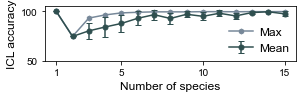

In [84]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

param1_values = np.arange(1,16,1)
param2_values = np.arange(1,16,1)
param3_values = [1,2,3,4,5]
# param1_values = np.arange(4,6,1)
# param2_values = np.arange(5,16,1)
#len(np.arange(5,16,1)) * len(np.arange(4,6,1))
path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed/"


results_grid = np.zeros((len(param1_values), len(param2_values), len(param3_values)))
for i, param1 in enumerate(param1_values):
    for j, param2 in enumerate(param2_values):
        for k, param3 in enumerate(param3_values):
            path = path_base + str(param1) + "_" + str(param2) + "_" + str(param3) + "/"
            results_path = path + "results.pkl"
            try:
                with open(results_path, "rb") as file:
                    data = pickle.load(file)
                results = data['results']
                history = data['history']
                #icl_acc = [val for val in history['icl_acc'] if val is not None]
                icl_acc = [val for val in history['train_acc'] if val is not None]
                #results_grid[i, j] = icl_acc[-1]
                results_grid[i, j, k] = np.max(icl_acc)
            except:
                pass

import pprint
pprint.pprint(data['params'])

# plot
fig, ax = plt.subplots(figsize=(5.5, 4.5))
fs = 12

results_grid_avg = np.mean(results_grid, axis = 2)
im = ax.imshow(results_grid_avg, cmap='magma', aspect='auto', origin='lower', vmin = 0, vmax = 100)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("ICL accuracy", size = fs)
ax.set_xlabel('Context length', fontsize=fs)
ax.set_ylabel('Number of species', fontsize=fs)
# ax.set_xlabel('D')
# ax.set_ylabel('K')
ax.set_xticks(range(len(param2_values)), param2_values)
ax.set_yticks(range(len(param1_values)), param1_values)
#ax.set_title('ICL accuracy', fontsize=fs)

# Add diagonal line from bottom-left to top-right
ax.plot([0, len(param1_values)-1], [0, len(param2_values)-1], 
        color='gray', linestyle='--', linewidth=1.5)

# # Add text annotations for each cell
# for i in range(len(param1_values)):
#     for j in range(len(param2_values)):
#         text = ax.text(i, j, f'{results_grid[j, i]:.1f}',
#                        ha="center", va="center", color="gray", fontsize=10)

# plot
fig, ax = plt.subplots(figsize=(4.5, 1))
fs = 12
diag = np.array([np.mean(results_grid[i,i,:]) for i in range(len(param1_values))])
diag_max = np.array([np.max(results_grid[i,i,:]) for i in range(len(param1_values))])
diag_std = np.array([np.std(results_grid[i,i,:]) for i in range(len(param1_values))])



# Add diagonal line with error bars
x_positions = range(len(param1_values))
ax.errorbar(x_positions, diag, yerr=diag_std, 
            color='darkslategray', linestyle='-', linewidth=1.5, 
            marker='o', markersize=5, capsize=3, label = 'Mean')
ax.plot(x_positions, diag_max,
        color='lightslategray', linestyle='-', linewidth=1.5, 
        marker='h', markersize=5, zorder = -10, label = 'Max')
ax.set_ylim(50, 105)
ax.set_xlabel('Number of species', fontsize=fs)
ax.set_ylabel('ICL accuracy', fontsize=fs)
ax.set_xticks([i for i in range(len(param1_values)) if (param1_values[i] % 5 == 0) or (param1_values[i] == 1)])
ax.set_xticklabels([param1_values[i] for i in range(len(param1_values)) if (param1_values[i] % 5 == 0) or (param1_values[i] == 1)])
ax.legend(fontsize=fs, frameon=False, loc='lower right', ncol=1, handletextpad=0.5, borderaxespad=0.2)

# plt.show()

# save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
# fig.savefig(save_path + 'ICLAccuracyDiag.png', dpi=300, bbox_inches='tight')

plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.savefig(save_path + 'ICLAccuracy.png', dpi=300, bbox_inches='tight')

<ipython-input-45-959299571366>:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


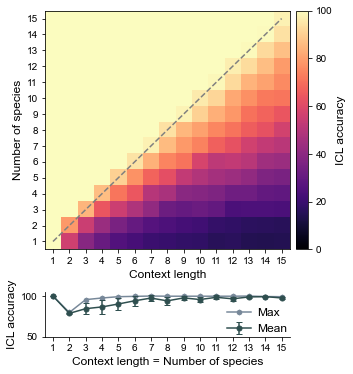

In [45]:
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Create figure with GridSpec
fig = plt.figure(figsize=1*np.array([4.725, 6]))
gs = gridspec.GridSpec(2, 2, width_ratios=[1, 0.05], height_ratios=[4, 0.75], 
                       hspace=0.3, wspace=0.05)
fs = 12

# === Top panel: Heatmap ===
ax_top = fig.add_subplot(gs[0, 0])
results_grid_avg = np.mean(results_grid, axis=2)
im = ax_top.imshow(results_grid_avg, cmap='magma', aspect='auto', origin='lower', vmin=0, vmax=100)

ax_top.set_ylabel('Number of species', fontsize=fs)
ax_top.set_yticks(range(len(param2_values)), param2_values)

# Top panel x-axis
ax_top.set_xticks(range(len(param1_values)))
ax_top.set_xticklabels(param1_values)
ax_top.set_xlabel('Context length', fontsize=fs)

ax_top.set_xlim(-0.5, len(param1_values) - 0.5)

# === Bottom panel: Diagonal slice ===
ax_bot = fig.add_subplot(gs[1, 0])  # Now assign ax_bot before using it
diag = np.array([np.mean(results_grid[i, i, :]) for i in range(len(param1_values))])
diag_std = np.array([np.std(results_grid[i, i, :]) for i in range(len(param1_values))])
diag_max = np.array([np.max(results_grid[i,i,:]) for i in range(len(param1_values))])

x_positions = range(len(param1_values))
# ax_bot.errorbar(x_positions, diag, yerr=diag_std, 
#                 color='black', linestyle='-', linewidth=1.5, 
#                 marker='o', markersize=4, capsize=3)
ax_bot.errorbar(x_positions, diag, yerr=diag_std, 
            color='darkslategray', linestyle='-', linewidth=1.5, 
            marker='o', markersize=5, capsize=3, label = 'Mean')
ax_bot.plot(x_positions, diag_max,
        color='lightslategray', linestyle='-', linewidth=1.5, 
        marker='h', markersize=5, zorder = -10, label = 'Max')
ax_bot.set_ylim(50, 105)
ax_bot.set_ylabel('ICL accuracy', fontsize=fs)
ax_bot.spines['top'].set_visible(False)
ax_bot.spines['right'].set_visible(False)

# Set x-axis properties for bottom panel
ax_bot.set_xlim(-0.5, len(param1_values) - 0.5)
ax_bot.set_xticks(range(len(param1_values)))
ax_bot.set_xticklabels(param1_values)
ax_bot.set_xlabel('Context length = Number of species', fontsize=fs)

# Bottom panel x-axis should not affect top by default, so ensure explicit order:
ax_top.set_xlim(-0.5, len(param1_values) - 0.5)
ax_bot.set_xlim(-0.5, len(param1_values) - 0.5)

# Add diagonal line from bottom-left to top-right on the top panel
ax_top.plot([0, len(param1_values)-1], [0, len(param2_values)-1], 
            color='gray', linestyle='--', linewidth=1.5)
ax_bot.legend(fontsize=fs, frameon=False, loc='lower right', ncol=1, handletextpad=0.5, borderaxespad=-0.2)


# Colorbar in its own column
cax = fig.add_subplot(gs[0, 1])
cbar = plt.colorbar(im, cax=cax)
cbar.set_label("ICL accuracy", size=fs)

plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'ICLAccuracyStacked.png', dpi=300, bbox_inches='tight')

<ipython-input-132-55a9773d9104>:82: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 1000)


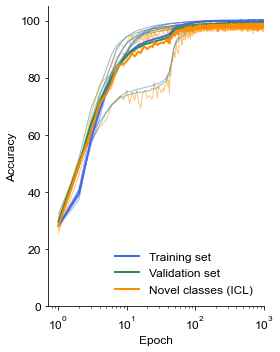

In [132]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np


seed_vals = [1,2,3,4,5]
# Plot training history
fig, ax = plt.subplots(1, 1, figsize=(4, 5))
fs = 12

# Plot 1: Loss curves

epochs = range(1, 1001)

sub_alpha = 0.5

icl_color = 'darkorange'
train_color = 'royalblue'
val_color = 'seagreen'
icl_avs = np.zeros(len(epochs))
train_avs = np.zeros(len(epochs))
val_avs = np.zeros(len(epochs))
for seed in seed_vals:
    path = f"/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/D_Nsamp_seed/8_25000_{seed}/"
    # Load the results
    results_path = path + "results.pkl"
    with open(results_path, "rb") as file:
        data = pickle.load(file)

    # Extract components
    results = data['results']
    history = data['history']
    params = data['params']
    execution_time = data['execution_time']


    icl_acc = np.array(history['icl_acc'])
    train_acc = np.array(history['train_acc'])
    val_acc = np.array(history['val_acc'])

    ax.plot(epochs, icl_acc, linewidth=1, color = icl_color, alpha = sub_alpha)
    ax.plot(epochs, train_acc, linewidth=1, color = train_color, alpha = sub_alpha)
    ax.plot(epochs, val_acc, linewidth=1, color = val_color, alpha = sub_alpha)

    icl_avs += icl_acc
    train_avs += train_acc
    val_avs += val_acc
icl_avs /= len(seed_vals)
train_avs /= len(seed_vals)
val_avs /= len(seed_vals)


ax.plot(epochs, train_avs, linewidth=2, color = train_color, label = 'Training set')
ax.plot(epochs, val_avs, linewidth=2, color = val_color, label = 'Validation set')
ax.plot(epochs, icl_avs, linewidth=2, color = icl_color, label = 'Novel classes (ICL)')

#ax.axhline(y=100, color='black', linestyle='--', linewidth=2, alpha=0.5, zorder = -10)

ax.set_xlabel('Epoch', fontsize=fs)
ax.set_ylabel('Accuracy', fontsize=fs)
ax.tick_params(axis='x', labelsize=fs)
ax.tick_params(axis='y', labelsize=fs)
ax.set_xscale('log')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim(0, 105)
ax.set_xlim(0, 1000)
#ax.set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
ax.grid(False)#, alpha=0.3)
ax.legend(fontsize=fs, frameon=False, loc='lower right', ncol=1)

plt.tight_layout()
plt.show()
# Save the figure in high resolution
save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'TrainingCurves.png', dpi=300, bbox_inches='tight')




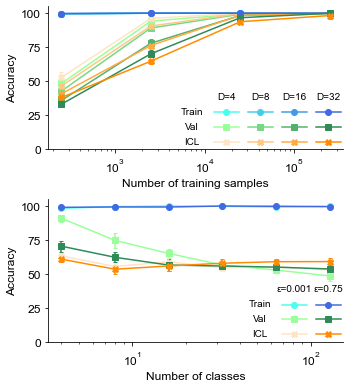

In [5]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerLine2D


# === Helper functions ===

def interpolate_color(color1, color2, t):
    """Interpolate between two colors. t=0 gives color1, t=1 gives color2."""
    c1 = np.array(mcolors.to_rgb(color1))
    c2 = np.array(mcolors.to_rgb(color2))
    return c1 + t * (c2 - c1)

def adjust_lightness(color, amount=0.5):
    """
    Lightens or darkens the given color.
    amount > 1.0 makes it lighter, amount < 1.0 makes it darker.
    """
    try:
        c = mcolors.cnames[color]
    except:
        c = color
    c = mcolors.to_rgb(c)
    c = np.array(mcolors.rgb_to_hsv(c))
    c[2] = min(1.0, c[2] * amount)
    return mcolors.hsv_to_rgb(c)

def create_table_legend(ax, row_labels, col_labels, colors_matrix, markers,
                        loc='lower right', fontsize=10, markersize=6, linewidth=1.5):
    """
    Create a table-style legend.
    """
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    from matplotlib.legend_handler import HandlerBase
    from matplotlib.text import Text
    
    # Custom handler that draws text as the "handle"
    class TextHandler(HandlerBase):
        def __init__(self, text, fontsize):
            self.text = text
            self.fontsize = fontsize
            super().__init__()
        
        def create_artists(self, legend, orig_handle, xdescent, ydescent, 
                           width, height, fontsize, trans):
            txt = Text(width/2, height/2, self.text, 
                       fontsize=self.fontsize,
                       ha='center', va='center',
                       transform=trans)
            return [txt]
    
    n_rows = len(row_labels)
    n_cols = len(col_labels)
    
    handles = []
    labels = []
    handler_map = {}
    
    def spacer_handle():
        h = Patch(facecolor='none', edgecolor='none')
        return h
    
    # Build in COLUMN order
    
    # Column 0: empty corner + row labels
    h = spacer_handle()
    handles.append(h)
    labels.append('')
    
    for i in range(n_rows):
        h = spacer_handle()
        handles.append(h)
        handler_map[h] = TextHandler(row_labels[i], fontsize)
        labels.append('')
    
    # Columns 1+: column header (as text handle) + markers
    for j in range(n_cols):
        # Column header as text handle
        h = spacer_handle()
        handles.append(h)
        handler_map[h] = TextHandler(col_labels[j], fontsize)
        labels.append('')
        
        # Markers for each row
        for i in range(n_rows):
            handles.append(Line2D([0], [0],
                                  marker=markers[i],
                                  color=colors_matrix[i][j],
                                  linestyle='-',
                                  markersize=markersize,
                                  linewidth=linewidth))
            labels.append('')
    
    legend = ax.legend(
        handles, labels,
        loc=loc,
        ncol=n_cols + 1,
        fontsize=fontsize,
        frameon=False,
        handlelength=2.5,
        handleheight=1.0,
        handletextpad=0.1,
        columnspacing=0.8,
        labelspacing=0.5,
        borderaxespad=-0.25,     # padding between legend and axes
        handler_map=handler_map,
    )
    
    return legend


# === Parameters ===

D_vals = [4, 8, 16, 32]
Nsamp_vals = [250, 2500, 25000, 250000]
L_vals = [4, 8, 16, 32, 64, 128]
epsilon_vals = [0.001, 0.75]
seed_vals = [1, 2, 3, 4, 5]

# Plot settings
fig, axes = plt.subplots(2, 1, figsize=(5, 5.5))
fs = 12
markersize = 6
capsize = 2
col_off_up = 0.0
col_off_down = 0.4
pos = 'lower right'

icl_color = 'darkorange'
train_color = 'royalblue'
val_color = 'seagreen'


# === Load D vs Nsamp data ===

D_Nsamp_train = np.zeros((len(D_vals), len(Nsamp_vals), len(seed_vals)))
D_Nsamp_val = np.zeros((len(D_vals), len(Nsamp_vals), len(seed_vals)))
D_Nsamp_icl = np.zeros((len(D_vals), len(Nsamp_vals), len(seed_vals)))

for i, D in enumerate(D_vals):
    for j, Nsamp in enumerate(Nsamp_vals):
        for k, seed in enumerate(seed_vals):
            try:
                path = f"/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/D_Nsamp_seed/{D}_{Nsamp}_{seed}/"
                results_path = path + "results.pkl"
                with open(results_path, "rb") as file:
                    data = pickle.load(file)
            except:
                print(f"No results found for D={D}, Nsamp={Nsamp}, seed={seed}")
                continue

            history = data['history']
            D_Nsamp_train[i, j, k] = np.max(history['train_acc'])
            D_Nsamp_val[i, j, k] = np.max(history['val_acc'])
            D_Nsamp_icl[i, j, k] = np.max(history['icl_acc'])

D_Nsamp_train_avs = np.mean(D_Nsamp_train, axis=2)
D_Nsamp_val_avs = np.mean(D_Nsamp_val, axis=2)
D_Nsamp_icl_avs = np.mean(D_Nsamp_icl, axis=2)
D_Nsamp_train_std = np.std(D_Nsamp_train, axis=2)
D_Nsamp_val_std = np.std(D_Nsamp_val, axis=2)
D_Nsamp_icl_std = np.std(D_Nsamp_icl, axis=2)


# === Color maps for D panel ===

n_D = len(D_vals)
icl_color_map_D = [interpolate_color(adjust_lightness('bisque', 1+col_off_down), 
                                      adjust_lightness(icl_color, 1-col_off_up), 
                                      i / max(n_D - 1, 1)) for i in range(n_D)]
train_color_map_D = [interpolate_color(adjust_lightness('turquoise', 1+col_off_down), 
                                        adjust_lightness(train_color, 1-col_off_up), 
                                        i / max(n_D - 1, 1)) for i in range(n_D)]
val_color_map_D = [interpolate_color(adjust_lightness('lightgreen', 1+col_off_down), 
                                      adjust_lightness(val_color, 1-col_off_up), 
                                      i / max(n_D - 1, 1)) for i in range(n_D)]


# === Top panel: D vs Nsamp ===

ax = axes[0]
for i, D in enumerate(D_vals):
    ax.errorbar(Nsamp_vals, D_Nsamp_train_avs[i, :], yerr=D_Nsamp_train_std[i, :], 
                color=train_color_map_D[i], markersize=markersize, fmt='o-', capsize=capsize)
    ax.errorbar(Nsamp_vals, D_Nsamp_val_avs[i, :], yerr=D_Nsamp_val_std[i, :], 
                color=val_color_map_D[i], markersize=markersize, fmt='s-', capsize=capsize)
    ax.errorbar(Nsamp_vals, D_Nsamp_icl_avs[i, :], yerr=D_Nsamp_icl_std[i, :], 
                color=icl_color_map_D[i], markersize=markersize, fmt='X-', capsize=capsize)

ax.set_xlabel('Number of training samples', fontsize=fs)
ax.set_ylabel('Accuracy', fontsize=fs)
ax.tick_params(axis='x', labelsize=fs)
ax.tick_params(axis='y', labelsize=fs)
ax.set_xscale('log')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(False)
ax.set_ylim(0, 105)

# Create table legend for top panel
create_table_legend(
    ax,
    row_labels=['Train', 'Val', 'ICL'],
    col_labels=[f'D={D}' for D in D_vals],
    colors_matrix=[train_color_map_D, val_color_map_D, icl_color_map_D],
    markers=['o', 's', 'X'],
    loc=pos,
    fontsize=fs-2
)



# === Load L vs epsilon data ===

L_epsilon_train = np.zeros((len(L_vals), len(epsilon_vals), len(seed_vals)))
L_epsilon_val = np.zeros((len(L_vals), len(epsilon_vals), len(seed_vals)))
L_epsilon_icl = np.zeros((len(L_vals), len(epsilon_vals), len(seed_vals)))

for i, L in enumerate(L_vals):
    for j, epsilon in enumerate(epsilon_vals):
        for k, seed in enumerate(seed_vals):
            try:
                path = f"/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/L_epsilon_seed/{L}_{epsilon}_{seed}/"
                results_path = path + "results.pkl"
                with open(results_path, "rb") as file:
                    data = pickle.load(file)
            except:
                print(f"No results found for L={L}, epsilon={epsilon}, seed={seed}")
                continue

            history = data['history']
            L_epsilon_train[i, j, k] = np.max(history['train_acc'])
            L_epsilon_val[i, j, k] = np.max(history['val_acc'])
            L_epsilon_icl[i, j, k] = np.max(history['icl_acc'])

L_epsilon_train_avs = np.mean(L_epsilon_train, axis=2)
L_epsilon_val_avs = np.mean(L_epsilon_val, axis=2)
L_epsilon_icl_avs = np.mean(L_epsilon_icl, axis=2)
L_epsilon_train_std = np.std(L_epsilon_train, axis=2)
L_epsilon_val_std = np.std(L_epsilon_val, axis=2)
L_epsilon_icl_std = np.std(L_epsilon_icl, axis=2)


# === Color maps for epsilon panel ===

n_eps = len(epsilon_vals)
icl_color_map_eps = [interpolate_color(adjust_lightness('bisque', 1+col_off_down), 
                                        adjust_lightness(icl_color, 1-col_off_up), 
                                        i / max(n_eps - 1, 1)) for i in range(n_eps)]
train_color_map_eps = [interpolate_color(adjust_lightness('turquoise', 1+col_off_down), 
                                          adjust_lightness(train_color, 1-col_off_up), 
                                          i / max(n_eps - 1, 1)) for i in range(n_eps)]
val_color_map_eps = [interpolate_color(adjust_lightness('lightgreen', 1+col_off_down), 
                                        adjust_lightness(val_color, 1-col_off_up), 
                                        i / max(n_eps - 1, 1)) for i in range(n_eps)]


# === Bottom panel: L vs epsilon ===

ax = axes[1]
for j, epsilon in enumerate(epsilon_vals):
    ax.errorbar(L_vals, L_epsilon_train_avs[:, j], yerr=L_epsilon_train_std[:, j], 
                color=train_color_map_eps[j], markersize=markersize, fmt='o-', capsize=capsize)
    ax.errorbar(L_vals, L_epsilon_val_avs[:, j], yerr=L_epsilon_val_std[:, j], 
                color=val_color_map_eps[j], markersize=markersize, fmt='s-', capsize=capsize)
    ax.errorbar(L_vals, L_epsilon_icl_avs[:, j], yerr=L_epsilon_icl_std[:, j], 
                color=icl_color_map_eps[j], markersize=markersize, fmt='X-', capsize=capsize)

ax.set_xlabel('Number of classes', fontsize=fs)
ax.set_ylabel('Accuracy', fontsize=fs)
ax.tick_params(axis='x', labelsize=fs)
ax.tick_params(axis='y', labelsize=fs)
ax.set_xscale('log')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(False)
ax.set_ylim(0, 105)

# Create table legend for bottom panel
create_table_legend(
    ax,
    row_labels=['Train', 'Val', 'ICL'],
    col_labels=[f'ε={eps}' for eps in epsilon_vals],
    colors_matrix=[train_color_map_eps, val_color_map_eps, icl_color_map_eps],
    markers=['o', 's', 'X'],
    loc=pos,
    fontsize=fs-2
)


plt.tight_layout()
plt.show()

# Save the figure in high resolution
save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.savefig(save_path + 'TrainingScans.png', dpi=300, bbox_inches='tight')

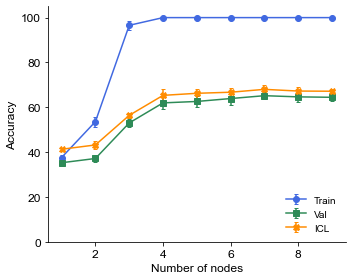

In [3]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerLine2D


# === Helper functions ===

def interpolate_color(color1, color2, t):
    """Interpolate between two colors. t=0 gives color1, t=1 gives color2."""
    c1 = np.array(mcolors.to_rgb(color1))
    c2 = np.array(mcolors.to_rgb(color2))
    return c1 + t * (c2 - c1)

def adjust_lightness(color, amount=0.5):
    """
    Lightens or darkens the given color.
    amount > 1.0 makes it lighter, amount < 1.0 makes it darker.
    """
    try:
        c = mcolors.cnames[color]
    except:
        c = color
    c = mcolors.to_rgb(c)
    c = np.array(mcolors.rgb_to_hsv(c))
    c[2] = min(1.0, c[2] * amount)
    return mcolors.hsv_to_rgb(c)

def create_table_legend(ax, row_labels, col_labels, colors_matrix, markers,
                        loc='lower right', fontsize=10, markersize=6, linewidth=1.5):
    """
    Create a table-style legend.
    """
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    from matplotlib.legend_handler import HandlerBase
    from matplotlib.text import Text
    
    # Custom handler that draws text as the "handle"
    class TextHandler(HandlerBase):
        def __init__(self, text, fontsize):
            self.text = text
            self.fontsize = fontsize
            super().__init__()
        
        def create_artists(self, legend, orig_handle, xdescent, ydescent, 
                           width, height, fontsize, trans):
            txt = Text(width/2, height/2, self.text, 
                       fontsize=self.fontsize,
                       ha='center', va='center',
                       transform=trans)
            return [txt]
    
    n_rows = len(row_labels)
    n_cols = len(col_labels)
    
    handles = []
    labels = []
    handler_map = {}
    
    def spacer_handle():
        h = Patch(facecolor='none', edgecolor='none')
        return h
    
    # Build in COLUMN order
    
    # Column 0: empty corner + row labels
    h = spacer_handle()
    handles.append(h)
    labels.append('')
    
    for i in range(n_rows):
        h = spacer_handle()
        handles.append(h)
        handler_map[h] = TextHandler(row_labels[i], fontsize)
        labels.append('')
    
    # Columns 1+: column header (as text handle) + markers
    for j in range(n_cols):
        # Column header as text handle
        h = spacer_handle()
        handles.append(h)
        handler_map[h] = TextHandler(col_labels[j], fontsize)
        labels.append('')
        
        # Markers for each row
        for i in range(n_rows):
            handles.append(Line2D([0], [0],
                                  marker=markers[i],
                                  color=colors_matrix[i][j],
                                  linestyle='-',
                                  markersize=markersize,
                                  linewidth=linewidth))
            labels.append('')
    
    legend = ax.legend(
        handles, labels,
        loc=loc,
        ncol=n_cols + 1,
        fontsize=fontsize,
        frameon=False,
        handlelength=2.5,
        handleheight=1.0,
        handletextpad=0.1,
        columnspacing=0.8,
        labelspacing=0.5,
        borderaxespad=-0.25,     # padding between legend and axes
        handler_map=handler_map,
    )
    
    return legend


# === Parameters ===

N_nodes_vals = np.arange(1,10,1)
seed_vals = [1, 2, 3, 4, 5]

# Plot settings
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
fs = 12
markersize = 6
capsize = 2
col_off_up = 0.0
col_off_down = 0.4
pos = 'lower right'

icl_color = 'darkorange'
train_color = 'royalblue'
val_color = 'seagreen'


# === Load N_nodes vs seed data ===

N_nodes_train = np.zeros((len(N_nodes_vals), len(seed_vals)))
N_nodes_val = np.zeros((len(N_nodes_vals), len(seed_vals)))
N_nodes_icl = np.zeros((len(N_nodes_vals), len(seed_vals)))

for i, N_nodes in enumerate(N_nodes_vals):
    for k, seed in enumerate(seed_vals):
        try:
            path = f"/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_seed_overfit/{N_nodes}_{seed}/"
            results_path = path + "results.pkl"
            with open(results_path, "rb") as file:
                data = pickle.load(file)
        except:
            print(f"No results found for N_nodes={N_nodes}, seed={seed}")
            continue

        history = data['history']
        N_nodes_train[i, k] = np.max(history['train_acc'])
        N_nodes_val[i, k] = np.max(history['val_acc'])
        N_nodes_icl[i, k] = np.max(history['icl_acc'])

N_nodes_train_avs = np.mean(N_nodes_train, axis=1)
N_nodes_val_avs = np.mean(N_nodes_val, axis=1)
N_nodes_icl_avs = np.mean(N_nodes_icl, axis=1)
N_nodes_train_std = np.std(N_nodes_train, axis=1)
N_nodes_val_std = np.std(N_nodes_val, axis=1)
N_nodes_icl_std = np.std(N_nodes_icl, axis=1)


# === Plot ===

ax.errorbar(N_nodes_vals, N_nodes_train_avs, yerr=N_nodes_train_std, 
            color=train_color, markersize=markersize, fmt='o-', capsize=capsize, label='Train')
ax.errorbar(N_nodes_vals, N_nodes_val_avs, yerr=N_nodes_val_std, 
            color=val_color, markersize=markersize, fmt='s-', capsize=capsize, label='Val')
ax.errorbar(N_nodes_vals, N_nodes_icl_avs, yerr=N_nodes_icl_std, 
            color=icl_color, markersize=markersize, fmt='X-', capsize=capsize, label='ICL')

ax.set_xlabel('Number of nodes', fontsize=fs)
ax.set_ylabel('Accuracy', fontsize=fs)
ax.tick_params(axis='x', labelsize=fs)
ax.tick_params(axis='y', labelsize=fs)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(False)
ax.set_ylim(0, 105)
ax.legend(fontsize=fs-2, loc=pos, frameon=False)

plt.tight_layout()
plt.show()

# Save the figure in high resolution
#save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.savefig(save_path + 'TrainingScans.png', dpi=300, bbox_inches='tight')

# Different activations

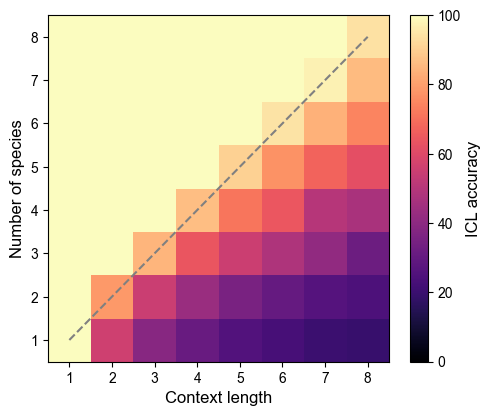

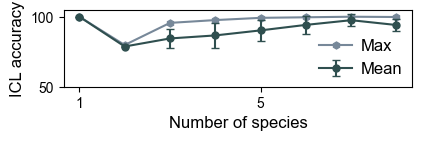

In [7]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

param1_values = np.arange(1,9,1)
param2_values = np.arange(1,9,1)
param3_values = [1,2,3,4,5]
# param1_values = np.arange(4,6,1)
# param2_values = np.arange(5,16,1)
#len(np.arange(5,16,1)) * len(np.arange(4,6,1))
path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed/"


results_grid = np.zeros((len(param1_values), len(param2_values), len(param3_values)))
for i, param1 in enumerate(param1_values):
    for j, param2 in enumerate(param2_values):
        for k, param3 in enumerate(param3_values):
            path = path_base + str(param1) + "_" + str(param2) + "_" + str(param3) + "/"
            results_path = path + "results.pkl"
            try:
                with open(results_path, "rb") as file:
                    data = pickle.load(file)
                results = data['results']
                history = data['history']
                icl_acc = [val for val in history['icl_acc'] if val is not None]
                #results_grid[i, j] = icl_acc[-1]
                results_grid[i, j, k] = np.max(icl_acc)
            except:
                pass



# plot
fig, ax = plt.subplots(figsize=(5.5, 4.5))
fs = 12

results_grid_avg = np.mean(results_grid, axis = 2)
im = ax.imshow(results_grid_avg, cmap='magma', aspect='auto', origin='lower', vmin = 0, vmax = 100)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("ICL accuracy", size = fs)
ax.set_xlabel('Context length', fontsize=fs)
ax.set_ylabel('Number of species', fontsize=fs)
# ax.set_xlabel('D')
# ax.set_ylabel('K')
ax.set_yticks(range(len(param2_values)), param2_values)
ax.set_xticks(range(len(param1_values)), param1_values)
#ax.set_title('ICL accuracy', fontsize=fs)

# Add diagonal line from bottom-left to top-right
ax.plot([0, len(param1_values)-1], [0, len(param2_values)-1], 
        color='gray', linestyle='--', linewidth=1.5)

# # Add text annotations for each cell
# for i in range(len(param1_values)):
#     for j in range(len(param2_values)):
#         text = ax.text(i, j, f'{results_grid[j, i]:.1f}',
#                        ha="center", va="center", color="gray", fontsize=10)

# plot
fig, ax = plt.subplots(figsize=(4.5, 1))
fs = 12
diag = np.array([np.mean(results_grid[i,i,:]) for i in range(len(param1_values))])
diag_max = np.array([np.max(results_grid[i,i,:]) for i in range(len(param1_values))])
diag_std = np.array([np.std(results_grid[i,i,:]) for i in range(len(param1_values))])



# Add diagonal line with error bars
x_positions = range(len(param1_values))
ax.errorbar(x_positions, diag, yerr=diag_std, 
            color='darkslategray', linestyle='-', linewidth=1.5, 
            marker='o', markersize=5, capsize=3, label = 'Mean')
ax.plot(x_positions, diag_max,
        color='lightslategray', linestyle='-', linewidth=1.5, 
        marker='h', markersize=5, zorder = -10, label = 'Max')
ax.set_ylim(50, 105)
ax.set_xlabel('Number of species', fontsize=fs)
ax.set_ylabel('ICL accuracy', fontsize=fs)
ax.set_xticks([i for i in range(len(param1_values)) if (param1_values[i] % 5 == 0) or (param1_values[i] == 1)])
ax.set_xticklabels([param1_values[i] for i in range(len(param1_values)) if (param1_values[i] % 5 == 0) or (param1_values[i] == 1)])
ax.legend(fontsize=fs, frameon=False, loc='lower right', ncol=1, handletextpad=0.5, borderaxespad=0.2)

# plt.show()

# save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
# fig.savefig(save_path + 'ICLAccuracyDiag.png', dpi=300, bbox_inches='tight')

plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.savefig(save_path + 'ICLAccuracy.png', dpi=300, bbox_inches='tight')

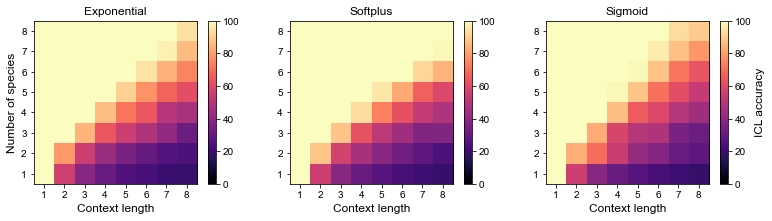

In [17]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

param1_values = np.arange(1,9,1)
param2_values = np.arange(1,9,1)
param3_values = [1,2,3,4,5]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))

titles = ["Exponential", "Softplus", "Sigmoid"]
for (n, name) in enumerate(["", "_softplus", "_sigmoid"]):
    path_base = f"/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed" + name + "/"

    results_grid = np.zeros((len(param1_values), len(param2_values), len(param3_values)))
    for i, param1 in enumerate(param1_values):
        for j, param2 in enumerate(param2_values):
            for k, param3 in enumerate(param3_values):
                path = path_base + str(param1) + "_" + str(param2) + "_" + str(param3) + "/"
                results_path = path + "results.pkl"
                try:
                    with open(results_path, "rb") as file:
                        data = pickle.load(file)
                    results = data['results']
                    history = data['history']
                    icl_acc = [val for val in history['icl_acc'] if val is not None]
                    #results_grid[i, j] = icl_acc[-1]
                    results_grid[i, j, k] = np.max(icl_acc)
                except:
                    pass

    ax = axes[n]
    
    results_grid_avg = np.mean(results_grid, axis = 2)
    im = ax.imshow(results_grid_avg, cmap='magma', aspect='equal', origin='lower', vmin = 0, vmax = 100)
    #if n == 2:
    cbar = plt.colorbar(im, ax=ax)
    if n == 2:
        cbar.set_label("ICL accuracy", size = fs)
    ax.set_xlabel('Context length', fontsize=fs)
    if n == 0:
        ax.set_ylabel('Number of species', fontsize=fs)
    # ax.set_xlabel('D')
    # ax.set_ylabel('K')
    ax.set_yticks(range(len(param2_values)), param2_values)
    ax.set_xticks(range(len(param1_values)), param1_values)
    ax.set_title(titles[n], fontsize=fs)

    # Set the background color of the figure to white
    fig.patch.set_facecolor('white')
    for ax in axes:
        ax.set_facecolor('white')

    # Add diagonal line from bottom-left to top-right
    # ax.plot([0, len(param1_values)-1], [0, len(param2_values)-1], 
    #         color='gray', linestyle='--', linewidth=1.5)

plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'SI_ActivationFunctions.png', dpi=300, bbox_inches='tight')

In [6]:
from models.markov_icl import load_model

results_grid = np.zeros((len(param1_values), len(param2_values), len(param3_values)))
path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed_softplus/"
data_keep = []
for k, param3 in enumerate(param3_values):
    path = path_base + str(2) + "_" + str(2) + "_" + str(param3) + "/"
    results_path = path + "results.pkl"
    #try:
    with open(results_path, "rb") as file:
        data = pickle.load(file)
    results = data['results']
    history = data['history']
    params = data['params']
    icl_acc = [val for val in history['icl_acc'] if val is not None]
    #results_grid[i, j] = icl_acc[-1]
    data_keep.append(np.max(icl_acc))
    #print(params)
    model = load_model(params, path, print_creation=True)
    # except:
    #     print(f"No results found for param3={param3}")
    #     pass

print(data_keep)
print(params)
# Sparsity plot

  Initialized ICL Attention model (L=128 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: -inf
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (48/48 active)
  base_W sparsity: 0.000 (4/4 active)
  Parameters: 56
  Initialized ICL Attention model (L=128 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: -inf
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (48/48 active)
  base_W sparsity: 0.000 (4/4 active)
  Parameters: 56
  Initialized ICL Attention model (L=128 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: -inf
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (48/48 active)
  base_W sparsity: 0.000 (4/4 active)
  Paramet

In [3]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

param1_values = np.arange(1,9,1)
param2_values = np.arange(1,9,1)
param3_values = np.arange(6,16)
# param1_values = np.arange(4,6,1)
# param2_values = np.arange(5,16,1)
#len(np.arange(5,16,1)) * len(np.arange(4,6,1))
path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed_sigmoid_more3/"


results_grid = []

for k, param3 in enumerate(param3_values):
    path = path_base + str(3) + "_" + str(3) + "_" + str(param3) + "/"
    results_path = path + "results.pkl"

    with open(results_path, "rb") as file:
        data = pickle.load(file)
    results = data['results']
    history = data['history']
    icl_acc = [val for val in history['icl_acc'] if val is not None]
    #results_grid[i, j] = icl_acc[-1]
    results_grid.append(np.max(icl_acc))


print(results_grid)

[np.float64(71.8), np.float64(71.8), np.float64(71.2), np.float64(89.0), np.float64(70.8), np.float64(74.2), np.float64(71.4), np.float64(96.4), np.float64(71.4), np.float64(100.0)]


# Sparsity plot

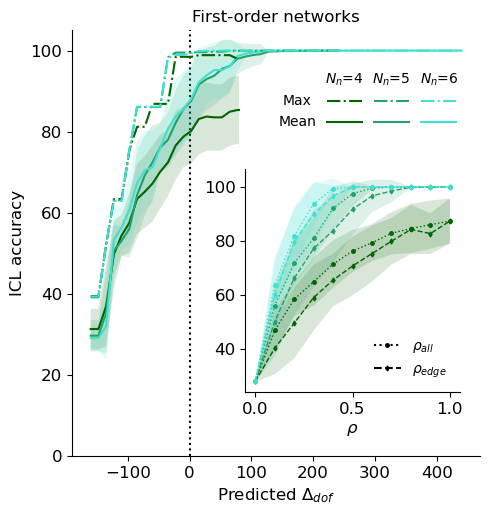

In [15]:
# Import necessary components
import torch
import numpy as np
import pickle
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from models.markov_icl import load_model

# === Configuration ===
seeds = np.arange(1, 31, 1)
nodes = [4,5,6]
sparsities = np.round(np.arange(0.0, 1.1, 0.1), 1)

# === Color utilities ===
def interpolate_color(color1, color2, t):
    c1 = np.array(mcolors.to_rgb(color1))
    c2 = np.array(mcolors.to_rgb(color2))
    return c1 + t * (c2 - c1)

def adjust_lightness(color, amount=0.5):
    c = mcolors.to_rgb(color)
    c = np.array(mcolors.rgb_to_hsv(c))
    c[2] = min(1.0, c[2] * amount)
    return mcolors.hsv_to_rgb(c)

def create_table_legend(ax, row_labels, col_labels, colors_matrix, linestyles,
                        loc='lower right', fontsize=10, markersize=6, linewidth=1.5, bbox_to_anchor=None):
    """
    Create a table-style legend with different linestyles per row.
    """
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    from matplotlib.legend_handler import HandlerBase
    from matplotlib.text import Text
    
    class TextHandler(HandlerBase):
        def __init__(self, text, fontsize):
            self.text = text
            self.fontsize = fontsize
            super().__init__()
        
        def create_artists(self, legend, orig_handle, xdescent, ydescent, 
                           width, height, fontsize, trans):
            txt = Text(width/2, height/2, self.text, 
                       fontsize=self.fontsize,
                       ha='center', va='center',
                       transform=trans)
            return [txt]
    
    n_rows = len(row_labels)
    n_cols = len(col_labels)
    
    handles = []
    labels = []
    handler_map = {}
    
    def spacer_handle():
        return Patch(facecolor='none', edgecolor='none')
    
    # Column 0: empty corner + row labels
    handles.append(spacer_handle())
    labels.append('')
    
    for i in range(n_rows):
        h = spacer_handle()
        handles.append(h)
        handler_map[h] = TextHandler(row_labels[i], fontsize)
        labels.append('')
    
    # Columns 1+: column header + line samples
    for j in range(n_cols):
        h = spacer_handle()
        handles.append(h)
        handler_map[h] = TextHandler(col_labels[j], fontsize)
        labels.append('')
        
        for i in range(n_rows):
            handles.append(Line2D([0], [0],
                                  color=colors_matrix[i][j],
                                  linestyle=linestyles[i],
                                  linewidth=linewidth))
            labels.append('')
    
    legend = ax.legend(
        handles, labels,
        loc=loc,
        ncol=n_cols + 1,
        fontsize=fontsize,
        bbox_to_anchor=bbox_to_anchor,
        frameon=False,
        handlelength=2.5,
        handleheight=1.0,
        handletextpad=0.1,
        columnspacing=0.8,
        labelspacing=0.5,
        borderaxespad=-0.25,
        handler_map=handler_map,
    )
    
    return legend

color_map = [interpolate_color(adjust_lightness('darkgreen', 1.0), 
                                adjust_lightness('turquoise', 1.0), 
                                i / max(len(nodes) - 1, 1)) for i in range(len(nodes))]
colors = {node: color_map[i] for i, node in enumerate(nodes)}

# === Data collection ===
# Structure: data[condition][node][sparsity] = {'dof_diff': [], 'icl_acc': []}

acc_key = 'icl_acc'
acc_key = 'train_acc'


data = {
    'rhoall': {node: {s: {'dof_diff': [], acc_key: []} for s in sparsities} for node in nodes},
    'rhoedge': {node: {s: {'dof_diff': [], acc_key: []} for s in sparsities} for node in nodes}
}

base_paths = {
    'rhoall': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_rhoall_seed_nt",
    'rhoedge': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_rhoedge_seed_nt"
}



for condition, base_path in base_paths.items():
    for node in nodes:
        for sparsity in sparsities:
            for seed in seeds:
                path = f"{base_path}/{node}_{sparsity}_{seed}/"
                with open(path + "results.pkl", "rb") as f:
                    d = pickle.load(f)
                
                params = d['params']
                history = d['history']
                
                model = load_model(params, path, print_creation=False)
                needed_dof = 2 * params['D'] * params['N'] * (params['N'] + 1)
                available_dof = model.get_non_zero_count_K()
                dof_diff = available_dof - needed_dof
                
                icl_acc = [v for v in history[acc_key] if v is not None][-1]
                icl_acc_array = [v for v in history[acc_key] if v is not None]
                # print(history['icl_acc'])
                # print(history['train_acc'])
                icl_acc = np.max(icl_acc_array)
                
                data[condition][node][sparsity]['dof_diff'].append(dof_diff)
                data[condition][node][sparsity][acc_key].append(icl_acc)

# === Plotting ===
#fig, ax_main = plt.subplots(figsize=(4, 4.25))
fig, ax_main = plt.subplots(figsize=(5, 5.25))
fs = 12
lw = 1.5
window_width = 50

# Main plot: DOF difference vs ICL accuracy (combined conditions)
for node in nodes:
    # Combine both conditions for main plot
    all_dof_diff = []
    all_icl_acc = []
    for condition in ['rhoedge']:#, 'rhoedge']:
        for sparsity in sparsities:
            all_dof_diff.extend(data[condition][node][sparsity]['dof_diff'])
            all_icl_acc.extend(data[condition][node][sparsity][acc_key])
    
    all_dof_diff = np.array(all_dof_diff)
    all_icl_acc = np.array(all_icl_acc)
    
    # Sort for running window
    sorted_idx = np.argsort(all_dof_diff)
    sorted_dof = all_dof_diff[sorted_idx]
    sorted_acc = all_icl_acc[sorted_idx]
    
    # Running window statistics - extend to full data range
    data_min = sorted_dof.min()
    data_max = sorted_dof.max()
    
    # Create window centers that extend to the data boundaries
    window_centers = np.arange(data_min, data_max + 1, window_width / 4)
    
    # Ensure we have points at the extremes
    if window_centers[0] > data_min:
        window_centers = np.concatenate([[data_min], window_centers])
    if window_centers[-1] < data_max:
        window_centers = np.concatenate([window_centers, [data_max]])

    centers_valid, means, stds, maxes = [], [], [], []
    
    for center in window_centers:
        mask = np.abs(sorted_dof - center) <= window_width / 2
        if mask.sum() > 0:
            centers_valid.append(center)
            means.append(sorted_acc[mask].mean())
            stds.append(sorted_acc[mask].std())
            maxes.append(sorted_acc[mask].max())
    
    centers_valid = np.array(centers_valid)
    means, stds, maxes = np.array(means), np.array(stds), np.array(maxes)
    
    ax_main.plot(centers_valid, means, color=colors[node], linewidth=lw, label=f'$N_n$={node}')
    ax_main.plot(centers_valid, maxes, color=colors[node], linestyle='-.', linewidth=lw, zorder=10, label=f'$N_n$={node}')
    ax_main.fill_between(centers_valid, means - stds, means + stds, color=colors[node], alpha=0.15, edgecolor='none')

ax_main.axvline(x=0, color='black', linewidth=1.5, zorder=-10, linestyle=':')
ax_main.set_xlabel(r'Predicted $\Delta_{dof}$', fontsize=fs)
ax_main.set_ylabel('ICL accuracy', fontsize=fs)
ax_main.set_ylim(0, 105)
ax_main.tick_params(labelsize=fs)
ax_main.spines['top'].set_visible(False)
ax_main.spines['right'].set_visible(False)
#ax_main.legend(fontsize=fs-2, frameon=False, loc='upper right', bbox_to_anchor=(1, 0.9))

colors_matrix = [
    [colors[node] for node in nodes],  # Max row
    [colors[node] for node in nodes],  # Mean row
]
create_table_legend(
    ax_main,
    row_labels=['Max', 'Mean'],
    col_labels=[f'$N_n$={node}' for node in nodes],
    colors_matrix=colors_matrix,
    linestyles=['-.', '-'],  # Max is dash-dot, Mean is solid
    loc='upper right',
    fontsize=fs-2,
    bbox_to_anchor=(0.95, 0.9),
    linewidth=lw
)


# Inset: Sparsity vs ICL accuracy, distinguishing edge vs all
ax_inset = ax_main.inset_axes([0.425, 0.15, 0.525, 0.525]) # left pos, bottom pos, width height
linestyles = {'rhoall': ':', 'rhoedge': '--'}

for node in nodes:
    #for condition in ['rhoall', 'rhoedge']:
    for condition in ['rhoedge', 'rhoall']:
        mean_acc = [np.mean(data[condition][node][s][acc_key]) for s in sparsities]
        std_acc = [np.std(data[condition][node][s][acc_key]) for s in sparsities]
        ax_inset.plot(sparsities, mean_acc, color=colors[node], 
                      linestyle=linestyles[condition], linewidth=lw-0.5, 
                      marker='o' if condition == 'rhoall' else 'd', markersize=2.5)

        ax_inset.fill_between(sparsities, 
                              np.array(mean_acc) - np.array(std_acc), 
                              np.array(mean_acc) + np.array(std_acc), 
                              color=colors[node], alpha=0.15, edgecolor='none')

# Add legend entries for line styles (just once)
ax_inset.plot([], [], color='black', linestyle=':', marker='o', markersize=2.5, label=r'$\rho_{all}$')
ax_inset.plot([], [], color='black', linestyle='--', marker='d', markersize=2.5, label=r'$\rho_{edge}$')
ax_inset.spines['top'].set_visible(False)
ax_inset.spines['right'].set_visible(False)
ax_inset.legend(fontsize=fs-2, frameon=False, loc='lower right')

ax_inset.set_xlabel(r'$\rho$', fontsize=fs)
#ax_inset.set_ylabel('Accuracy', fontsize=fs-2)
ax_main.set_title('First-order networks', fontsize=fs)
ax_inset.tick_params(labelsize=fs)

plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'SparsitiesAccuracyMarkov.png', dpi=300, bbox_inches='tight')

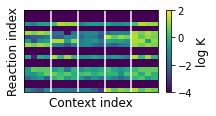

In [230]:
node = 5
sparsity = 0.5
seed = 6
path = f"/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_rhoedge_seed_nt/{node}_{sparsity}_{seed}/"
results_path = path + "results.pkl"
with open(results_path, "rb") as file:
    data = pickle.load(file)

# Extract components
results = data['results']
history = data['history']
params = data['params']
execution_time = data['execution_time']

needed_dof = 2 * params['D'] * params['N'] * (params['N']+1)
#available_dof = params['sparsity_rho_all'] * params['sparsity_rho_edge'] * (params['N']+1) * params['D'] * params['n_nodes'] * (params['n_nodes']-1)
model = load_model(params, path, print_creation=False)

K_mat = np.array(model.K_params.detach().numpy() * model.K_params_mask.detach().numpy())
#K_mat = np.array(model.K_params_mask.detach().numpy())

(n1, n2, n3) = K_mat.shape

eps = 1e-8
K_flat = np.array([np.abs(K_mat[i, j, :]) for i in range(n1) for j in range(n1) if i != j])
#K_flat = (K_flat >= eps).astype(int)


fig, ax = plt.subplots(figsize=(3, 1.5))
fs = 12

mat = K_mat[:, :, 5]
im = ax.imshow(np.log10(K_flat + eps), cmap='viridis', aspect='auto', origin='lower', vmin = -4, vmax = 2)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("log K", size = fs)
ax.set_xlabel('Context index', fontsize=fs)
ax.set_xticks([])
ax.set_ylabel('Reaction index', fontsize=fs)
ax.set_yticks([])

# Add vertical lines at every 4th index
for i in range(4, K_flat.shape[1], 4):
    ax.axvline(x=i - 0.5, color='white', linestyle='-', linewidth=2, alpha=0.75)

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'EdgeSparsityPattern.png', dpi=300, bbox_inches='tight')



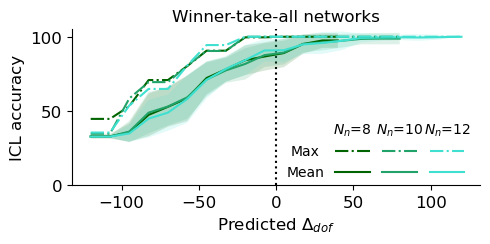

In [16]:
# Import necessary components
import torch
import numpy as np
import pickle
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from models.wta_icl import load_model

# === Configuration ===
seeds = np.arange(1, 31, 1)
nodes = [8,10,12]
sparsities = np.round(np.arange(0.0, 1.1, 0.1), 1)

# === Color utilities ===
def interpolate_color(color1, color2, t):
    c1 = np.array(mcolors.to_rgb(color1))
    c2 = np.array(mcolors.to_rgb(color2))
    return c1 + t * (c2 - c1)

def adjust_lightness(color, amount=0.5):
    c = mcolors.to_rgb(color)
    c = np.array(mcolors.rgb_to_hsv(c))
    c[2] = min(1.0, c[2] * amount)
    return mcolors.hsv_to_rgb(c)

def create_table_legend(ax, row_labels, col_labels, colors_matrix, linestyles,
                        loc='lower right', fontsize=10, markersize=6, linewidth=1.5, bbox_to_anchor=None):
    """
    Create a table-style legend with different linestyles per row.
    """
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    from matplotlib.legend_handler import HandlerBase
    from matplotlib.text import Text
    
    class TextHandler(HandlerBase):
        def __init__(self, text, fontsize):
            self.text = text
            self.fontsize = fontsize
            super().__init__()
        
        def create_artists(self, legend, orig_handle, xdescent, ydescent, 
                           width, height, fontsize, trans):
            txt = Text(width/2, height/2, self.text, 
                       fontsize=self.fontsize,
                       ha='center', va='center',
                       transform=trans)
            return [txt]
    
    n_rows = len(row_labels)
    n_cols = len(col_labels)
    
    handles = []
    labels = []
    handler_map = {}
    
    def spacer_handle():
        return Patch(facecolor='none', edgecolor='none')
    
    # Column 0: empty corner + row labels
    handles.append(spacer_handle())
    labels.append('')
    
    for i in range(n_rows):
        h = spacer_handle()
        handles.append(h)
        handler_map[h] = TextHandler(row_labels[i], fontsize)
        labels.append('')
    
    # Columns 1+: column header + line samples
    for j in range(n_cols):
        h = spacer_handle()
        handles.append(h)
        handler_map[h] = TextHandler(col_labels[j], fontsize)
        labels.append('')
        
        for i in range(n_rows):
            handles.append(Line2D([0], [0],
                                  color=colors_matrix[i][j],
                                  linestyle=linestyles[i],
                                  linewidth=linewidth))
            labels.append('')
    
    legend = ax.legend(
        handles, labels,
        loc=loc,
        ncol=n_cols + 1,
        fontsize=fontsize,
        bbox_to_anchor=bbox_to_anchor,
        frameon=False,
        handlelength=2.5,
        handleheight=1.0,
        handletextpad=0.1,
        columnspacing=0.8,
        labelspacing=0.5,
        borderaxespad=-0.25,
        handler_map=handler_map,
    )
    
    return legend

color_map = [interpolate_color(adjust_lightness('darkgreen', 1.0), 
                                adjust_lightness('turquoise', 1.0), 
                                i / max(len(nodes) - 1, 1)) for i in range(len(nodes))]
colors = {node: color_map[i] for i, node in enumerate(nodes)}

# === Data collection ===
# Structure: data[condition][node][sparsity] = {'dof_diff': [], 'icl_acc': []}
data = {
    'rhoall': {node: {s: {'dof_diff': [], 'icl_acc': []} for s in sparsities} for node in nodes},
    'rhoedge': {node: {s: {'dof_diff': [], 'icl_acc': []} for s in sparsities} for node in nodes}
}

base_paths = {
    'rhoall': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/wta_n_nodes_rhoall_seed",
    'rhoedge': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/wta_n_nodes_rhoedge_seed"
}

for condition, base_path in base_paths.items():
    for node in nodes:
        for sparsity in sparsities:
            for seed in seeds:
                path = f"{base_path}/{node}_{sparsity}_{seed}/"
                with open(path + "results.pkl", "rb") as f:
                    d = pickle.load(f)
                
                params = d['params']
                history = d['history']
                
                model = load_model(params, path, print_creation=False)
                needed_dof = 2 * params['D'] * (params['N']-1) * (params['N'] + 1)
                available_dof = model.get_non_zero_count_W()
                dof_diff = available_dof - needed_dof
                
                icl_acc = [v for v in history['icl_acc'] if v is not None][-1]
                icl_acc_array = [v for v in history['icl_acc'] if v is not None]
                icl_acc = np.max(icl_acc_array)
                
                data[condition][node][sparsity]['dof_diff'].append(dof_diff)
                data[condition][node][sparsity]['icl_acc'].append(icl_acc)

# === Plotting ===
#fig, ax_main = plt.subplots(figsize=(4, 4.25))
fig, ax_main = plt.subplots(figsize=(5, 2.55))
fs = 12
lw = 1.5
window_width = 50

# Main plot: DOF difference vs ICL accuracy (combined conditions)
for node in nodes:
    # Combine both conditions for main plot
    all_dof_diff = []
    all_icl_acc = []
    for condition in ['rhoedge']:#, 'rhoedge']:
        for sparsity in sparsities:
            all_dof_diff.extend(data[condition][node][sparsity]['dof_diff'])
            all_icl_acc.extend(data[condition][node][sparsity]['icl_acc'])
    
    all_dof_diff = np.array(all_dof_diff)
    all_icl_acc = np.array(all_icl_acc)
    
    # # Plot scatter points
    # ax_main.scatter(all_dof_diff, all_icl_acc, color=colors[node], alpha=0.3, s=20, edgecolors='none')
    
    # Sort for running window
    sorted_idx = np.argsort(all_dof_diff)
    sorted_dof = all_dof_diff[sorted_idx]
    sorted_acc = all_icl_acc[sorted_idx]
    
    # Running window statistics - extend to full data range
    data_min = sorted_dof.min()
    data_max = sorted_dof.max()
    
    # Create window centers that extend to the data boundaries
    window_centers = np.arange(data_min, data_max + 1, window_width / 4)
    
    # Ensure we have points at the extremes
    if window_centers[0] > data_min:
        window_centers = np.concatenate([[data_min], window_centers])
    if window_centers[-1] < data_max:
        window_centers = np.concatenate([window_centers, [data_max]])
    
    centers_valid, means, stds, maxes = [], [], [], []
    
    for center in window_centers:
        mask = np.abs(sorted_dof - center) <= window_width / 2
        if mask.sum() > 0:
            centers_valid.append(center)
            means.append(sorted_acc[mask].mean())
            stds.append(sorted_acc[mask].std())
            maxes.append(sorted_acc[mask].max())
    
    centers_valid = np.array(centers_valid)
    means, stds, maxes = np.array(means), np.array(stds), np.array(maxes)
    
    ax_main.plot(centers_valid, means, color=colors[node], linewidth=lw, label=f'$N_n$={node}')
    ax_main.plot(centers_valid, maxes, color=colors[node], linestyle='-.', linewidth=lw, zorder=10, label=f'$N_n$={node}')
    ax_main.fill_between(centers_valid, means - stds, means + stds, color=colors[node], alpha=0.15, edgecolor='none')

ax_main.axvline(x=0, color='black', linewidth=1.5, zorder=-10, linestyle=':')
ax_main.set_xlabel(r'Predicted $\Delta_{dof}$', fontsize=fs)
ax_main.set_ylabel('ICL accuracy', fontsize=fs)
ax_main.set_ylim(0, 105)
ax_main.tick_params(labelsize=fs)
ax_main.set_title('Winner-take-all networks', fontsize=fs)
ax_main.spines['top'].set_visible(False)
ax_main.spines['right'].set_visible(False)
#ax_main.legend(fontsize=fs-2, frameon=False, loc='upper right', bbox_to_anchor=(1, 0.9))

colors_matrix = [
    [colors[node] for node in nodes],  # Max row
    [colors[node] for node in nodes],  # Mean row
]
create_table_legend(
    ax_main,
    row_labels=['Max', 'Mean'],
    col_labels=[f'$N_n$={node}' for node in nodes],
    colors_matrix=colors_matrix,
    linestyles=['-.', '-'],  # Max is dash-dot, Mean is solid
    loc='upper right',
    fontsize=fs-2,
    bbox_to_anchor=(0.97, 0.4),
    linewidth=lw
)


plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'SparsitiesAccuracyWTA.png', dpi=300, bbox_inches='tight')

ICL accuracy for 5 0.04 17 is 0.2
ICL accuracy for 5 0.12 23 is 0.4
ICL accuracy for 5 0.14 23 is 0.4
ICL accuracy for 6 0.04 5 is 0.6
ICL accuracy for 6 0.06 28 is 0.0


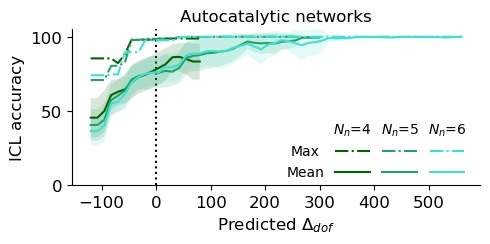

In [21]:
# Import necessary components
import torch
import numpy as np
import pickle
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from models.nonlinear_markov_icl import load_model

# === Configuration ===
seeds = np.arange(1, 31, 1)
nodes = [4,5,6]
sparsities = np.round(np.arange(0.0, 0.22, 0.02), 2)

# === Color utilities ===
def interpolate_color(color1, color2, t):
    c1 = np.array(mcolors.to_rgb(color1))
    c2 = np.array(mcolors.to_rgb(color2))
    return c1 + t * (c2 - c1)

def adjust_lightness(color, amount=0.5):
    c = mcolors.to_rgb(color)
    c = np.array(mcolors.rgb_to_hsv(c))
    c[2] = min(1.0, c[2] * amount)
    return mcolors.hsv_to_rgb(c)

def create_table_legend(ax, row_labels, col_labels, colors_matrix, linestyles,
                        loc='lower right', fontsize=10, markersize=6, linewidth=1.5, bbox_to_anchor=None):
    """
    Create a table-style legend with different linestyles per row.
    """
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    from matplotlib.legend_handler import HandlerBase
    from matplotlib.text import Text
    
    class TextHandler(HandlerBase):
        def __init__(self, text, fontsize):
            self.text = text
            self.fontsize = fontsize
            super().__init__()
        
        def create_artists(self, legend, orig_handle, xdescent, ydescent, 
                           width, height, fontsize, trans):
            txt = Text(width/2, height/2, self.text, 
                       fontsize=self.fontsize,
                       ha='center', va='center',
                       transform=trans)
            return [txt]
    
    n_rows = len(row_labels)
    n_cols = len(col_labels)
    
    handles = []
    labels = []
    handler_map = {}
    
    def spacer_handle():
        return Patch(facecolor='none', edgecolor='none')
    
    # Column 0: empty corner + row labels
    handles.append(spacer_handle())
    labels.append('')
    
    for i in range(n_rows):
        h = spacer_handle()
        handles.append(h)
        handler_map[h] = TextHandler(row_labels[i], fontsize)
        labels.append('')
    
    # Columns 1+: column header + line samples
    for j in range(n_cols):
        h = spacer_handle()
        handles.append(h)
        handler_map[h] = TextHandler(col_labels[j], fontsize)
        labels.append('')
        
        for i in range(n_rows):
            handles.append(Line2D([0], [0],
                                  color=colors_matrix[i][j],
                                  linestyle=linestyles[i],
                                  linewidth=linewidth))
            labels.append('')
    
    legend = ax.legend(
        handles, labels,
        loc=loc,
        ncol=n_cols + 1,
        fontsize=fontsize,
        bbox_to_anchor=bbox_to_anchor,
        frameon=False,
        handlelength=2.5,
        handleheight=1.0,
        handletextpad=0.1,
        columnspacing=0.8,
        labelspacing=0.5,
        borderaxespad=-0.25,
        handler_map=handler_map,
    )
    
    return legend

color_map = [interpolate_color(adjust_lightness('darkgreen', 1.0), 
                                adjust_lightness('turquoise', 1.0), 
                                i / max(len(nodes) - 1, 1)) for i in range(len(nodes))]
colors = {node: color_map[i] for i, node in enumerate(nodes)}

# === Data collection ===
# Structure: data[condition][node][sparsity] = {'dof_diff': [], 'icl_acc': []}
data = {
    'rhoall': {node: {s: {'dof_diff': [], 'icl_acc': []} for s in sparsities} for node in nodes},
    'rhoedge': {node: {s: {'dof_diff': [], 'icl_acc': []} for s in sparsities} for node in nodes}
}

base_paths = {
    #'rhoall': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/WTA_n_nodes_rhoall_seed",
    'rhoedge': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/nlm_n_nodes_rhoedge_seed_f"
}

for condition, base_path in base_paths.items():
    for node in nodes:
        for sparsity in sparsities:
            for seed in seeds:
                try:
                    path = f"{base_path}/{node}_{sparsity}_{seed}/"
                    with open(path + "results.pkl", "rb") as f:
                        d = pickle.load(f)
                    
                    params = d['params']
                    history = d['history']
                    
                    model = load_model(params, path, print_creation=False)
                    needed_dof = 2 * params['D'] * (params['N']-1) * (params['N'] + 1)
                    available_dof = model.get_non_zero_count_L()
                    dof_diff = available_dof - needed_dof
                    
                    icl_acc = [v for v in history['icl_acc'] if v is not None][-1]
                    icl_acc_array = [v for v in history['icl_acc'] if v is not None]
                    icl_acc = np.max(icl_acc_array)
                    if icl_acc_array[-1] < 1:
                        print(f"ICL accuracy for {node} {sparsity} {seed} is {icl_acc_array[-1]}")
                        continue

                    
                    data[condition][node][sparsity]['dof_diff'].append(dof_diff)
                    data[condition][node][sparsity]['icl_acc'].append(icl_acc)
                except:
                    continue

# === Plotting ===
#fig, ax_main = plt.subplots(figsize=(4, 4.25))
#fig, ax_main = plt.subplots(figsize=(10, 5))
fig, ax_main = plt.subplots(figsize=(5, 2.55))
fs = 12
lw = 1.5
window_width = 50

# Main plot: DOF difference vs ICL accuracy (combined conditions)
for node in nodes:
    # Combine both conditions for main plot
    all_dof_diff = []
    all_icl_acc = []
    for condition in ['rhoedge']:#, 'rhoedge']:
        for sparsity in sparsities:
            all_dof_diff.extend(data[condition][node][sparsity]['dof_diff'])
            all_icl_acc.extend(data[condition][node][sparsity]['icl_acc'])
    
    all_dof_diff = np.array(all_dof_diff)
    all_icl_acc = np.array(all_icl_acc)
    
    # # Plot scatter points
    # ax_main.scatter(all_dof_diff, all_icl_acc, color=colors[node], alpha=0.3, s=20, edgecolors='none')
    
    # Sort for running window
    sorted_idx = np.argsort(all_dof_diff)
    sorted_dof = all_dof_diff[sorted_idx]
    sorted_acc = all_icl_acc[sorted_idx]
    
    # Running window statistics - extend to full data range
    data_min = sorted_dof.min()
    data_max = sorted_dof.max()
    
    # Create window centers that extend to the data boundaries
    window_centers = np.arange(data_min, data_max + 1, window_width / 4)
    
    # Ensure we have points at the extremes
    if window_centers[0] > data_min:
        window_centers = np.concatenate([[data_min], window_centers])
    if window_centers[-1] < data_max:
        window_centers = np.concatenate([window_centers, [data_max]])
    
    centers_valid, means, stds, maxes = [], [], [], []
    
    for center in window_centers:
        mask = np.abs(sorted_dof - center) <= window_width / 2
        if mask.sum() > 0:
            centers_valid.append(center)
            means.append(sorted_acc[mask].mean())
            stds.append(sorted_acc[mask].std())
            maxes.append(sorted_acc[mask].max())
    
    centers_valid = np.array(centers_valid)
    means, stds, maxes = np.array(means), np.array(stds), np.array(maxes)
    
    ax_main.plot(centers_valid, means, color=colors[node], linewidth=lw, label=f'$N_n$={node}')
    ax_main.plot(centers_valid, maxes, color=colors[node], linestyle='-.', linewidth=lw, zorder=10, label=f'$N_n$={node}')
    ax_main.fill_between(centers_valid, means - stds, means + stds, color=colors[node], alpha=0.15, edgecolor='none')

ax_main.axvline(x=0, color='black', linewidth=1.5, zorder=-10, linestyle=':')
ax_main.set_xlabel(r'Predicted $\Delta_{dof}$', fontsize=fs)
ax_main.set_ylabel('ICL accuracy', fontsize=fs)
ax_main.set_ylim(0, 105)
ax_main.tick_params(labelsize=fs)
ax_main.set_title('Autocatalytic networks', fontsize=fs)
ax_main.spines['top'].set_visible(False)
ax_main.spines['right'].set_visible(False)
#ax_main.legend(fontsize=fs-2, frameon=False, loc='upper right', bbox_to_anchor=(1, 0.9))

colors_matrix = [
    [colors[node] for node in nodes],  # Max row
    [colors[node] for node in nodes],  # Mean row
]
create_table_legend(
    ax_main,
    row_labels=['Max', 'Mean'],
    col_labels=[f'$N_n$={node}' for node in nodes],
    colors_matrix=colors_matrix,
    linestyles=['-.', '-'],  # Max is dash-dot, Mean is solid
    loc='upper right',
    fontsize=fs-2,
    bbox_to_anchor=(0.97, 0.4),
    linewidth=lw
)


plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'SparsitiesAccuracyNLM.png', dpi=300, bbox_inches='tight')

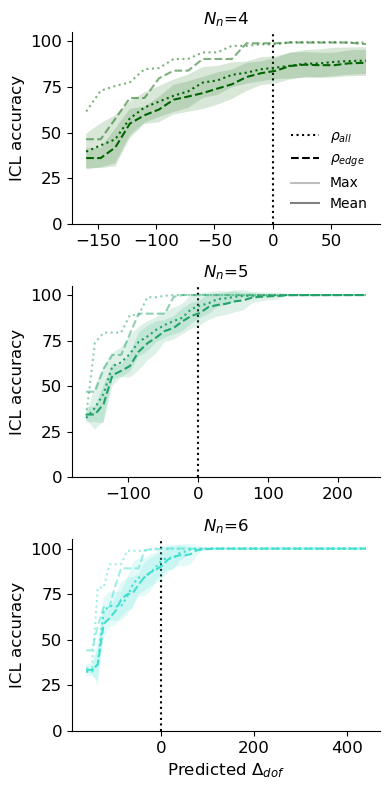

In [19]:
# Import necessary components
import torch
import numpy as np
import pickle
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from models.markov_icl import load_model

# === Configuration ===
seeds = np.arange(1, 31, 1)
nodes = [4,5,6]
sparsities = np.round(np.arange(0.0, 1.1, 0.1), 1)

# === Color utilities ===
def interpolate_color(color1, color2, t):
    c1 = np.array(mcolors.to_rgb(color1))
    c2 = np.array(mcolors.to_rgb(color2))
    return c1 + t * (c2 - c1)

def adjust_lightness(color, amount=0.5):
    c = mcolors.to_rgb(color)
    c = np.array(mcolors.rgb_to_hsv(c))
    c[2] = min(1.0, c[2] * amount)
    return mcolors.hsv_to_rgb(c)

color_map = [interpolate_color(adjust_lightness('darkgreen', 1.0), 
                                adjust_lightness('turquoise', 1.0), 
                                i / max(len(nodes) - 1, 1)) for i in range(len(nodes))]
colors = {node: color_map[i] for i, node in enumerate(nodes)}

# === Data collection ===
# Structure: data[condition][node][sparsity] = {'dof_diff': [], 'icl_acc': []}
data = {
    'rhoall': {node: {s: {'dof_diff': [], 'icl_acc': []} for s in sparsities} for node in nodes},
    'rhoedge': {node: {s: {'dof_diff': [], 'icl_acc': []} for s in sparsities} for node in nodes}
}

base_paths = {
    'rhoall': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_rhoall_seed_nt",
    'rhoedge': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_rhoedge_seed_nt"
}

for condition, base_path in base_paths.items():
    for node in nodes:
        for sparsity in sparsities:
            for seed in seeds:
                path = f"{base_path}/{node}_{sparsity}_{seed}/"
                with open(path + "results.pkl", "rb") as f:
                    d = pickle.load(f)
                
                params = d['params']
                history = d['history']
                
                model = load_model(params, path, print_creation=False)
                needed_dof = 2 * params['D'] * params['N'] * (params['N'] + 1)
                available_dof = model.get_non_zero_count_K()
                dof_diff = available_dof - needed_dof
                
                icl_acc = [v for v in history['icl_acc'] if v is not None][-1]
                icl_acc_array = [v for v in history['icl_acc'] if v is not None]
                icl_acc = np.max(icl_acc_array)
                
                data[condition][node][sparsity]['dof_diff'].append(dof_diff)
                data[condition][node][sparsity]['icl_acc'].append(icl_acc)

# === Plotting ===
fig, axes = plt.subplots(3, 1, figsize=(4, 8))
fs = 12
lw = 1.5
window_width = 50

# Linestyles for conditions
linestyles_main = {'rhoall': ':', 'rhoedge': '--'}

for idx, node in enumerate(nodes):
    ax = axes[idx]
    
    for condition in ['rhoall', 'rhoedge']:
        # Collect data for this condition
        all_dof_diff = []
        all_icl_acc = []
        for sparsity in sparsities:
            all_dof_diff.extend(data[condition][node][sparsity]['dof_diff'])
            all_icl_acc.extend(data[condition][node][sparsity]['icl_acc'])
        
        all_dof_diff = np.array(all_dof_diff)
        all_icl_acc = np.array(all_icl_acc)
        
        # Sort for running window
        sorted_idx = np.argsort(all_dof_diff)
        sorted_dof = all_dof_diff[sorted_idx]
        sorted_acc = all_icl_acc[sorted_idx]
        
        # Running window statistics - extend to full data range
        data_min = sorted_dof.min()
        data_max = sorted_dof.max()
        
        # Create window centers that extend to the data boundaries
        window_centers = np.arange(data_min, data_max + 1, window_width / 4)
        
        # Ensure we have points at the extremes
        if window_centers[0] > data_min:
            window_centers = np.concatenate([[data_min], window_centers])
        if window_centers[-1] < data_max:
            window_centers = np.concatenate([window_centers, [data_max]])
        centers_valid, means, stds, maxes = [], [], [], []
        
        for center in window_centers:
            mask = np.abs(sorted_dof - center) <= window_width / 2
            if mask.sum() > 0:
                centers_valid.append(center)
                means.append(sorted_acc[mask].mean())
                stds.append(sorted_acc[mask].std())
                maxes.append(sorted_acc[mask].max())
        
        centers_valid = np.array(centers_valid)
        means, stds, maxes = np.array(means), np.array(stds), np.array(maxes)
        
        # Plot mean with fill
        ax.plot(centers_valid, means, color=colors[node], 
                linestyle=linestyles_main[condition], linewidth=lw,
                label=f'Mean ({condition})')
        ax.fill_between(centers_valid, means - stds, means + stds, 
                        color=colors[node], alpha=0.15, edgecolor='none')
        
        # Plot max (no fill)
        ax.plot(centers_valid, maxes, color=colors[node], 
                linestyle=linestyles_main[condition], linewidth=lw, 
                zorder=10, alpha=0.5,
                label=f'Max ({condition})')
    
    ax.axvline(x=0, color='black', linewidth=1.5, zorder=-10, linestyle=':')
    ax.set_ylabel('ICL accuracy', fontsize=fs)
    ax.set_ylim(0, 105)
    ax.tick_params(labelsize=fs)
    ax.set_title(f'$N_n$={node}', fontsize=fs)#, color=colors[node])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Add legend for first subplot
    if idx == 0:
        # Create custom legend entries
        from matplotlib.lines import Line2D
        legend_elements = [
            Line2D([0], [0], color='black', linestyle=':', linewidth=lw, label=r'$\rho_{all}$'),
            Line2D([0], [0], color='black', linestyle='--', linewidth=lw, label=r'$\rho_{edge}$'),
            Line2D([0], [0], color='gray', linestyle='-', linewidth=lw, alpha=0.5, label='Max'),
            Line2D([0], [0], color='gray', linestyle='-', linewidth=lw, label='Mean')
        ]
        ax.legend(handles=legend_elements, fontsize=fs-2, frameon=False, loc='lower right')
    
    # Only add x-label to bottom subplot
    if idx == len(nodes) - 1:
        ax.set_xlabel(r'Predicted $\Delta_{dof}$', fontsize=fs)

plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'SparsitiesAccuracyMarkovSplit.png', dpi=300, bbox_inches='tight')

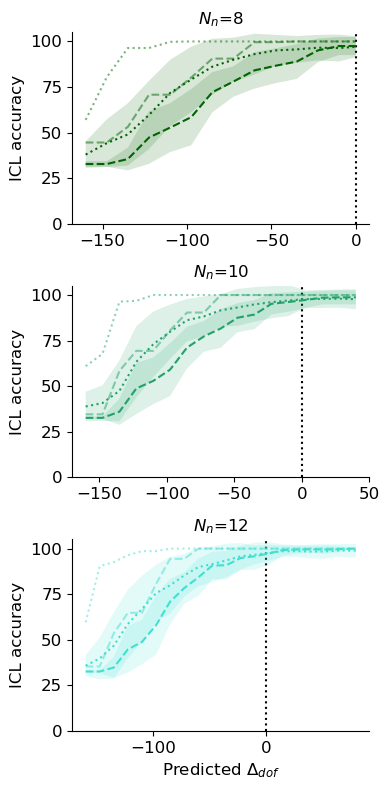

In [18]:
from models.wta_icl import load_model

# === Data collection ===
# Structure: data[condition][node][sparsity] = {'dof_diff': [], 'icl_acc': []}

nodes = [8,10,12]
sparsities = np.round(np.arange(0.0, 1.1, 0.1), 1)

data = {
    'rhoall': {node: {s: {'dof_diff': [], 'icl_acc': []} for s in sparsities} for node in nodes},
    'rhoedge': {node: {s: {'dof_diff': [], 'icl_acc': []} for s in sparsities} for node in nodes}
}

base_paths = {
    'rhoall': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/wta_n_nodes_rhoall_seed",
    'rhoedge': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/wta_n_nodes_rhoedge_seed"
}

color_map = [interpolate_color(adjust_lightness('darkgreen', 1.0), 
                                adjust_lightness('turquoise', 1.0), 
                                i / max(len(nodes) - 1, 1)) for i in range(len(nodes))]
colors = {node: color_map[i] for i, node in enumerate(nodes)}


for condition, base_path in base_paths.items():
    for node in nodes:
        for sparsity in sparsities:
            for seed in seeds:
                path = f"{base_path}/{node}_{sparsity}_{seed}/"
                with open(path + "results.pkl", "rb") as f:
                    d = pickle.load(f)
                
                params = d['params']
                history = d['history']
                
                model = load_model(params, path, print_creation=False)
                needed_dof = 2 * params['D'] * params['N'] * (params['N'] + 1)
                available_dof = model.get_non_zero_count_W()
                dof_diff = available_dof - needed_dof
                
                #icl_acc = [v for v in history['icl_acc'] if v is not None][-1]
                icl_acc_array = [v for v in history['icl_acc'] if v is not None]
                icl_acc = np.max(icl_acc_array)
                
                data[condition][node][sparsity]['dof_diff'].append(dof_diff)
                data[condition][node][sparsity]['icl_acc'].append(icl_acc)

# === Plotting ===
fig, axes = plt.subplots(3, 1, figsize=(4, 8))
fs = 12
lw = 1.5
window_width = 50

# Linestyles for conditions
linestyles_main = {'rhoall': ':', 'rhoedge': '--'}

for idx, node in enumerate(nodes):
    ax = axes[idx]
    
    for condition in ['rhoall', 'rhoedge']:
        # Collect data for this condition
        all_dof_diff = []
        all_icl_acc = []
        for sparsity in sparsities:
            all_dof_diff.extend(data[condition][node][sparsity]['dof_diff'])
            all_icl_acc.extend(data[condition][node][sparsity]['icl_acc'])
        
        all_dof_diff = np.array(all_dof_diff)
        all_icl_acc = np.array(all_icl_acc)
        
        # Sort for running window
        sorted_idx = np.argsort(all_dof_diff)
        sorted_dof = all_dof_diff[sorted_idx]
        sorted_acc = all_icl_acc[sorted_idx]
        
        # Running window statistics - extend to full data range
        data_min = sorted_dof.min()
        data_max = sorted_dof.max()
        
        # Create window centers that extend to the data boundaries
        window_centers = np.arange(data_min, data_max + 1, window_width / 4)
        
        # Ensure we have points at the extremes
        if window_centers[0] > data_min:
            window_centers = np.concatenate([[data_min], window_centers])
        if window_centers[-1] < data_max:
            window_centers = np.concatenate([window_centers, [data_max]])
        centers_valid, means, stds, maxes = [], [], [], []
        
        for center in window_centers:
            mask = np.abs(sorted_dof - center) <= window_width / 2
            if mask.sum() > 0:
                centers_valid.append(center)
                means.append(sorted_acc[mask].mean())
                stds.append(sorted_acc[mask].std())
                maxes.append(sorted_acc[mask].max())
        
        centers_valid = np.array(centers_valid)
        means, stds, maxes = np.array(means), np.array(stds), np.array(maxes)
        
        # Plot mean with fill
        ax.plot(centers_valid, means, color=colors[node], 
                linestyle=linestyles_main[condition], linewidth=lw,
                label=f'Mean ({condition})')
        ax.fill_between(centers_valid, means - stds, means + stds, 
                        color=colors[node], alpha=0.15, edgecolor='none')
        
        # Plot max (no fill)
        ax.plot(centers_valid, maxes, color=colors[node], 
                linestyle=linestyles_main[condition], linewidth=lw, 
                zorder=10, alpha=0.5,
                label=f'Max ({condition})')
    
    ax.axvline(x=0, color='black', linewidth=1.5, zorder=-10, linestyle=':')
    ax.set_ylabel('ICL accuracy', fontsize=fs)
    ax.set_ylim(0, 105)
    ax.tick_params(labelsize=fs)
    ax.set_title(f'$N_n$={node}', fontsize=fs)#, color=colors[node])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Add legend for first subplot
    # if idx == 0:
    #     # Create custom legend entries
    #     from matplotlib.lines import Line2D
    #     legend_elements = [
    #         Line2D([0], [0], color='black', linestyle=':', linewidth=lw, label=r'$\rho_{all}$'),
    #         Line2D([0], [0], color='black', linestyle='--', linewidth=lw, label=r'$\rho_{edge}$'),
    #         Line2D([0], [0], color='gray', linestyle='-', linewidth=lw, label='Mean'),
    #         Line2D([0], [0], color='gray', linestyle='-', linewidth=lw, alpha=0.5, label='Max')
    #     ]
    #     ax.legend(handles=legend_elements, fontsize=fs-2, frameon=False, loc='lower right')
    
    # Only add x-label to bottom subplot
    if idx == len(nodes) - 1:
        ax.set_xlabel(r'Predicted $\Delta_{dof}$', fontsize=fs)

plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'SparsitiesAccuracyWTASplit.png', dpi=300, bbox_inches='tight')

ICL accuracy for 5 0.02 24 is 0.6
ICL accuracy for 6 0.02 18 is 0.2
ICL accuracy for 6 0.02 28 is 0.2
ICL accuracy for 6 0.04 29 is 0.8
Error loading results for rhoedge 4_0.08_6
Error loading results for rhoedge 4_0.1_6
Error loading results for rhoedge 4_0.12_6
Error loading results for rhoedge 4_0.2_25
Error loading results for rhoedge 4_0.2_27
ICL accuracy for 5 0.04 17 is 0.2
Error loading results for rhoedge 5_0.08_1
ICL accuracy for 5 0.12 23 is 0.4
ICL accuracy for 5 0.14 23 is 0.4
ICL accuracy for 6 0.04 5 is 0.6
ICL accuracy for 6 0.06 28 is 0.0


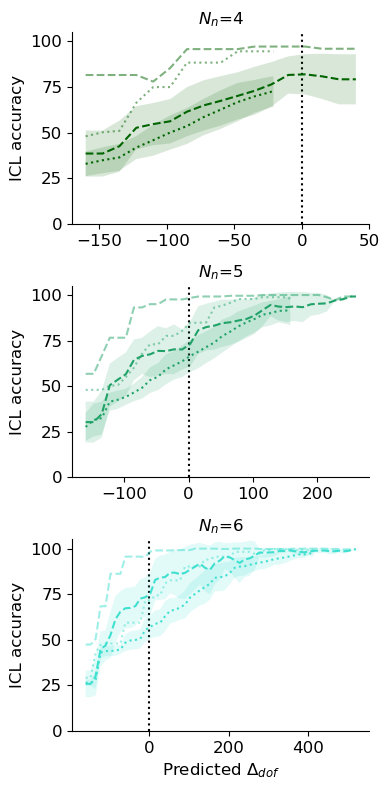

In [20]:
from models.nonlinear_markov_icl import load_model

# === Data collection ===
# Structure: data[condition][node][sparsity] = {'dof_diff': [], 'icl_acc': []}

nodes = [4,5,6]
sparsities = np.round(np.arange(0.0, 0.22, 0.02), 2)
seeds = np.arange(1, 31, 1)

data = {
    'rhoall': {node: {s: {'dof_diff': [], 'icl_acc': []} for s in sparsities} for node in nodes},
    'rhoedge': {node: {s: {'dof_diff': [], 'icl_acc': []} for s in sparsities} for node in nodes}
}

base_paths = {
    'rhoall': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/nlm_n_nodes_rhoall_seed_f",
    'rhoedge': "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/nlm_n_nodes_rhoedge_seed_f"
}

color_map = [interpolate_color(adjust_lightness('darkgreen', 1.0), 
                                adjust_lightness('turquoise', 1.0), 
                                i / max(len(nodes) - 1, 1)) for i in range(len(nodes))]
colors = {node: color_map[i] for i, node in enumerate(nodes)}


for condition, base_path in base_paths.items():
    for node in nodes:
        for sparsity in sparsities:
            for seed in seeds:
                try:
                    path = f"{base_path}/{node}_{sparsity}_{seed}/"
                    with open(path + "results.pkl", "rb") as f:
                        d = pickle.load(f)
                    
                    params = d['params']
                    history = d['history']
                    
                    model = load_model(params, path, print_creation=False)
                    needed_dof = 2 * params['D'] * params['N'] * (params['N'] + 1)
                    available_dof = model.get_non_zero_count_L()
                    dof_diff = available_dof - needed_dof
                    icl_acc_array = [v for v in history['icl_acc'] if v is not None]
                    icl_acc = np.max(icl_acc_array)
                    icl_acc = icl_acc_array[-1]
                    if icl_acc_array[-1] < 1:
                        print(f"ICL accuracy for {node} {sparsity} {seed} is {icl_acc_array[-1]}")
                        continue
                    
                    data[condition][node][sparsity]['dof_diff'].append(dof_diff)
                    data[condition][node][sparsity]['icl_acc'].append(icl_acc)
                except:
                    print(f"Error loading results for {condition} {node}_{sparsity}_{seed}")
                    continue

# === Plotting ===
fig, axes = plt.subplots(3, 1, figsize=(4, 8))
fs = 12
lw = 1.5
window_width = 50

# Linestyles for conditions
linestyles_main = {'rhoall': ':', 'rhoedge': '--'}
for idx, node in enumerate(nodes):
    ax = axes[idx]
    
    for condition in ['rhoall', 'rhoedge']:
        # Collect data for this condition
        all_dof_diff = []
        all_icl_acc = []
        for sparsity in sparsities:
            all_dof_diff.extend(data[condition][node][sparsity]['dof_diff'])
            all_icl_acc.extend(data[condition][node][sparsity]['icl_acc'])
        
        all_dof_diff = np.array(all_dof_diff)
        all_icl_acc = np.array(all_icl_acc)
        
        # # Scatter plot with different markers for each condition
        # marker = '*' if condition == 'rhoedge' else 'o'
        # size = 10 if condition == 'rhoedge' else 5
        # ax.scatter(all_dof_diff, all_icl_acc, color=colors[node], 
        #           marker=marker, s=size, alpha=0.75, edgecolors='none', zorder = -10)
        
        # Sort for running window
        sorted_idx = np.argsort(all_dof_diff)
        sorted_dof = all_dof_diff[sorted_idx]
        sorted_acc = all_icl_acc[sorted_idx]
        
        # Running window statistics - extend to full data range
        data_min = sorted_dof.min()
        data_max = sorted_dof.max()
        
        # Create window centers that extend to the data boundaries
        window_centers = np.arange(data_min, data_max + 1, window_width / 4)
        
        # Ensure we have points at the extremes
        if window_centers[0] > data_min:
            window_centers = np.concatenate([[data_min], window_centers])
        if window_centers[-1] < data_max:
            window_centers = np.concatenate([window_centers, [data_max]])
        centers_valid, means, stds, maxes = [], [], [], []
        
        for center in window_centers:
            mask = np.abs(sorted_dof - center) <= window_width / 2
            if mask.sum() > 0:
                centers_valid.append(center)
                means.append(sorted_acc[mask].mean())
                stds.append(sorted_acc[mask].std())
                maxes.append(sorted_acc[mask].max())
        
        centers_valid = np.array(centers_valid)
        means, stds, maxes = np.array(means), np.array(stds), np.array(maxes)
        
        # Plot mean with fill
        ax.plot(centers_valid, means, color=colors[node], 
                linestyle=linestyles_main[condition], linewidth=lw,
                label=f'Mean ({condition})')
        ax.fill_between(centers_valid, means - stds, means + stds, 
                        color=colors[node], alpha=0.15, edgecolor='none')
        
        # Plot max (no fill)
        ax.plot(centers_valid, maxes, color=colors[node], 
                linestyle=linestyles_main[condition], linewidth=lw, 
                zorder=10, alpha=0.5,
                label=f'Max ({condition})')
    
    ax.axvline(x=0, color='black', linewidth=1.5, zorder=-10, linestyle=':')
    ax.set_ylabel('ICL accuracy', fontsize=fs)
    ax.set_ylim(0, 105)
    ax.tick_params(labelsize=fs)
    ax.set_title(f'$N_n$={node}', fontsize=fs)#, color=colors[node])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Add legend for first subplot
    # if idx == 0:
    #     # Create custom legend entries
    #     from matplotlib.lines import Line2D
    #     legend_elements = [
    #         Line2D([0], [0], color='black', linestyle=':', linewidth=lw, label=r'$\rho_{all}$'),
    #         Line2D([0], [0], color='black', linestyle='--', linewidth=lw, label=r'$\rho_{edge}$'),
    #         Line2D([0], [0], color='gray', linestyle='-', linewidth=lw, label='Mean'),
    #         Line2D([0], [0], color='gray', linestyle='-', linewidth=lw, alpha=0.5, label='Max')
    #     ]
    #     ax.legend(handles=legend_elements, fontsize=fs-2, frameon=False, loc='lower right')
    
    # Only add x-label to bottom subplot
    if idx == len(nodes) - 1:
        ax.set_xlabel(r'Predicted $\Delta_{dof}$', fontsize=fs)

plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'SparsitiesAccuracyNLMSplit.png', dpi=300, bbox_inches='tight')

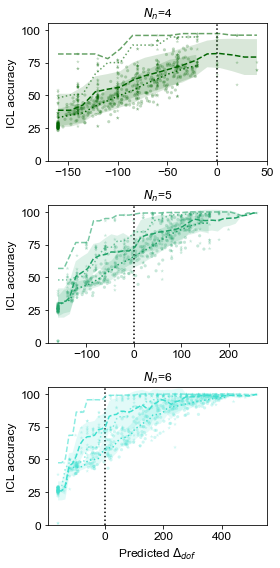

In [59]:
# === Plotting ===
fig, axes = plt.subplots(3, 1, figsize=(4, 8))
fs = 12
lw = 1.5
window_width = 50

# Linestyles for conditions
linestyles_main = {'rhoall': ':', 'rhoedge': '--'}
for idx, node in enumerate(nodes):
    ax = axes[idx]
    
    for condition in ['rhoall', 'rhoedge']:
        # Collect data for this condition
        all_dof_diff = []
        all_icl_acc = []
        for sparsity in sparsities:
            all_dof_diff.extend(data[condition][node][sparsity]['dof_diff'])
            all_icl_acc.extend(data[condition][node][sparsity]['icl_acc'])
        
        all_dof_diff = np.array(all_dof_diff)
        all_icl_acc = np.array(all_icl_acc)
        
        # Scatter plot with different markers for each condition
        marker = '*' if condition == 'rhoedge' else 'o'
        size = 15 if condition == 'rhoedge' else 10
        ax.scatter(all_dof_diff, all_icl_acc, color=colors[node], 
                  marker=marker, s=size, alpha=0.25, edgecolors='none', zorder = -10)
        
        # Sort for running window
        sorted_idx = np.argsort(all_dof_diff)
        sorted_dof = all_dof_diff[sorted_idx]
        sorted_acc = all_icl_acc[sorted_idx]
        
        # Running window statistics - extend to full data range
        data_min = sorted_dof.min()
        data_max = sorted_dof.max()
        
        # Create window centers that extend to the data boundaries
        window_centers = np.arange(data_min, data_max + 1, window_width / 4)
        
        # Ensure we have points at the extremes
        if window_centers[0] > data_min:
            window_centers = np.concatenate([[data_min], window_centers])
        if window_centers[-1] < data_max:
            window_centers = np.concatenate([window_centers, [data_max]])
        centers_valid, means, stds, maxes = [], [], [], []
        
        for center in window_centers:
            mask = np.abs(sorted_dof - center) <= window_width / 2
            if mask.sum() > 0:
                centers_valid.append(center)
                means.append(sorted_acc[mask].mean())
                stds.append(sorted_acc[mask].std())
                maxes.append(sorted_acc[mask].max())
        
        centers_valid = np.array(centers_valid)
        means, stds, maxes = np.array(means), np.array(stds), np.array(maxes)
        
        # Plot mean with fill
        ax.plot(centers_valid, means, color=colors[node], 
                linestyle=linestyles_main[condition], linewidth=lw,
                label=f'Mean ({condition})')
        ax.fill_between(centers_valid, means - stds, means + stds, 
                        color=colors[node], alpha=0.15, edgecolor='none')
        
        # Plot max (no fill)
        ax.plot(centers_valid, maxes, color=colors[node], 
                linestyle=linestyles_main[condition], linewidth=lw, 
                zorder=10, alpha=0.6,
                label=f'Max ({condition})')
    
    ax.axvline(x=0, color='black', linewidth=1.5, zorder=-15, linestyle=':')
    ax.set_ylabel('ICL accuracy', fontsize=fs)
    ax.set_ylim(0, 105)
    ax.tick_params(labelsize=fs)
    ax.set_title(f'$N_n$={node}', fontsize=fs)#, color=colors[node])
    
    # Add legend for first subplot
    # if idx == 0:
    #     # Create custom legend entries
    #     from matplotlib.lines import Line2D
    #     legend_elements = [
    #         Line2D([0], [0], color='black', linestyle=':', linewidth=lw, label=r'$\rho_{all}$'),
    #         Line2D([0], [0], color='black', linestyle='--', linewidth=lw, label=r'$\rho_{edge}$'),
    #         Line2D([0], [0], color='gray', linestyle='-', linewidth=lw, label='Mean'),
    #         Line2D([0], [0], color='gray', linestyle='-', linewidth=lw, alpha=0.5, label='Max')
    #     ]
    #     ax.legend(handles=legend_elements, fontsize=fs-2, frameon=False, loc='lower right')
    
    # Only add x-label to bottom subplot
    if idx == len(nodes) - 1:
        ax.set_xlabel(r'Predicted $\Delta_{dof}$', fontsize=fs)

plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'SparsitiesAccuracyNLMSplit.png', dpi=300, bbox_inches='tight')

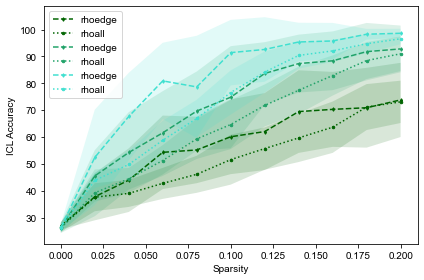

In [67]:
# Standalone plotting code
import numpy as np
import matplotlib.pyplot as plt

# Define necessary variables for standalone execution
# (These would need to be defined based on your actual data structure)
# Example structure - adjust based on your actual data:
# data = {'rhoedge': {node: {sparsity: {'icl_acc': [...]}, ...}, ...}, 
#         'rhoall': {node: {sparsity: {'icl_acc': [...]}, ...}, ...}}
# sparsities = [0.1, 0.2, 0.3, ...]  # your sparsity values
# node = 6  # or whatever node you're plotting
# colors = {6: 'blue', ...}  # color mapping
# linestyles = {'rhoedge': '--', 'rhoall': ':'}

# Create figure and axis if not already created
fig, ax_inset = plt.subplots(figsize=(6, 4))

lw = 2.0  # linewidth

for node in [4, 5, 6]:
    for condition in ['rhoedge', 'rhoall']:
        mean_acc = [np.mean(data[condition][node][s]['icl_acc']) for s in sparsities]
        std_acc = [np.std(data[condition][node][s]['icl_acc']) for s in sparsities]
        ax_inset.plot(sparsities, mean_acc, color=colors[node], 
                        linestyle=linestyles[condition], linewidth=lw-0.5, 
                        marker='o' if condition == 'rhoall' else 'd', markersize=2.5,
                        label=condition)

        ax_inset.fill_between(sparsities, 
                                np.array(mean_acc) - np.array(std_acc), 
                                np.array(mean_acc) + np.array(std_acc), 
                                color=colors[node], alpha=0.15, edgecolor='none')

ax_inset.set_xlabel('Sparsity')
ax_inset.set_ylabel('ICL Accuracy')
ax_inset.legend()
plt.tight_layout()
plt.show()


518 160


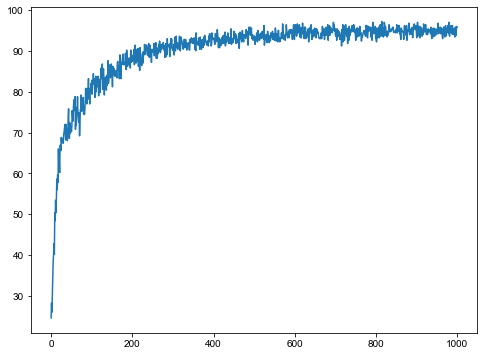

In [65]:
path = f"{base_paths['rhoall']}/{6}_{0.2}_{16}/"
with open(path + "results.pkl", "rb") as f:
    d = pickle.load(f)

params = d['params']
history = d['history']

model = load_model(params, path, print_creation=False)
needed_dof = 2 * params['D'] * params['N'] * (params['N'] + 1)
available_dof = model.get_non_zero_count_L()
print(available_dof, needed_dof)

icl_acc = [v for v in history['icl_acc'] if v is not None]

plt.figure(figsize=(8, 6))
plt.plot(icl_acc)


{'K': 128, 'L': 128, 'D': 4, 'N': 3, 'B': 1, 'epsilon': 0.001, 'seed': 1, 'exact_copy': True, 'shuffle_context': True, 'offset': 0.0, 'min_max_choice': None, 'unique_labels': False, 'n_nodes': 3, 'transform_func': 'exp', 'learn_base_rates': True, 'sparsity_rho_edge': 1.0, 'sparsity_rho_all': 1.0, 'sparsity_rho_edge_base_W': 1.0, 'base_mask_value': -inf, 'epochs': 1000, 'lr': 0.0025, 'batch_size': 50, 'train_samples': 25000, 'val_samples': 5000, 'method': 'direct_solve', 'temperature': 1.0}
  Initialized ICL Attention model (L=128 classes, attention over 3 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: -inf
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (144/144 active)
  base_W sparsity: 0.000 (9/9 active)
  Parameters: 162
{'K': 128, 'L': 128, 'D': 4, 'N': 3, 'B': 1, 'epsilon': 0.001, 'seed': 2, 'exact_copy': True, 'shuffle_context': True, 'offset': 0.0, 'min_max_choice': None, 'unique_

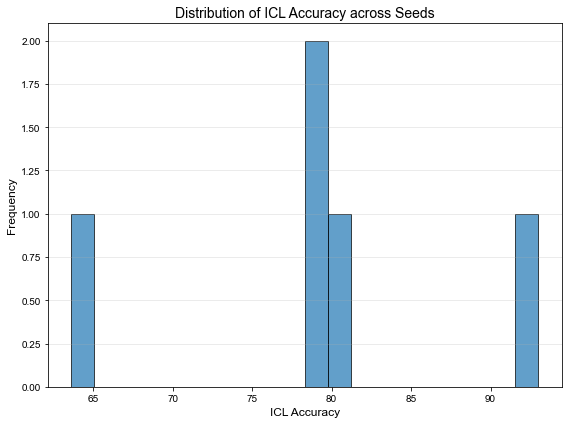

In [82]:
# Import necessary components
import torch
import numpy as np
import pickle
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from models.markov_icl import load_model

# === Configuration ===
seeds = np.arange(1, 6, 1)
data = []
base_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/3_3_seed"
for seed in seeds:
    path = f"{base_path}/{seed}/"
    with open(path + "results.pkl", "rb") as f:
        d = pickle.load(f)
    
    params = d['params']
    history = d['history']
    print(params)
    model = load_model(params, path, print_creation=True)
    needed_dof = 2 * params['D'] * params['N'] * (params['N'] + 1)
    available_dof = model.get_non_zero_count_K()
    dof_diff = available_dof - needed_dof
    
    icl_acc = [v for v in history['icl_acc'] if v is not None][-1]
    
    data.append(icl_acc)
print(np.max(data))
print(np.mean(data))
# Create histogram of ICL accuracy
plt.figure(figsize=(8, 6))
plt.hist(data, bins=20, edgecolor='black', alpha=0.7)
plt.xlabel('ICL Accuracy', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Distribution of ICL Accuracy across Seeds', fontsize=14)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


  Initialized ICL Attention model (L=128 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: -inf
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (48/48 active)
  base_W sparsity: 0.000 (4/4 active)
  Parameters: 56
  Initialized ICL Attention model (L=128 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: -inf
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (48/48 active)
  base_W sparsity: 0.000 (4/4 active)
  Parameters: 56
  Initialized ICL Attention model (L=128 classes, attention over 2 context items)
  Label modulation: False
  Base rates learnable: True
  Base mask value: -inf
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (48/48 active)
  base_W sparsity: 0.000 (4/4 active)
  Paramet

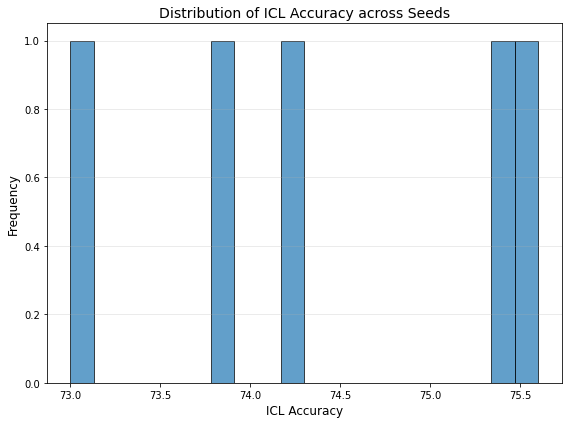

In [41]:
# Import necessary components
import torch
import numpy as np
import pickle
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from models.markov_icl import load_model

# === Configuration ===
seeds = np.arange(1, 6, 1)
data = []
base_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed/2_2"
for seed in seeds:
    path = f"{base_path}_{seed}/"
    with open(path + "results.pkl", "rb") as f:
        d = pickle.load(f)
    
    params = d['params']
    history = d['history']
    
    model = load_model(params, path, print_creation=True)
    needed_dof = 2 * params['D'] * params['N'] * (params['N'] + 1)
    available_dof = model.get_non_zero_count_K()
    dof_diff = available_dof - needed_dof
    
    icl_acc = [v for v in history['icl_acc'] if v is not None][-1]
    
    data.append(icl_acc)
print(np.max(data))
print(np.mean(data))
# Create histogram of ICL accuracy
plt.figure(figsize=(8, 6))
plt.hist(data, bins=20, edgecolor='black', alpha=0.7)
plt.xlabel('ICL Accuracy', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Distribution of ICL Accuracy across Seeds', fontsize=14)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# Baseline comparisons

Detected model types: ['markov', 'qk', 'mlp']

markov results array (param1, param2, seed):
[[[ 49.508  49.644  49.972  49.344  49.56 ]
  [ 51.18   49.492  47.456  62.756  50.264]
  [ 38.092  42.372  41.428  39.944  42.904]
  [ 32.832  34.188  35.776  46.088  35.844]
  [ 36.2    38.036  33.912  40.804  38.888]]

 [[ 49.74   49.476  50.052  49.5    49.292]
  [ 97.868  98.004  97.308  97.116  98.412]
  [ 80.932  98.     98.572  98.108  92.192]
  [ 84.468  71.008  54.392  53.1    70.272]
  [ 81.876  54.592  40.912  53.044  77.492]]

 [[ 49.504  49.868  49.884  49.656  49.42 ]
  [ 98.376  98.232  98.332  98.46   98.6  ]
  [ 99.628  99.556  99.44   99.488  99.548]
  [ 99.48   99.556  99.44   99.472  99.632]
  [ 94.688  83.572  98.716  97.52   96.8  ]]

 [[ 49.772  49.604  50.36   49.548  49.56 ]
  [ 98.608  98.068  98.372  97.852  98.66 ]
  [ 99.948  99.816  99.588  99.888  99.688]
  [ 99.912  99.884  99.768  99.968  99.832]
  [ 99.76   99.948  99.812  99.8    99.936]]

 [[ 49.748  49.812  

<ipython-input-26-4f439b21e8fb>:92: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  model_cmap = cm.get_cmap('tab10')


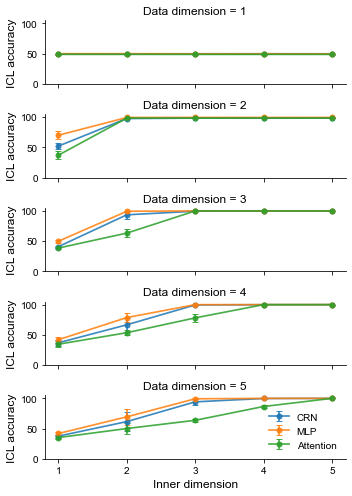

In [26]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

param1_values = np.arange(1, 6, 1)
param2_values = np.arange(1, 6, 1)
param3_values = [1, 2, 3, 4, 5]      # seeds

path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/input_proj_dim_D_seed_qkm_ent/"

def extract_best_icl(history_obj, metric = "icl_acc"):
    """
    Return dict[model_name -> best icl_acc] from a history object.

    Supports:
      1) single-model history: {'icl_acc': [...], ...}
      2) multi-model history: {'markov': {'icl_acc': [...]}, 'qk': {'icl_acc': [...]}, ...}
    """
    # Single-model case
    if isinstance(history_obj, dict) and metric in history_obj:
        vals = [v for v in history_obj[metric] if v is not None]
        return {"single": np.max(vals) if len(vals) > 0 else np.nan}

    # Multi-model case
    out = {}
    if isinstance(history_obj, dict):
        for model_name, model_hist in history_obj.items():
            if isinstance(model_hist, dict) and metric in model_hist:
                vals = [v for v in model_hist[metric] if v is not None]
                out[model_name] = np.max(vals) if len(vals) > 0 else np.nan
    return out

# model_results[model_name] -> shape (n_param1, n_param2, n_param3). Each entry: icl_acc for (param1, param2, param3/seed)
model_results = {}

for i, param1 in enumerate(param1_values):
    for j, param2 in enumerate(param2_values):
        for k, seed in enumerate(param3_values):
            run_dir = f"{path_base}{param1}_{param2}_{seed}/"
            results_path = f"{run_dir}results.pkl"
            if not os.path.exists(results_path):
                continue
            with open(results_path, "rb") as f:
                data = pickle.load(f)
            history = data.get("history", {})
            best_icl_by_model = extract_best_icl(history, metric = "train_acc")
            for model_name, best_icl in best_icl_by_model.items():
                if model_name not in model_results:
                    model_results[model_name] = np.full(
                        (len(param1_values), len(param2_values), len(param3_values)),
                        np.nan,
                    )
                model_results[model_name][i, j, k] = best_icl

print("Detected model types:", list(model_results.keys()))
for model_name, grid in model_results.items():
    print(f"\n{model_name} results array (param1, param2, seed):")
    print(grid)

# ---- Plotting: One row per param2 ----
import matplotlib.cm as cm
import matplotlib.colors as mcolors

fs = 12
x_positions = np.arange(len(param1_values))
model_names_sorted = sorted(model_results.keys())
n_rows = len(param2_values)
fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=1,
    figsize=(5, 1.4 * n_rows),
    sharex=True,
    sharey=True,
    squeeze=False
)
cmap = cm.viridis
model_cmap = cm.get_cmap('tab10')
norm_model = mcolors.Normalize(vmin=0, vmax=max(len(model_names_sorted)-1, 1))
axes = axes.flatten()

model_names = ["CRN", "MLP", "Attention"]
for row_idx, param2 in enumerate(param2_values):
    ax = axes[row_idx]
    for model_idx, model_name in enumerate(model_names_sorted):
        grid = model_results[model_name]  # (param1, param2, param3)
        # param2 index:
        j = row_idx
        y_mean = np.nanmean(grid[:, j, :], axis=1)
        y_std = np.nanstd(grid[:, j, :], axis=1)
        #color = model_cmap(norm_model(model_idx))
        color = model_cmap(model_idx)
        label = f"{model_names[model_idx]}"
        ax.errorbar(
            x_positions + (model_idx - (len(model_names_sorted)-1)/2) * 0.0,
            y_mean,
            yerr=y_std,
            linestyle="-",
            linewidth=1.7,
            marker="o",
            markersize=5,
            capsize=3,
            label=label,
            color=color,
            alpha=0.86
        )
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylabel("ICL accuracy", fontsize=fs)
    ax.set_ylim(0, 105)
    #ax.grid(axis="y", alpha=0.3)
    ax.set_xticks(x_positions)
    ax.set_xticklabels([str(v) for v in param1_values])
    ax.set_title(f"Data dimension = {param2}", fontsize=fs)
    if row_idx == len(param2_values)-1:
        ax.legend(fontsize=fs-2, frameon=False, loc="lower right", ncol=1)

axes[-1].set_xlabel("Inner dimension", fontsize=fs)

plt.tight_layout()
plt.show()

save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"
fig.savefig(save_path + f"BaselineComparisons_ent.png", dpi=300, bbox_inches="tight")



In [3]:
param1_values = np.logspace(np.log10(0.001), np.log10(0.75), num=5)
print(param1_values)

[0.001      0.00523318 0.02738613 0.14331642 0.75      ]


Shapes:
  K_proj: (5, 5) | Q_proj: (5, 5)
  Wk:     (5, 5) | Wq:     (5, 5)
  K_eff:  (5, 5) | Q_eff: (5, 5)
Cosine(Wk, Wq): -0.1102
Cosine(K_eff, Q_eff): 0.9173


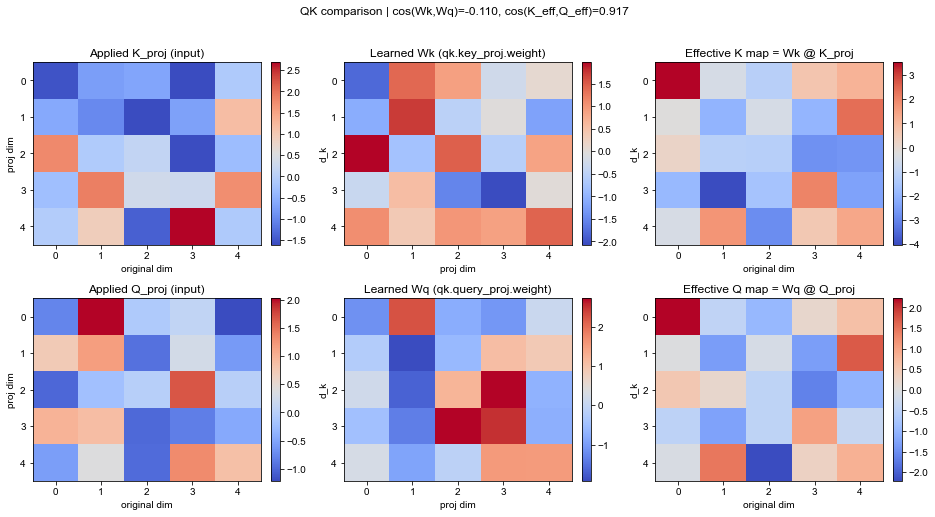

In [ ]:
# Visualize learned Q/K (qk model) vs applied input projections (Q_proj/K_proj)
# Works for one run directory containing: results.pkl and model_qk.pt

import os
import pickle
import numpy as np
import torch
import matplotlib.pyplot as plt

from models.qk_icl import QKICL

# ----------------------------
# Pick one run
# ----------------------------
#run_dir = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/input_proj_dim_seed_qkmlp/6_1/"
run_dir = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/input_proj_dim_D_seed_qkm_ent/5_5_1/"
results_path = os.path.join(run_dir, "results.pkl")
qk_model_path = os.path.join(run_dir, "model_qk.pt")

with open(results_path, "rb") as f:
    data = pickle.load(f)

params = data["params"]
K_proj = data["K_proj"]   # context projection used in data generation
Q_proj = data["Q_proj"]   # query projection used in data generation

# Ensure tensors
if not torch.is_tensor(K_proj):
    K_proj = torch.tensor(K_proj, dtype=torch.float32)
if not torch.is_tensor(Q_proj):
    Q_proj = torch.tensor(Q_proj, dtype=torch.float32)

# ----------------------------
# Recreate qk model and load learned weights
# ----------------------------
qk = QKICL(
    z_dim=params["input_proj_dim"],
    L=params["L"],
    N=params["N"],
    d_k=params.get("qk_dim", params["input_proj_dim"]),
    print_creation=False,
)
state = torch.load(qk_model_path, map_location="cpu")
qk.load_state_dict(state)
qk.eval()

Wk = qk.key_proj.weight.detach().cpu()    # (d_k, z_dim)
Wq = qk.query_proj.weight.detach().cpu()  # (d_k, z_dim)

# ----------------------------
# Build "effective" maps from original feature space -> d_k
# This is usually the most meaningful comparison to applied projections.
# z_original --(K_proj/Q_proj)--> z_proj --(Wk/Wq)--> key/query space
# effective: Wk @ K_proj, Wq @ Q_proj
# ----------------------------
K_eff = Wk @ K_proj.cpu()   # (d_k, D_orig)
Q_eff = Wq @ Q_proj.cpu()   # (d_k, D_orig)

def cosine_similarity(A, B, eps=1e-8):
    a = A.reshape(-1).float()
    b = B.reshape(-1).float()
    return torch.dot(a, b) / (torch.norm(a) * torch.norm(b) + eps)

# similarity between learned K and Q projections in projected space
sim_learned = cosine_similarity(Wk, Wq).item()

# similarity between effective context/query maps in original space
sim_effective = cosine_similarity(K_eff, Q_eff).item()

print("Shapes:")
print(f"  K_proj: {tuple(K_proj.shape)} | Q_proj: {tuple(Q_proj.shape)}")
print(f"  Wk:     {tuple(Wk.shape)} | Wq:     {tuple(Wq.shape)}")
print(f"  K_eff:  {tuple(K_eff.shape)} | Q_eff: {tuple(Q_eff.shape)}")
print(f"Cosine(Wk, Wq): {sim_learned:.4f}")
print(f"Cosine(K_eff, Q_eff): {sim_effective:.4f}")

# ----------------------------
# Plot side-by-side
# ----------------------------
fig, axes = plt.subplots(2, 3, figsize=(13, 7))

im00 = axes[0, 0].imshow(K_proj.cpu().numpy(), aspect="auto", cmap="coolwarm")
axes[0, 0].set_title("Applied K_proj (input)")
axes[0, 0].set_xlabel("original dim")
axes[0, 0].set_ylabel("proj dim")
plt.colorbar(im00, ax=axes[0, 0], fraction=0.046, pad=0.04)

im01 = axes[0, 1].imshow(Wk.numpy(), aspect="auto", cmap="coolwarm")
axes[0, 1].set_title("Learned Wk (qk.key_proj.weight)")
axes[0, 1].set_xlabel("proj dim")
axes[0, 1].set_ylabel("d_k")
plt.colorbar(im01, ax=axes[0, 1], fraction=0.046, pad=0.04)

im02 = axes[0, 2].imshow(K_eff.numpy(), aspect="auto", cmap="coolwarm")
axes[0, 2].set_title("Effective K map = Wk @ K_proj")
axes[0, 2].set_xlabel("original dim")
axes[0, 2].set_ylabel("d_k")
plt.colorbar(im02, ax=axes[0, 2], fraction=0.046, pad=0.04)

im10 = axes[1, 0].imshow(Q_proj.cpu().numpy(), aspect="auto", cmap="coolwarm")
axes[1, 0].set_title("Applied Q_proj (input)")
axes[1, 0].set_xlabel("original dim")
axes[1, 0].set_ylabel("proj dim")
plt.colorbar(im10, ax=axes[1, 0], fraction=0.046, pad=0.04)

im11 = axes[1, 1].imshow(Wq.numpy(), aspect="auto", cmap="coolwarm")
axes[1, 1].set_title("Learned Wq (qk.query_proj.weight)")
axes[1, 1].set_xlabel("proj dim")
axes[1, 1].set_ylabel("d_k")
plt.colorbar(im11, ax=axes[1, 1], fraction=0.046, pad=0.04)

im12 = axes[1, 2].imshow(Q_eff.numpy(), aspect="auto", cmap="coolwarm")
axes[1, 2].set_title("Effective Q map = Wq @ Q_proj")
axes[1, 2].set_xlabel("original dim")
axes[1, 2].set_ylabel("d_k")
plt.colorbar(im12, ax=axes[1, 2], fraction=0.046, pad=0.04)

plt.suptitle(
    f"QK comparison | cos(Wk,Wq)={sim_learned:.3f}, cos(K_eff,Q_eff)={sim_effective:.3f}",
    y=1.02
)
plt.tight_layout()
plt.show()

M shape: (5, 5)


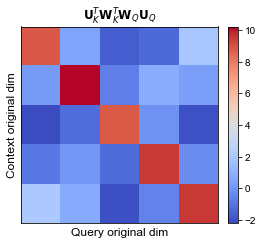

In [154]:
# Compose the original-space bilinear form:
# M = K_proj^T Wk^T Wq Q_proj
# This gives the query-context similarity operator in the *original* feature space.
# Ensure CPU tensors
Kp = K_proj.detach().cpu() if torch.is_tensor(K_proj) else torch.tensor(K_proj, dtype=torch.float32)
Qp = Q_proj.detach().cpu() if torch.is_tensor(Q_proj) else torch.tensor(Q_proj, dtype=torch.float32)
Wk_ = Wk.detach().cpu()
Wq_ = Wq.detach().cpu()
M = Kp.T @ Wk_.T @ Wq_ @ Qp   # shape: (D_original, D_original)
print("M shape:", tuple(M.shape))
fig, ax = plt.subplots(figsize=(4.2, 3.5))
im = ax.imshow(M.numpy(), cmap="coolwarm", aspect="equal")
#ax.set_title(r"$K_{\mathrm{proj}}^T W_k^T W_q Q_{\mathrm{proj}}$")
fs = 12
ax.set_title(r"$\mathbf{U}_K^T \mathbf{W}_K^T \mathbf{W}_Q \mathbf{U}_Q$", fontsize=fs)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("Query original dim", fontsize=fs)
ax.set_ylabel("Context original dim", fontsize=fs)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()

#fig.savefig(save_path + f"InvertedQK_poor.png", dpi=300, bbox_inches="tight")

plt.show()

# Copy / no copy

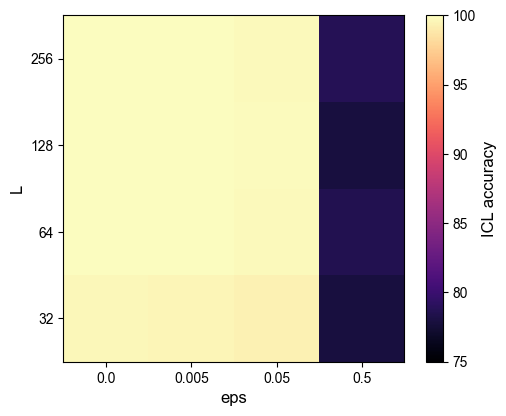

In [20]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

param1_values = [32, 64, 128, 256]
param2_values = [0.0, 0.005, 0.05, 0.5]
param3_values = [1,2,3,4,5]
# param1_values = np.arange(4,6,1)
# param2_values = np.arange(5,16,1)
#len(np.arange(5,16,1)) * len(np.arange(4,6,1))
path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/L_eps_seed_nocopy/"


results_grid = np.zeros((len(param1_values), len(param2_values), len(param3_values)))
for i, param1 in enumerate(param1_values):
    for j, param2 in enumerate(param2_values):
        for k, param3 in enumerate(param3_values):
            path = path_base + str(param1) + "_" + str(param2) + "_" + str(param3) + "/"
            results_path = path + "results.pkl"
            #try:
            with open(results_path, "rb") as file:
                data = pickle.load(file)
            results = data['results']['markov']
            history = data['history']['markov']
            icl_acc = [val for val in history['icl_acc'] if val is not None]
            #icl_acc = [val for val in history['train_acc'] if val is not None]
            # print(np.max(icl_acc))
            #results_grid[i, j] = icl_acc[-1]
            results_grid[i, j, k] = np.max(icl_acc)
            # except:
            #     pass



# plot
fig, ax = plt.subplots(figsize=(5.5, 4.5))
fs = 12

results_grid_avg = np.mean(results_grid, axis = 2)
im = ax.imshow(results_grid_avg, cmap='magma', aspect='auto', origin='lower', vmin = 75, vmax = 100)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("ICL accuracy", size = fs)
ax.set_xlabel('eps', fontsize=fs)
ax.set_ylabel('L', fontsize=fs)
# ax.set_xlabel('D')
# ax.set_ylabel('K')
ax.set_xticks(range(len(param2_values)), param2_values)
ax.set_yticks(range(len(param1_values)), param1_values)
#ax.set_title('ICL accuracy', fontsize=fs)


plt.show()

#save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.savefig(save_path + 'ICLAccuracy.png', dpi=300, bbox_inches='tight')

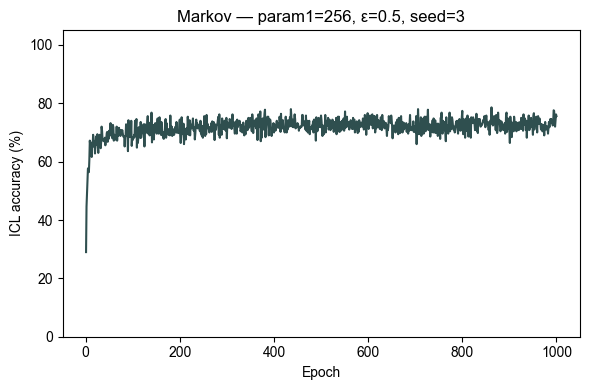

In [10]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

path_base = r"C:\Users\csfloyd\Dropbox\Projects\MarkovComputation\DirsICL\L_eps_seed_nocopy"  # no trailing slash ok
param1, param2, param3 = 256, 0.5, 3  # ε and seed: edit as needed

results_path = f"{path_base.rstrip('/')}/{param1}_{param2}_{param3}/results.pkl"
with open(results_path, "rb") as f:
    data = pickle.load(f)

icl = data["history"]["markov"]["icl_acc"]
epochs = np.arange(1, len(icl) + 1)
mask = np.array([v is not None for v in icl])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(epochs[mask], np.array(icl, dtype=object)[mask].astype(float), color="darkslategray", lw=1.5)
ax.set_xlabel("Epoch")
ax.set_ylabel("ICL accuracy (%)")
ax.set_title(f"Markov — param1={param1}, ε={param2}, seed={param3}")
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

<ipython-input-45-a16f8091ba8e>:81: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "--d" (-> linestyle='--'). The keyword argument will take precedence.
  ax.errorbar(param1_values, results_grid_mean_nocopy_mlp, yerr=results_grid_sem_nocopy_mlp, fmt='--d', capsize=3, lw=2, color='darkorange', label='MLP — No Copy', linestyle='--')
<ipython-input-45-a16f8091ba8e>:83: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "--^" (-> linestyle='--'). The keyword argument will take precedence.
  ax.errorbar(param1_values, results_grid_mean_copy_mlp, yerr=results_grid_sem_copy_mlp, fmt='--^', capsize=3, lw=2, color='orangered', label='MLP — Copy', linestyle='--')
<ipython-input-45-a16f8091ba8e>:85: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "--v" (-> linestyle='--'). The keyword argument will take precedence.
  ax.errorbar(param1_values

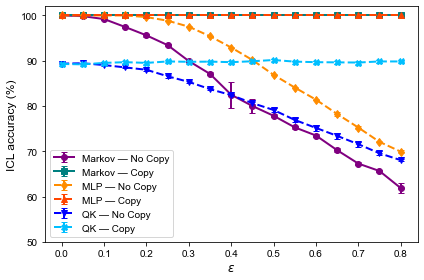

In [45]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

param1_values = np.round(np.arange(0, 0.85, 0.05), 2)
param2_values = [1, 2, 3, 4, 5]

path_base_nocopy = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/eps_seed_nocopy/"
path_base_copy = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/eps_seed_copy/"


# Function to aggregate results for a given path_base and model label
def aggregate_results(path_base, param1_values, param2_values, model_key='markov'):
    results_grid = np.zeros((len(param1_values), len(param2_values)))
    for i, param1 in enumerate(param1_values):
        for j, param2 in enumerate(param2_values):
            path = f"{path_base}{param1}_{param2}/"
            results_path = f"{path}results.pkl"
            try:
                with open(results_path, "rb") as file:
                    data = pickle.load(file)
                history = data['history'][model_key]
                icl_acc = [val for val in history['icl_acc'] if val is not None]
                results_grid[i, j] = np.max(icl_acc) if len(icl_acc) > 0 else np.nan
            except Exception as e:
                results_grid[i, j] = np.nan
    return results_grid

# Plot results at the top

# --- Aggregation ---
results_grid_nocopy_markov = aggregate_results(path_base_nocopy, param1_values, param2_values, model_key='markov')
results_grid_copy_markov  = aggregate_results(path_base_copy, param1_values, param2_values, model_key='markov')
results_grid_nocopy_mlp = aggregate_results(path_base_nocopy, param1_values, param2_values, model_key='mlp')
results_grid_copy_mlp = aggregate_results(path_base_copy, param1_values, param2_values, model_key='mlp')
results_grid_nocopy_qk = aggregate_results(path_base_nocopy, param1_values, param2_values, model_key='qk')
results_grid_copy_qk = aggregate_results(path_base_copy, param1_values, param2_values, model_key='qk')

# --- Plotting at the top ---
fig, ax = plt.subplots(figsize=(6, 4))
fs = 12

results_grid_mean_nocopy_markov = np.nanmean(results_grid_nocopy_markov, axis=1)
results_grid_sem_nocopy_markov = np.nanstd(results_grid_nocopy_markov, axis=1, ddof=1) / np.sqrt(np.sum(~np.isnan(results_grid_nocopy_markov), axis=1))

results_grid_mean_copy_markov = np.nanmean(results_grid_copy_markov, axis=1)
results_grid_sem_copy_markov = np.nanstd(results_grid_copy_markov, axis=1, ddof=1) / np.sqrt(np.sum(~np.isnan(results_grid_copy_markov), axis=1))

results_grid_mean_nocopy_mlp = np.nanmean(results_grid_nocopy_mlp, axis=1)
results_grid_sem_nocopy_mlp = np.nanstd(results_grid_nocopy_mlp, axis=1, ddof=1) / np.sqrt(np.sum(~np.isnan(results_grid_nocopy_mlp), axis=1))

results_grid_mean_copy_mlp = np.nanmean(results_grid_copy_mlp, axis=1)
results_grid_sem_copy_mlp = np.nanstd(results_grid_copy_mlp, axis=1, ddof=1) / np.sqrt(np.sum(~np.isnan(results_grid_copy_mlp), axis=1))

results_grid_mean_nocopy_qk = np.nanmean(results_grid_nocopy_qk, axis=1)
results_grid_sem_nocopy_qk = np.nanstd(results_grid_nocopy_qk, axis=1, ddof=1) / np.sqrt(np.sum(~np.isnan(results_grid_nocopy_qk), axis=1))

results_grid_mean_copy_qk = np.nanmean(results_grid_copy_qk, axis=1)
results_grid_sem_copy_qk = np.nanstd(results_grid_copy_qk, axis=1, ddof=1) / np.sqrt(np.sum(~np.isnan(results_grid_copy_qk), axis=1))

# Plot Markov model (No Copy)
ax.errorbar(param1_values, results_grid_mean_nocopy_markov, yerr=results_grid_sem_nocopy_markov, fmt='-o', capsize=3, lw=2, color='purple', label='Markov — No Copy')
# Plot Markov model (Copy)
ax.errorbar(param1_values, results_grid_mean_copy_markov, yerr=results_grid_sem_copy_markov, fmt='-s', capsize=3, lw=2, color='teal', label='Markov — Copy')
# Plot MLP No Copy
ax.errorbar(param1_values, results_grid_mean_nocopy_mlp, yerr=results_grid_sem_nocopy_mlp, fmt='--d', capsize=3, lw=2, color='darkorange', label='MLP — No Copy', linestyle='--')
# Plot MLP Copy
ax.errorbar(param1_values, results_grid_mean_copy_mlp, yerr=results_grid_sem_copy_mlp, fmt='--^', capsize=3, lw=2, color='orangered', label='MLP — Copy', linestyle='--')
# Plot QK No Copy
ax.errorbar(param1_values, results_grid_mean_nocopy_qk, yerr=results_grid_sem_nocopy_qk, fmt='--v', capsize=3, lw=2, color='blue', label='QK — No Copy', linestyle='--')
# Plot QK Copy
ax.errorbar(param1_values, results_grid_mean_copy_qk, yerr=results_grid_sem_copy_qk, fmt='--X', capsize=3, lw=2, color='deepskyblue', label='QK — Copy', linestyle='--')

ax.set_xlabel(r'$\epsilon$', fontsize=fs)
ax.set_ylabel('ICL accuracy (%)', fontsize=fs)
ax.set_xticks(param1_values[0::2])
ax.set_ylim(50, 102)
#ax.set_title('ICL accuracy vs. eps', fontsize=fs)
ax.legend(fontsize=fs-2)

plt.tight_layout()
plt.show()
#save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.savefig(save_path + 'ICLAccuracy_vs_eps_errorbar.png', dpi=300, bbox_inches='tight')

{'B': 1,
 'D': 5,
 'K': 128,
 'L': 128,
 'N': 4,
 'add_mlp': True,
 'add_qk': True,
 'base_mask_value': -inf,
 'batch_size': 50,
 'context_scorer_type': 'linear',
 'epochs': 1000,
 'epsilon': 0.001,
 'equal_norm': False,
 'exact_copy': True,
 'input_proj_dim': 5,
 'input_proj_mode': 'random',
 'input_proj_scale': 1,
 'learn_base_rates': True,
 'lr': 0.0025,
 'method': 'direct_solve',
 'min_max_choice': None,
 'mlp_baseline_activation': 'relu',
 'mlp_baseline_depth': 2,
 'mlp_baseline_dropout': 0.0,
 'mlp_baseline_width': 32,
 'mlp_depth': 2,
 'mlp_width': 32,
 'n_nodes': 5,
 'offset': 0.0,
 'qk_dim': 5,
 'seed': 1,
 'shuffle_context': True,
 'sparsity_rho_all': 1.0,
 'sparsity_rho_edge': 1.0,
 'sparsity_rho_edge_base_W': 1.0,
 'temperature': 1.0,
 'train_samples': 25000,
 'transform_func': 'exp',
 'unique_labels': False,
 'val_samples': 5000}


<ipython-input-156-0adbc95cfdb4>:81: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.



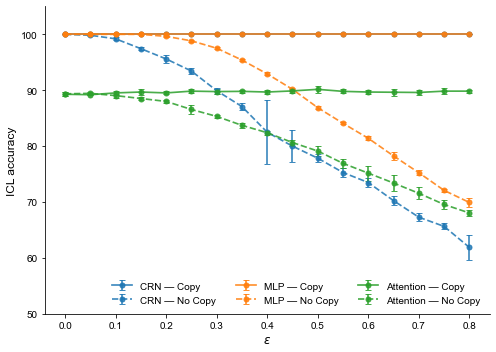

In [156]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np
import matplotlib.cm as cm
import matplotlib.colors as mcolors

param1_values = np.round(np.arange(0, 0.85, 0.05), 2)
param2_values = [1, 2, 3, 4, 5]

path_base_nocopy = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/eps_seed_nocopy/"
path_base_copy = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/eps_seed_copy/"


# Function to aggregate results for a given path_base and model label
def aggregate_results(path_base, param1_values, param2_values, model_key='markov'):
    results_grid = np.zeros((len(param1_values), len(param2_values)))
    for i, param1 in enumerate(param1_values):
        for j, param2 in enumerate(param2_values):
            path = f"{path_base}{param1}_{param2}/"
            results_path = f"{path}results.pkl"
            try:
                with open(results_path, "rb") as file:
                    data = pickle.load(file)
                history = data['history'][model_key]
                icl_acc = [val for val in history['icl_acc'] if val is not None]
                results_grid[i, j] = np.max(icl_acc) if len(icl_acc) > 0 else np.nan
            except Exception as e:
                results_grid[i, j] = np.nan
    return results_grid

import pprint
pprint.pprint(data['params'])

# --- Aggregation ---
results_grid_nocopy_markov = aggregate_results(path_base_nocopy, param1_values, param2_values, model_key='markov')
results_grid_copy_markov = aggregate_results(path_base_copy, param1_values, param2_values, model_key='markov')
results_grid_nocopy_mlp = aggregate_results(path_base_nocopy, param1_values, param2_values, model_key='mlp')
results_grid_copy_mlp = aggregate_results(path_base_copy, param1_values, param2_values, model_key='mlp')
results_grid_nocopy_qk = aggregate_results(path_base_nocopy, param1_values, param2_values, model_key='qk')
results_grid_copy_qk = aggregate_results(path_base_copy, param1_values, param2_values, model_key='qk')

# Calculate means and standard errors
results_grid_mean_nocopy_markov = np.nanmean(results_grid_nocopy_markov, axis=1)
results_grid_std_nocopy_markov = np.nanstd(results_grid_nocopy_markov, axis=1)

results_grid_mean_copy_markov = np.nanmean(results_grid_copy_markov, axis=1)
results_grid_std_copy_markov = np.nanstd(results_grid_copy_markov, axis=1)

results_grid_mean_nocopy_mlp = np.nanmean(results_grid_nocopy_mlp, axis=1)
results_grid_std_nocopy_mlp = np.nanstd(results_grid_nocopy_mlp, axis=1)

results_grid_mean_copy_mlp = np.nanmean(results_grid_copy_mlp, axis=1)
results_grid_std_copy_mlp = np.nanstd(results_grid_copy_mlp, axis=1)

results_grid_mean_nocopy_qk = np.nanmean(results_grid_nocopy_qk, axis=1)
results_grid_std_nocopy_qk = np.nanstd(results_grid_nocopy_qk, axis=1)

results_grid_mean_copy_qk = np.nanmean(results_grid_copy_qk, axis=1)
results_grid_std_copy_qk = np.nanstd(results_grid_copy_qk, axis=1)

# --- Plotting ---
fs = 12
fig, ax = plt.subplots(figsize=(7, 5))

# Get colormap
model_cmap = cm.get_cmap('tab10')

# Plot CRN (Markov)
ax.errorbar(param1_values, results_grid_mean_copy_markov, yerr=results_grid_std_copy_markov, 
            linestyle="-", linewidth=1.7, marker="o", markersize=5, capsize=3, 
            label='CRN — Copy', color=model_cmap(0), alpha=0.86)
ax.errorbar(param1_values, results_grid_mean_nocopy_markov, yerr=results_grid_std_nocopy_markov, 
            linestyle="--", linewidth=1.7, marker="o", markersize=5, capsize=3, 
            label='CRN — No Copy', color=model_cmap(0), alpha=0.86)


# Plot MLP
ax.errorbar(param1_values, results_grid_mean_copy_mlp, yerr=results_grid_std_copy_mlp, 
            linestyle="-", linewidth=1.7, marker="o", markersize=5, capsize=3, 
            label='MLP — Copy', color=model_cmap(1), alpha=0.86)
ax.errorbar(param1_values, results_grid_mean_nocopy_mlp, yerr=results_grid_std_nocopy_mlp, 
            linestyle="--", linewidth=1.7, marker="o", markersize=5, capsize=3, 
            label='MLP — No Copy', color=model_cmap(1), alpha=0.86)


# Plot Attention (QK)
ax.errorbar(param1_values, results_grid_mean_copy_qk, yerr=results_grid_std_copy_qk, 
            linestyle="-", linewidth=1.7, marker="o", markersize=5, capsize=3, 
            label='Attention — Copy', color=model_cmap(2), alpha=0.86)
ax.errorbar(param1_values, results_grid_mean_nocopy_qk, yerr=results_grid_std_nocopy_qk, 
            linestyle="--", linewidth=1.7, marker="o", markersize=5, capsize=3, 
            label='Attention — No Copy', color=model_cmap(2), alpha=0.86)


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlabel(r'$\epsilon$', fontsize=fs)
ax.set_ylabel('ICL accuracy', fontsize=fs)
ax.set_xticks(param1_values[0::2])
ax.set_ylim(50, 105)
#ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=fs-2, frameon=False, loc="lower right", ncol=3)

plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.savefig(save_path + 'SI_CopyNoCopy.png', dpi=300, bbox_inches='tight')

In [ ]:


# Example usage:
# path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/eps_seed_copy/0.1_1/"
# print_params_from_results(path)

# MLP Encoding/Decoding

{'B': 1,
 'D': 4,
 'K': 128,
 'L': 128,
 'N': 8,
 'add_mlp': False,
 'add_qk': False,
 'base_mask_value': -inf,
 'batch_size': 50,
 'decoder_mlp_depth': 2,
 'decoder_mlp_width': 32,
 'encoder_mlp_depth': 2,
 'encoder_mlp_width': 32,
 'epochs': 1000,
 'epsilon': 0.001,
 'equal_norm': False,
 'exact_copy': True,
 'input_proj_dim': 4,
 'input_proj_mode': 'identity',
 'input_proj_scale': 1,
 'learn_base_rates': True,
 'lr': 0.0025,
 'method': 'direct_solve',
 'min_max_choice': None,
 'mlp_baseline_activation': 'relu',
 'mlp_baseline_depth': 2,
 'mlp_baseline_dropout': 0.0,
 'mlp_baseline_width': 32,
 'n_nodes': 8,
 'offset': 0.0,
 'qk_dim': 4,
 'rate_decoder_type': 'linear',
 'rate_encoder_type': 'linear',
 'seed': 1,
 'shuffle_context': True,
 'sparsity_rho_all': 1.0,
 'sparsity_rho_edge': 1.0,
 'sparsity_rho_edge_base_W': 1.0,
 'temperature': 1.0,
 'train_samples': 25000,
 'transform_func': 'exp',
 'unique_labels': False,
 'val_samples': 5000}
{   'K': 128,
    'L': 128,
    'D': 4,
    

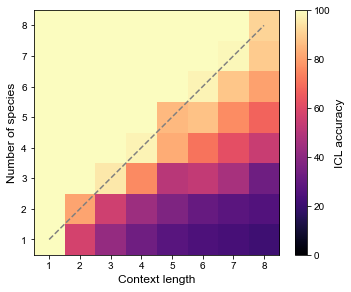

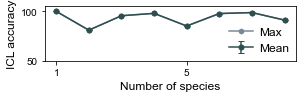

In [5]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

def print_params_from_results(path):
    """
    Load the results.pkl from the given path and pretty print its 'params' dict.
    
    Parameters:
    - path (str): The directory containing 'results.pkl'
    """
    import pickle
    from pprint import pprint

    results_path = f"{path}results.pkl"
    with open(results_path, "rb") as file:
        data = pickle.load(file)
    params = data['params']
    pprint(params, sort_dicts=False, indent=4, width=80)

param1_values = np.arange(1,9,1)
param2_values = np.arange(1,9,1)
param3_values = [1]
# param1_values = np.arange(4,6,1)
# param2_values = np.arange(5,16,1)
#len(np.arange(5,16,1)) * len(np.arange(4,6,1))
path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed_linear-mlp_2/"
path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed_linear-linear_2/"

results_grid = np.zeros((len(param1_values), len(param2_values), len(param3_values)))
for i, param1 in enumerate(param1_values):
    for j, param2 in enumerate(param2_values):
        for k, param3 in enumerate(param3_values):
            path = path_base + str(param1) + "_" + str(param2) + "_" + str(param3) + "/"
            results_path = path + "results.pkl"
            try:
                with open(results_path, "rb") as file:
                    data = pickle.load(file)
                results = data['results']['markov']
                history = data['history']['markov']
                #icl_acc = [val for val in history['icl_acc'] if val is not None]
                icl_acc = [val for val in history['icl_acc'] if val is not None]
                #results_grid[i, j] = icl_acc[-1]
                results_grid[i, j, k] = np.max(icl_acc)
            except:
                pass

import pprint
pprint.pprint(data['params'])

print_params_from_results(path_base + "3_4_1/")
# plot
fig, ax = plt.subplots(figsize=(5.5, 4.5))
fs = 12

results_grid_avg = np.mean(results_grid, axis = 2)
im = ax.imshow(results_grid_avg, cmap='magma', aspect='auto', origin='lower', vmin = 0, vmax = 100)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("ICL accuracy", size = fs)
ax.set_xlabel('Context length', fontsize=fs)
ax.set_ylabel('Number of species', fontsize=fs)
# ax.set_xlabel('D')
# ax.set_ylabel('K')
ax.set_xticks(range(len(param2_values)), param2_values)
ax.set_yticks(range(len(param1_values)), param1_values)
#ax.set_title('ICL accuracy', fontsize=fs)

# Add diagonal line from bottom-left to top-right
ax.plot([0, len(param1_values)-1], [0, len(param2_values)-1], 
        color='gray', linestyle='--', linewidth=1.5)

# # Add text annotations for each cell
# for i in range(len(param1_values)):
#     for j in range(len(param2_values)):
#         text = ax.text(i, j, f'{results_grid[j, i]:.1f}',
#                        ha="center", va="center", color="gray", fontsize=10)

# plot
fig, ax = plt.subplots(figsize=(4.5, 1))
fs = 12
diag = np.array([np.mean(results_grid[i,i,:]) for i in range(len(param1_values))])
diag_max = np.array([np.max(results_grid[i,i,:]) for i in range(len(param1_values))])
diag_std = np.array([np.std(results_grid[i,i,:]) for i in range(len(param1_values))])



# Add diagonal line with error bars
x_positions = range(len(param1_values))
ax.errorbar(x_positions, diag, yerr=diag_std, 
            color='darkslategray', linestyle='-', linewidth=1.5, 
            marker='o', markersize=5, capsize=3, label = 'Mean')
ax.plot(x_positions, diag_max,
        color='lightslategray', linestyle='-', linewidth=1.5, 
        marker='h', markersize=5, zorder = -10, label = 'Max')
ax.set_ylim(50, 105)
ax.set_xlabel('Number of species', fontsize=fs)
ax.set_ylabel('ICL accuracy', fontsize=fs)
ax.set_xticks([i for i in range(len(param1_values)) if (param1_values[i] % 5 == 0) or (param1_values[i] == 1)])
ax.set_xticklabels([param1_values[i] for i in range(len(param1_values)) if (param1_values[i] % 5 == 0) or (param1_values[i] == 1)])
ax.legend(fontsize=fs, frameon=False, loc='lower right', ncol=1, handletextpad=0.5, borderaxespad=0.2)

# plt.show()

# save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
# fig.savefig(save_path + 'ICLAccuracyDiag.png', dpi=300, bbox_inches='tight')

plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.savefig(save_path + 'ICLAccuracy.png', dpi=300, bbox_inches='tight')

{   'K': 128,
    'L': 128,
    'D': 4,
    'N': 4,
    'B': 1,
    'epsilon': 0.001,
    'seed': 1,
    'exact_copy': True,
    'shuffle_context': True,
    'offset': 0.0,
    'min_max_choice': None,
    'unique_labels': False,
    'equal_norm': False,
    'n_nodes': 3,
    'add_qk': False,
    'add_mlp': False,
    'transform_func': 'exp',
    'learn_base_rates': True,
    'rate_encoder_type': 'linear',
    'encoder_mlp_depth': 2,
    'encoder_mlp_width': 32,
    'rate_decoder_type': 'linear',
    'decoder_mlp_depth': 2,
    'decoder_mlp_width': 32,
    'qk_dim': 4,
    'mlp_baseline_depth': 2,
    'mlp_baseline_width': 32,
    'mlp_baseline_dropout': 0.0,
    'mlp_baseline_activation': 'relu',
    'sparsity_rho_edge': 1.0,
    'sparsity_rho_all': 1.0,
    'sparsity_rho_edge_base_W': 1.0,
    'base_mask_value': -inf,
    'epochs': 1000,
    'lr': 0.0025,
    'batch_size': 50,
    'train_samples': 25000,
    'val_samples': 5000,
    'method': 'direct_solve',
    'temperature': 1.0,
  

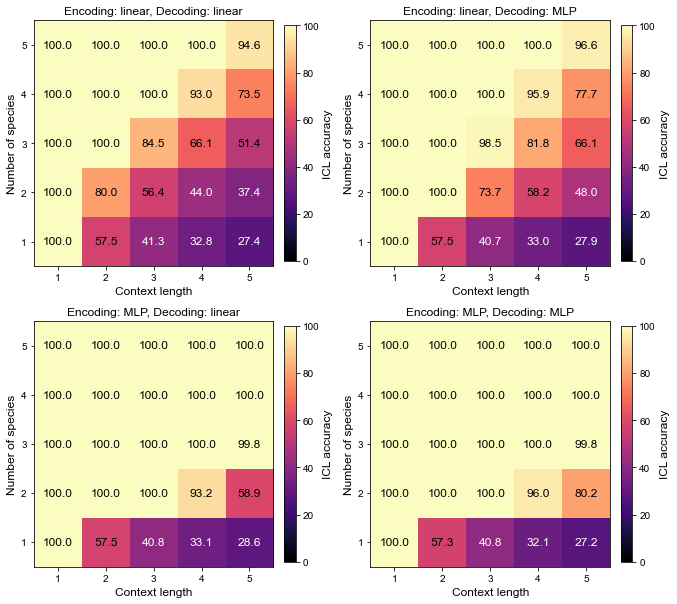

In [ ]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

def print_params_from_results(path):
    """
    Load the results.pkl from the given path and pretty print its 'params' dict.
    
    Parameters:
    - path (str): The directory containing 'results.pkl'
    """
    import pickle
    from pprint import pprint

    results_path = f"{path}results.pkl"
    with open(results_path, "rb") as file:
        data = pickle.load(file)
    params = data['params']
    pprint(params, sort_dicts=False, indent=4, width=80)

# Define path_bases and labels (order can be changed if desired)
path_bases = [
    ("/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed_linear-linear_2/", "linear-linear"),
    ("/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed_linear-mlp_2/", "linear-mlp"),
    ("/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed_mlp-linear_2/", "mlp-linear"),
    ("/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed_mlp-mlp_2/", "mlp-mlp"),
]

param1_values = np.arange(1,6,1)
param2_values = np.arange(1,6,1)
param3_values = [1,2,3,4,5]

results_grids = []

# Load all result grids
for path_base, _ in path_bases:
    results_grid = np.zeros((len(param1_values), len(param2_values), len(param3_values)))
    for i, param1 in enumerate(param1_values):
        for j, param2 in enumerate(param2_values):
            for k, param3 in enumerate(param3_values):
                path = path_base + str(param1) + "_" + str(param2) + "_" + str(param3) + "/"
                results_path = path + "results.pkl"
                try:
                    with open(results_path, "rb") as file:
                        data = pickle.load(file)
                    results = data['results']['markov']
                    history = data['history']['markov']
                    icl_acc = [val for val in history['icl_acc'] if val is not None]
                    results_grid[i, j, k] = np.max(icl_acc)
                except Exception as e:
                    pass
    results_grids.append(results_grid)

labels = ["Encoding: linear, Decoding: linear", "Encoding: linear, Decoding: MLP", "Encoding: MLP, Decoding: linear", "Encoding: MLP, Decoding: MLP"]
# Print an example params for reproducibility
print_params_from_results(path_bases[0][0] + "3_4_1/")

# Plot 2x2 panel of heatmaps
fs = 12
fig, axs = plt.subplots(2, 2, figsize=(9.5, 8.5))
vmin, vmax = 0, 100

for idx, ((_, label), grid) in enumerate(zip(path_bases, results_grids)):
    ax = axs[idx // 2, idx % 2]
    avg_grid = np.mean(grid, axis=2)
    im = ax.imshow(
        avg_grid,
        cmap='magma',
        aspect='auto',
        origin='lower',
        vmin=vmin,
        vmax=vmax
    )
    ax.set_facecolor('white')
    ax.set_xlabel('Context length', fontsize=fs)
    ax.set_ylabel('Number of species', fontsize=fs)
    ax.set_xticks(range(len(param2_values)))
    ax.set_xticklabels(param2_values)
    ax.set_yticks(range(len(param1_values)))
    ax.set_yticklabels(param1_values)
    ax.set_title(labels[idx], fontsize=fs)

    # Add an individual colorbar for each panel
    cbar = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.04)
    cbar.set_label("ICL accuracy", size=fs)

    # Adapted number plotting: 
    # Now numbers are plotted in each heatmap separately, with color and rounding depending on value.
    for (i, j), val in np.ndenumerate(avg_grid):
        if np.isnan(val):
            display_text = ""
            txt_color = "black"
        else:
            if val >= 50:
                display_text = f"{val:.1f}"
                txt_color = "black"
            else:
                display_text = f"{val:.1f}"
                txt_color = "white"
        ax.text(
            j, i, display_text,
            ha="center", va="center",
            color=txt_color,
            fontsize=fs-2 if val < 10 else fs
        )

# Set figure background to white
fig.patch.set_facecolor('white')

plt.tight_layout()
plt.show()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
# fig.savefig(save_path + 'SI_EncodingDecoding.png', dpi=300, bbox_inches='tight')

  Initialized ICL Attention model (L=128 classes, attention over 4 context items)
  Label modulation: False
  Base rates learnable: True
  Rate encoder: mlp
  Encoder MLP: depth=2, width=32, activation=relu
  Rate decoder: linear
  Base mask value: -inf
  Sparsity K: rho_edge=1.000, rho_all=1.000
  Sparsity base_W: rho_edge=1.000
  K_params sparsity: 0.000 (9/9 active)
  base_W sparsity: 0.000 (9/9 active)
  Parameters: 990


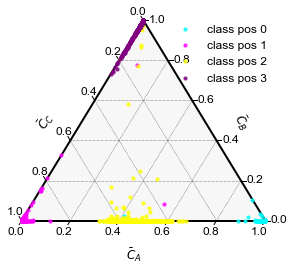

In [15]:
import pickle
import random

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import ternary
from torch.utils.data import DataLoader

from data_generation import (
    GaussianMixtureModel,
    generate_icl_gmm_data,
    build_input_projection_matrices,
)
from datasets import ICLGMMDataset, collate_fn
from models.markov_icl import load_model

plt.rcParams["font.family"] = "Arial"

path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/n_nodes_N_seed_mlp-linear/3_4_1/"
if not path.endswith("/"):
    path += "/"

random.seed(0)

with open(path + "results.pkl", "rb") as f:
    data = pickle.load(f)

params = data["params"]

# Match training: seed, then projections, then Markov model from params (encoder/decoder, z_dim).
torch.manual_seed(params["seed"])
np.random.seed(params["seed"])
K_proj, Q_proj = build_input_projection_matrices(
    D=params["D"],
    proj_dim=params.get("input_proj_dim", params["D"]),
    mode=params.get("input_proj_mode", "identity"),
    scale=params.get("input_proj_scale", 1.0),
)

model = load_model(params, path, print_creation=True)
model.eval()
device = next(model.parameters()).device

gmm = GaussianMixtureModel(
    K=params["K"],
    D=params["D"],
    L=params["L"],
    epsilon=params["epsilon"],
    seed=params["seed"],
    offset=params["offset"],
    equal_norm=params.get("equal_norm", False),
)

train_data = generate_icl_gmm_data(
    gmm,
    params["train_samples"],
    params["N"],
    novel_classes=False,
    exact_copy=params["exact_copy"],
    B=params["B"],
    L=params["L"],
    shuffle_context=params["shuffle_context"],
    min_max_choice=params["min_max_choice"],
    unique_labels=params["unique_labels"],
    K_proj=K_proj,
    Q_proj=Q_proj,
)

train_loader = DataLoader(
    ICLGMMDataset(train_data),
    batch_size=params["batch_size"],
    shuffle=True,
    collate_fn=collate_fn,
)

n_nodes = params["n_nodes"]
if n_nodes != 3:
    raise ValueError(f"This ternary plot expects n_nodes=3, got n_nodes={n_nodes}")

n_samples = 1250
n_samples_2 = 750
indices = list(range(n_samples)) + list(range(n_samples + 50, n_samples + 50 + n_samples_2))

p_steady_list = []
class_list = []

with torch.no_grad():
    for i in indices:
        z_seq, labels, targets = train_loader.dataset[i]
        z_seq = z_seq.unsqueeze(0).to(device)
        labels = labels.unsqueeze(0).to(device)
        targets = targets.unsqueeze(0).to(device).long()

        matching = (labels[0] == targets[0]).nonzero(as_tuple=True)[0]
        class_idx = matching[0].item() if matching.numel() > 0 else -1
        class_list.append(class_idx)

        z_flat = z_seq.reshape(1, -1)
        W_mat = model.compute_rate_matrix_W(
            z_flat, labels if model.use_label_mod else None
        )
        p_steady = model.direct_solve_steady_state(W_mat)
        p_steady_list.append(p_steady.cpu())

p_steady_all = torch.cat(p_steady_list, dim=0)
class_array = np.array(class_list)

scale = 1
fs = 12
offset = 0.15

fig, ax = plt.subplots(figsize=0.6 * np.array([7, 6]))
tax = ternary.TernaryAxesSubplot(scale=scale, ax=ax)
tax.boundary(linewidth=2.0)
tax.gridlines(multiple=0.2, color="black")

ternary_points = (p_steady_all.numpy() * scale).tolist()
unique_classes = np.unique(class_array)
colors = ["cyan", "magenta", "yellow", "purple", "orange", "brown", "pink", "gray"]

labeled = set()
for idx, c in enumerate(unique_classes):
    mask = class_array == c
    for j in np.where(mask)[0]:
        point = ternary_points[j]
        color = colors[idx % len(colors)]
        label = f"class pos {int(c)}" if int(c) not in labeled else ""
        if int(c) not in labeled:
            labeled.add(int(c))
        tax.scatter([point], marker="o", color=color, label=label, s=10, alpha=0.8, zorder=10)

tax.ticks(
    axis="lbr",
    multiple=0.2,
    linewidth=1,
    tick_formats="%.1f",
    offset=0.02,
    fontsize=fs,
)
tax.bottom_axis_label(r"$\bar{C}_A$", fontsize=fs, offset=offset)
tax.right_axis_label(r"$\bar{C}_B$", fontsize=fs, offset=offset)
tax.left_axis_label(r"$\bar{C}_C$", fontsize=fs, offset=offset)
tax.get_axes().axis("off")
ax = tax.get_axes()
handles, leg_labels = ax.get_legend_handles_labels()
by_label = dict(zip(leg_labels, handles))
ax.legend(by_label.values(), by_label.keys(), fontsize=fs, frameon=False, ncol=1, loc="upper right")

plt.tight_layout()
plt.show()

save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"
#fig.savefig(save_path + "TernaryPlot_mlp-linear_3_5_1.png", dpi=300, bbox_inches="tight")

In [16]:
import torch

if getattr(model, "B", None) is not None:
    B = model.B.detach().cpu()
    print("B shape:", tuple(B.shape))  # (n_nodes, N)
    print(B)
    # Optional: full numeric view
    torch.set_printoptions(linewidth=200, sci_mode=False, precision=4)
    print(B.numpy())
else:
    print("No B matrix: this checkpoint uses an MLP rate decoder (model.rate_decoder), not linear B.")

if model.rate_decoder is not None:
    for name, p in model.rate_decoder.named_parameters():
        print(name, p.shape, p.detach().cpu())

B shape: (3, 4)
tensor([[ 18.7823, -58.2884,   3.7231, -26.0400],
        [-14.6774, -14.2954, -10.9356,  13.6778],
        [-61.6233,  19.0827,   3.3023, -14.9817]])
[[ 18.782265  -58.28836     3.7230594 -26.039967 ]
 [-14.6773815 -14.295443  -10.935628   13.677764 ]
 [-61.623295   19.082684    3.3022578 -14.981741 ]]


# Regression plots

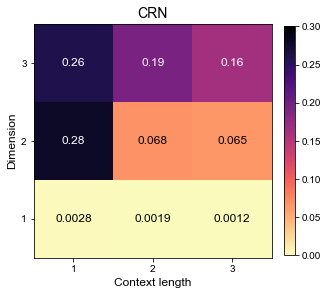

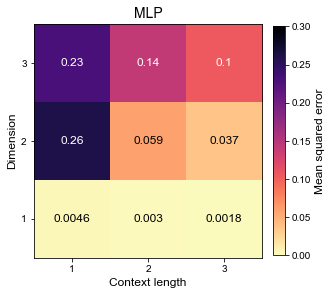

In [140]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Arial"

# --- sweep axes (edit to match your folder names param1_param2_param3/) ---
# param1: N (context length), param2: D (dimension), param3: seed
param1_values = [1, 2, 3]    # N (context length)
param2_values = [1, 2, 3]    # D (dimension)
param3_values = [1, 2, 3, 4, 5]  # seed

path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_reg_fin/"

# Regression history key: "val_mae" or "val_mse"
METRIC_KEY = "val_mse"

def _markov_history(data):
    h = data["history"]
    if isinstance(h, dict) and "markov" in h:
        return h["markov"]
    return h

def _mlp_history(data):
    h = data["history"]
    if isinstance(h, dict) and "mlp" in h:
        return h["mlp"]
    return h

def _metric_best_over_epochs(history_dict, key):
    """Scalar summary per run: best (min) validation error over training."""
    series = [v for v in history_dict.get(key, []) if v is not None]
    if not series:
        return np.nan
    return float(series[-1])

results_grid_markov = np.full(
    (len(param1_values), len(param2_values), len(param3_values)), np.nan, dtype=float
)
results_grid_mlp = np.full(
    (len(param1_values), len(param2_values), len(param3_values)), np.nan, dtype=float
)

for i, param1 in enumerate(param1_values):
    for j, param2 in enumerate(param2_values):
        for k, param3 in enumerate(param3_values):
            path = path_base + f"{param1}_{param2}_{param3}/"
            results_path = path + "results.pkl"
            try:
                with open(results_path, "rb") as f:
                    data = pickle.load(f)
                mh = _markov_history(data)
                ml = _mlp_history(data)
                results_grid_markov[i, j, k] = _metric_best_over_epochs(mh, METRIC_KEY)
                results_grid_mlp[i, j, k] = _metric_best_over_epochs(ml, METRIC_KEY)
            except Exception:
                pass

save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"
fs = 12

# --- Single heatmap for Markov ---
fig_markov, ax_markov = plt.subplots(figsize=(4.75, 4.2))
grid = results_grid_markov
results_grid_avg = np.nanmean(grid, axis=2)
# Force vmin to 0
vmin, vmax = 0.0,0.3
im = ax_markov.imshow(
    results_grid_avg.T,
    cmap="magma_r",
    aspect="auto",
    origin="lower",
    vmin=vmin,
    vmax=vmax,
)
# Show numbers on the grid
for (i, j), val in np.ndenumerate(results_grid_avg):
    label = f"{val:.2g}" if not np.isnan(val) else ""
    ax_markov.text(
        i, j, label,
        ha="center", va="center",
        color="white" if not np.isnan(val) and val > 0.1 else "black",
        fontsize=fs
    )
ax_markov.set_title("CRN", fontsize=fs+2)
ax_markov.set_xlabel("Context length", fontsize=fs)
ax_markov.set_ylabel("Dimension", fontsize=fs)
ax_markov.set_xticks(range(len(param2_values)), param2_values)
ax_markov.set_yticks(range(len(param1_values)), param1_values)
cbar = fig_markov.colorbar(im, ax=ax_markov, shrink=0.98, pad=0.04)
#cbar.set_label(f"Mean squared error", size=fs)

plt.tight_layout()
plt.show()
fig_markov.savefig(save_path + "RegHeatmaps_CRN.png", dpi=300, bbox_inches="tight")

# --- Single heatmap for MLP ---
fig_mlp, ax_mlp = plt.subplots(figsize=(4.75, 4.2))
grid = results_grid_mlp
results_grid_avg = np.nanmean(grid, axis=2)
# Force vmin to 0
vmin, vmax = 0.0, 0.3
im = ax_mlp.imshow(
    results_grid_avg.T,
    cmap="magma_r",
    aspect="auto",
    origin="lower",
    vmin=vmin,
    vmax=vmax,
)
# Show numbers on the grid
for (i, j), val in np.ndenumerate(results_grid_avg):
    label = f"{val:.2g}" if not np.isnan(val) else ""
    ax_mlp.text(
        i, j, label,
        ha="center", va="center",
        color="white" if not np.isnan(val) and val > 0.1 else "black",
        fontsize=fs
    )
ax_mlp.set_title("MLP", fontsize=fs+2)
ax_mlp.set_xlabel("Context length", fontsize=fs)
ax_mlp.set_ylabel("Dimension", fontsize=fs)
ax_mlp.set_xticks(range(len(param2_values)), param2_values)
ax_mlp.set_yticks(range(len(param1_values)), param1_values)
cbar = fig_mlp.colorbar(im, ax=ax_mlp, shrink=0.98, pad=0.04)
cbar.set_label(f"Mean squared error", size=fs)

plt.tight_layout()
plt.show()
fig_mlp.savefig(save_path + "RegHeatmaps_MLP.png", dpi=300, bbox_inches="tight")

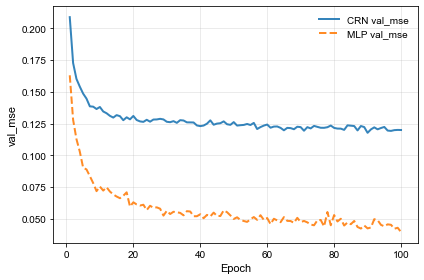

In [101]:
import matplotlib.pyplot as plt
import numpy as np

path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_reg_fin/3_2_1/"
with open(path + "results.pkl", "rb") as f:
    data = pickle.load(f)

def _hist(name):
    h = data["history"]
    if isinstance(h, dict) and name in h:
        return h[name]
    return h if name == "markov" else None

fs = 11

fig, ax = plt.subplots(figsize=(6, 4))

model_styles = {
    "markov": {"ls": "-", "color": "tab:blue", "label": "CRN val_mse"},
    "mlp": {"ls": "--", "color": "tab:orange", "label": "MLP val_mse"}
}

for name in ["markov", "mlp"]:
    hh = _hist(name)
    if hh is None or "val_mse" not in hh:
        continue
    y = [v for v in hh["val_mse"] if v is not None]
    if not y:
        continue
    ax.plot(
        np.arange(1, len(y) + 1),
        y,
        model_styles[name]["ls"],
        color=model_styles[name]["color"],
        label=model_styles[name]["label"],
        linewidth=2,
        alpha=0.9
    )

ax.set_xlabel("Epoch", fontsize=fs)
ax.set_ylabel("val_mse", fontsize=fs)
ax.legend(frameon=False, fontsize=fs - 1)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

  Initialized Markov ICL Regression model (N=1)
  Context/regression scorer: linear
  Parameters: 12,550
1.0


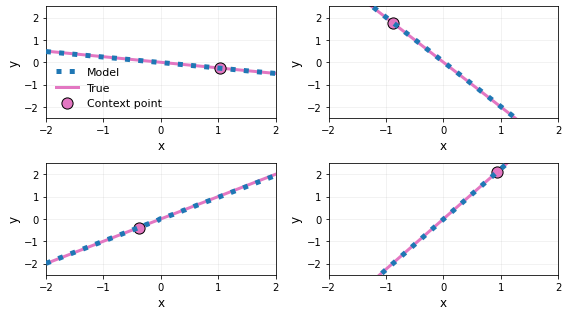

In [104]:
# ============================================================
# Linear curve plots from a saved run, panel of 2x2, legend in one panel, no titles
# ============================================================
import os
import pickle
import numpy as np
import torch
import matplotlib.pyplot as plt

from models import MatrixTreeMarkovICLRegression

# --- match your heatmap cell ---
param1_values = [1, 2, 3]  # N (context length)
param2_values = [1, 2, 3]  # D (dimension)
param3_values = [1, 2, 3, 4, 5]  # seed

path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_reg_fin/"

# Pick one cell from the grid (must have D=1 for 2D y-vs-x curves)
PLOT_N, PLOT_D, PLOT_SEED = 1, 1, 1


def load_markov_model_from_run_dir(run_dir, device=None):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    run_dir = os.path.abspath(run_dir)
    results_path = os.path.join(run_dir, "results.pkl")
    with open(results_path, "rb") as f:
        data = pickle.load(f)
    p = data["params"]

    model = MatrixTreeMarkovICLRegression(
        n_nodes=p["n_nodes"],
        z_dim=p["z_dim"],
        N=p["N"],
        learn_base_rates=p["learn_base_rates"],
        transform_func=p["transform_func"],
        sparsity_rho_edge=p["sparsity_rho_edge"],
        sparsity_rho_all=p["sparsity_rho_all"],
        sparsity_rho_edge_base_W=p["sparsity_rho_edge_base_W"],
        base_mask_value=p["base_mask_value"],
        context_scorer_type=p["context_scorer_type"],
        mlp_depth=p["mlp_depth"],
        mlp_width=p["mlp_width"],
    )
    ckpt_markov = os.path.join(run_dir, "model_markov.pt")
    ckpt_single = os.path.join(run_dir, "model.pt")
    if os.path.isfile(ckpt_markov):
        state = torch.load(ckpt_markov, map_location=device, weights_only=True)
    elif os.path.isfile(ckpt_single):
        state = torch.load(ckpt_single, map_location=device, weights_only=True)
    else:
        raise FileNotFoundError(
            f"Expected model_markov.pt or model.pt in {run_dir}"
        )
    model.load_state_dict(state)
    model.to(device)
    return model, p, data


run_dir = os.path.join(path_base, f"{PLOT_N}_{PLOT_D}_{PLOT_SEED}")
model, params_loaded, _data = load_markov_model_from_run_dir(run_dir)
device = next(model.parameters()).device

N = int(params_loaded["N"])
D = int(params_loaded["D"])
y_pad = float(params_loaded.get("y_pad", 0.0))
method = params_loaded.get("method", "direct_solve")
task_scale = float(params_loaded.get("task_scale", 1.0))
print(task_scale)
assert D == 1, "This block plots y vs x and assumes D=1."


def make_linear_episode(a, b, N=4, x_range=(-2.0, 2.0), y_pad=0.0, query_grid_size=250):
    x_min, x_max = x_range
    x_ctx = torch.empty(N, 1).uniform_(x_min, x_max)
    y_ctx = a * x_ctx.squeeze(1) + b
    xq = torch.linspace(x_min, x_max, query_grid_size).unsqueeze(1)
    y_true = a * xq.squeeze(1) + b
    z_context = torch.cat([x_ctx, y_ctx.unsqueeze(1)], dim=1)
    z_batch = []
    for i in range(query_grid_size):
        z_query = torch.tensor([xq[i, 0].item(), y_pad], dtype=z_context.dtype)
        z_seq = torch.cat([z_context, z_query.unsqueeze(0)], dim=0)
        z_batch.append(z_seq)
    z_batch = torch.stack(z_batch, dim=0)
    return x_ctx.squeeze(1), y_ctx, xq.squeeze(1), y_true, z_batch


@torch.no_grad()
def predict_curve(model, z_batch, device, method="direct_solve"):
    model.eval()
    return model(z_batch.to(device), method=method).cpu()

# --- Panel of 2x2 curves (four tasks) ---
# You can customize these (a, b) pairs for your problem
linear_tasks = [
    (-0.25 * task_scale, 0.0),
    (-2 * task_scale, 0.0),
    (1 * task_scale, 0.0),
    (2.25 * task_scale, 0.0),
]

fig, axes = plt.subplots(2, 2, figsize=(8, 4.5))
axes = axes.flatten()
fs = 12

PLOT_SEED = 1
torch.manual_seed(PLOT_SEED)
np.random.seed(PLOT_SEED)

# Set common limits
xlim = (-2, 2)
ylim = (-2 * task_scale - 0.5, 2 * task_scale + 0.5)  # Adjust as appropriate for your a, b ranges

for i, ((a, b), ax) in enumerate(zip(linear_tasks, axes)):
    x_ctx, y_ctx, xq, y_true, z_batch = make_linear_episode(
        a=a, b=b, N=N, x_range=xlim, y_pad=y_pad, query_grid_size=250
    )
    y_pred = predict_curve(model, z_batch, device=device, method=method)

    truecol = "tab:pink"
    modelcol = "#1f77b4"
    contextcol = "springgreen"
    ax.plot(xq.numpy(), y_pred.numpy(), ":", lw=5, label="Model", color = modelcol, zorder = 20)
    ax.plot(xq.numpy(), y_true.numpy(), lw=3, label="True", color = truecol)
    
    ax.scatter(x_ctx.numpy(), y_ctx.numpy(), s=125, zorder=3, edgecolor = "k", label="Context point", color = truecol)
    #ax.scatter(0, 0 , s=125, zorder=-10, color = "black", label="Origin")
    # Omit titles
    ax.set_xlabel("x", fontsize=fs)
    ax.set_ylabel("y", fontsize=fs)
    ax.grid(alpha=0.2)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    # Only show legend in the top-left panel (axes[0])
    if i == 0:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles, labels, loc="lower left", fontsize=fs-1, frameon=False, ncol=1)
    else:
        ax.legend().remove()

fig.tight_layout()
plt.show()

save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"

fig.savefig(save_path + "ICLRegressionCurves.png", dpi=300, bbox_inches="tight")

In [2]:
# ============================================================
# 3D isosurfaces: analytic vs Markov model (loaded from disk)
# ============================================================
import os
import pickle
import numpy as np
import torch
import plotly.graph_objects as go

from models import MatrixTreeMarkovICLRegression

# --- match your sweep folders: N_D_seed/ ---
path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_reg_fin/"
PLOT_N, PLOT_D, PLOT_SEED = 1, 1, 1
fs = 11

def load_markov_model_from_run_dir(run_dir, device=None):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    run_dir = os.path.abspath(run_dir)
    with open(os.path.join(run_dir, "results.pkl"), "rb") as f:
        data = pickle.load(f)
    p = data["params"]

    model = MatrixTreeMarkovICLRegression(
        n_nodes=p["n_nodes"],
        z_dim=p["z_dim"],
        N=p["N"],
        learn_base_rates=p["learn_base_rates"],
        transform_func=p["transform_func"],
        sparsity_rho_edge=p["sparsity_rho_edge"],
        sparsity_rho_all=p["sparsity_rho_all"],
        sparsity_rho_edge_base_W=p["sparsity_rho_edge_base_W"],
        base_mask_value=p["base_mask_value"],
        context_scorer_type=p["context_scorer_type"],
        mlp_depth=p["mlp_depth"],
        mlp_width=p["mlp_width"],
    )
    ck_m = os.path.join(run_dir, "model_markov.pt")
    ck_1 = os.path.join(run_dir, "model.pt")
    if os.path.isfile(ck_m):
        state = torch.load(ck_m, map_location=device, weights_only=True)
    elif os.path.isfile(ck_1):
        state = torch.load(ck_1, map_location=device, weights_only=True)
    else:
        raise FileNotFoundError(f"No model_markov.pt or model.pt in {run_dir}")
    model.load_state_dict(state)
    model.to(device)
    return model, p


run_dir = os.path.join(path_base, f"{PLOT_N}_{PLOT_D}_{PLOT_SEED}")
model, params_loaded = load_markov_model_from_run_dir(run_dir)
device = next(model.parameters()).device

N = int(params_loaded["N"])
D = int(params_loaded["D"])
y_pad = float(params_loaded.get("y_pad", 0.0))
method = params_loaded.get("method", "direct_solve")
task_scale = float(params_loaded.get("task_scale", 1.0))

assert D == 1, "This volume construction matches the D=1 linear-ICL notebook derivation."

# --- knobs (line y = a*x + b; scale a like training if you like) ---
a, b = 0.4 * task_scale, 0.0
x_range = (-2.0, 2.0)
grid_n = 50
eps = 1e-2
colorscale = "Viridis"
save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"

# --- shared 3D grid (X, Y, Z) = (last ctx x, last ctx y, query x) ---
xs = np.linspace(x_range[0], x_range[1], grid_n, dtype=np.float32)
ys = np.linspace(x_range[0], x_range[1], grid_n, dtype=np.float32)
zs = np.linspace(x_range[0], x_range[1], grid_n, dtype=np.float32)
X, Y, Z = np.meshgrid(xs, ys, zs, indexing="ij")

# --- analytic: Z * (Y / X), mask |Z| > eps ---
F_a = np.full_like(X, np.nan, dtype=np.float64)
m = np.abs(Z) > eps
F_a[m] = Z[m] * (Y[m] / X[m])
F_a[np.abs(X) < eps] = np.nan

# --- model ---
dtype = torch.float32
X_t = torch.from_numpy(X).to(dtype)
Y_t = torch.from_numpy(Y).to(dtype)
Z_t = torch.from_numpy(Z).to(dtype)
flat = X_t.numel()
Xv = X_t.reshape(-1)
Yv = Y_t.reshape(-1)
Zv = Z_t.reshape(-1)

if N > 1:
    x_pre = torch.empty(N - 1, 1, dtype=dtype).uniform_(x_range[0], x_range[1])
    y_pre = a * x_pre.squeeze(1) + b
    prefix = torch.cat([x_pre, y_pre.unsqueeze(1)], dim=1)
else:
    prefix = torch.empty(0, 2, dtype=dtype)

parts = []
if prefix.shape[0] > 0:
    parts.append(prefix.unsqueeze(0).expand(flat, -1, -1))
parts.append(torch.stack([Xv, Yv], dim=-1).unsqueeze(1))
parts.append(
    torch.stack([Zv, torch.full_like(Zv, float(y_pad), dtype=dtype)], dim=-1).unsqueeze(1)
)
z_batch = torch.cat(parts, dim=1)

model.eval()
with torch.no_grad():
    F_m = (
        model(z_batch.to(device), method=method)
        .reshape(grid_n, grid_n, grid_n)
        .cpu()
        .numpy()
    )

# --- shared color limits ---
stack = np.concatenate([F_a.ravel(), F_m.ravel()])
stack = stack[np.isfinite(stack)]
vmin, vmax = np.percentile(stack, [5, 95])
if (not np.isfinite(vmin)) or (not np.isfinite(vmax)) or vmin == vmax:
    vmin = float(np.nanmin(F_m))
    vmax = float(np.nanmax(F_m))

# Axis titles with HTML subscripts
axis_titles = ("x<sub>c</sub>", "y<sub>c</sub>", "x<sub>q</sub>")

# Use fs fontsize for all text and tick labels
# Shared scene configuration
scene_config = dict(
    xaxis_title=axis_titles[0],
    yaxis_title=axis_titles[1],
    zaxis_title=axis_titles[2],
    xaxis=dict(
        showgrid=True,
        showbackground=False,
        gridcolor="whitesmoke",
        tickfont=dict(size=fs),
        title_font=dict(size=fs),
    ),
    yaxis=dict(
        showgrid=True,
        showbackground=False,
        gridcolor="whitesmoke",
        tickfont=dict(size=fs),
        title_font=dict(size=fs),
    ),
    zaxis=dict(
        showgrid=True,
        showbackground=False,
        gridcolor="whitesmoke",
        tickfont=dict(size=fs),
        title_font=dict(size=fs),
    ),
    aspectmode="cube",
    camera=dict(eye=dict(x=1.5, y=1.5, z=1.5)),  # Larger values = more zoomed out
    bgcolor='white'
)

# Shared layout configuration with consistent fontsize fs
layout_config = dict(
    width=600,
    height=400,
    margin=dict(l=0, r=0, t=0, b=0),
    #margin=dict(l=50, r=50, t=50, b=50),
    font=dict(family="Arial, sans-serif", size=fs, color='black')
)

# --------- 3D plot: Analytic ----------
analytic_fig = go.Figure()
analytic_fig.add_trace(go.Isosurface(
    value=np.nan_to_num(F_a, nan=0.0).ravel(),
    x=X.ravel(),
    y=Y.ravel(),
    z=Z.ravel(),
    isomin=vmin,
    isomax=vmax,
    colorscale=colorscale,
    cmin=vmin,
    cmax=vmax,
    surface_count=10,
    showscale=False,
    caps=dict(x_show=False, y_show=False, z_show=False),
))
analytic_fig.update_scenes(scene_config)
analytic_fig.update_layout(**layout_config)
analytic_fig.show()

# --------- 3D plot: Model ----------
model_fig = go.Figure()
model_fig.add_trace(go.Isosurface(
    value=np.nan_to_num(F_m, nan=0.0).ravel(),
    x=X.ravel(),
    y=Y.ravel(),
    z=Z.ravel(),
    isomin=vmin,
    isomax=vmax,
    colorscale=colorscale,
    cmin=vmin,
    cmax=vmax,
    surface_count=10,
    showscale=False,
    # colorbar=dict(
    #     title=dict(text="Value", font=dict(size=fs)),
    #     tickfont=dict(size=fs), 
    #     len=0.75, 
    #     x=1.02, 
    #     tickformat="d"
    # ),
    caps=dict(x_show=False, y_show=False, z_show=False),
))
model_fig.update_scenes(scene_config)
model_fig.update_layout(**layout_config)
model_fig.show()

# --- SAVE both figures ---
# analytic_fig.write_image(save_path + "RegressionSurfaceAnalytic.png", scale = 3)#, dpi = 300, bbox_inches="tight")
# model_fig.write_image(save_path + "RegressionSurfaceModel.png", scale = 3)#, dpi = 300, bbox_inches="tight")

  Initialized Markov ICL Regression model (N=1)
  Context/regression scorer: linear
  Parameters: 12,550


<ipython-input-3-f3919e6bd278>:11: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.

<ipython-input-3-f3919e6bd278>:16: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.



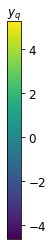

In [3]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colorbar import ColorbarBase
import matplotlib.cm as cm

# Create figure for colorbar only
fig_cb, ax_cb = plt.subplots(figsize=(0.25, 4))
# Create colorbar
fs = 12
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
cmap = cm.get_cmap('viridis')  # Match your colorscale
cb = ColorbarBase(ax_cb, cmap=cmap, norm=norm, orientation='vertical')
# Use set_title with HTML markup via mpl's support for it in set_title
ax_cb.set_title(r'$y_q$', fontsize=fs)
cb.ax.tick_params(labelsize=fs)
plt.tight_layout()
plt.savefig(save_path + "Colorbar.png", dpi=300, bbox_inches='tight')
plt.show()

# Oddball plots

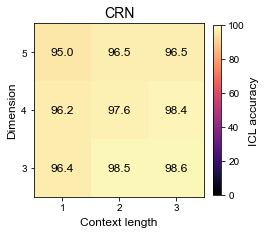

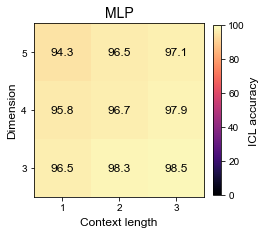


Non-NaN values - Markov: 45/45
Non-NaN values - MLP: 45/45


In [144]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Arial"

# --- sweep axes (edit to match your folder names param1_param2_param3/) ---
# param1: N (context length), param2: D (dimension), param3: seed
param1_values = [3, 4, 5]    # N (context length)
param2_values = [2, 3, 4]    # D (dimension)
param2_values = [1, 2, 3]    # D (dimension)
#param2_values = [1, 2, 3, 4, 5]    # D (dimension)
param3_values = [1, 2, 3, 4, 5]  # seed

path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_sphereodd_fin/"
tag = "_Sphere"

fac = 0.8
figsize = (4.75*fac, 4.2*fac)
# Which distance to extract accuracy for (or 'train' for training distance, or 'mean' for average)
DISTANCE_TO_EXTRACT = 'train'  # Options: 'train', 'mean', or a specific distance like 5

def _extract_accuracy_at_distance(results_dict, target_dist='train', train_dist=5.0):
    """
    Extract test accuracy from results at a specific distance.
    """
    if not isinstance(results_dict, dict) or "by_distance" not in results_dict:
        return np.nan
    
    by_dist = results_dict["by_distance"]
    
    if target_dist == 'train':
        # Get accuracy at training distance
        return float(by_dist.get(train_dist, np.nan))
    elif target_dist == 'mean':
        # Get mean accuracy across all distances
        accs = [v for v in by_dist.values() if v is not None]
        return float(np.mean(accs)) if accs else np.nan
    else:
        # Get accuracy at specific distance
        return float(by_dist.get(target_dist, np.nan))

results_grid_markov = np.full(
    (len(param1_values), len(param2_values), len(param3_values)), np.nan, dtype=float
)
results_grid_mlp = np.full(
    (len(param1_values), len(param2_values), len(param3_values)), np.nan, dtype=float
)

for i, param1 in enumerate(param1_values):
    for j, param2 in enumerate(param2_values):
        for k, param3 in enumerate(param3_values):
            path = path_base + f"{param1}_{param2}_{param3}/"
            results_path = path + "results.pkl"
            try:
                with open(results_path, "rb") as f:
                    data = pickle.load(f)
                
                results = data.get("results", {})
                params = data.get("params", {})
                train_dist = params.get("perturb_dist", 5.0)
                
                train_dist = 5
                # Handle multi-model results
                if isinstance(results, dict):
                    if "markov" in results:
                        results_grid_markov[i, j, k] = _extract_accuracy_at_distance(
                            results["markov"], DISTANCE_TO_EXTRACT, train_dist
                        )
                    else:
                        # Single model case
                        results_grid_markov[i, j, k] = _extract_accuracy_at_distance(
                            results, DISTANCE_TO_EXTRACT, train_dist
                        )
                    
                    if "mlp" in results:
                        results_grid_mlp[i, j, k] = _extract_accuracy_at_distance(
                            results["mlp"], DISTANCE_TO_EXTRACT, train_dist
                        )
                        
            except Exception as e:
                print(f"Error loading {results_path}: {e}")

save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"
fs = 12

# --- Single heatmap for Markov ---
fig_markov, ax_markov = plt.subplots(figsize=figsize)
grid = results_grid_markov
results_grid_avg = np.nanmean(grid, axis=2)
# Accuracy typically ranges from 0 to 100 (percent)
vmin, vmax = 0.0, 100.0
im = ax_markov.imshow(
    results_grid_avg.T,
    cmap="magma",  # Higher accuracy is better
    aspect="auto",
    origin="lower",
    vmin=vmin,
    vmax=vmax,
)
# Show numbers on the grid
for (i, j), val in np.ndenumerate(results_grid_avg):
    label = f"{val:.1f}" if not np.isnan(val) else "N/A"
    ax_markov.text(
        i, j, label,
        ha="center", va="center",
        color="white" if not np.isnan(val) and val < 50 else "black",
        fontsize=fs
    )
ax_markov.set_title("CRN", fontsize=fs+2)
ax_markov.set_xlabel("Context length", fontsize=fs)
ax_markov.set_ylabel("Dimension", fontsize=fs)
ax_markov.set_xticks(range(len(param2_values)), param2_values)
ax_markov.set_yticks(range(len(param1_values)), param1_values)
cbar = fig_markov.colorbar(im, ax=ax_markov, shrink=0.98, pad=0.04)
cbar.set_label(f"ICL accuracy", size=fs)

plt.tight_layout()
plt.show()
fig_markov.savefig(save_path + "AccuracyHeatmaps_CRN" + tag + ".png", dpi=300, bbox_inches="tight")

# --- Single heatmap for MLP ---
fig_mlp, ax_mlp = plt.subplots(figsize=figsize)
grid = results_grid_mlp
results_grid_avg = np.nanmean(grid, axis=2)
# Accuracy typically ranges from 0 to 100 (percent)
vmin, vmax = 0.0, 100.0
im = ax_mlp.imshow(
    results_grid_avg.T,
    cmap="magma",  # Higher accuracy is better
    aspect="auto",
    origin="lower",
    vmin=vmin,
    vmax=vmax,
)
# Show numbers on the grid
for (i, j), val in np.ndenumerate(results_grid_avg):
    label = f"{val:.1f}" if not np.isnan(val) else "N/A"
    ax_mlp.text(
        i, j, label,
        ha="center", va="center",
        color="white" if not np.isnan(val) and val < 50 else "black",
        fontsize=fs
    )
ax_mlp.set_title("MLP", fontsize=fs+2)
ax_mlp.set_xlabel("Context length", fontsize=fs)
ax_mlp.set_ylabel("Dimension", fontsize=fs)
ax_mlp.set_xticks(range(len(param2_values)), param2_values)
ax_mlp.set_yticks(range(len(param1_values)), param1_values)
cbar = fig_mlp.colorbar(im, ax=ax_mlp, shrink=0.98, pad=0.04)
cbar.set_label(f"ICL accuracy", size=fs)

plt.tight_layout()
plt.show()
fig_mlp.savefig(save_path + "AccuracyHeatmaps_MLP" + tag + ".png", dpi=300, bbox_inches="tight")

# Print summary
print(f"\nNon-NaN values - Markov: {np.sum(~np.isnan(results_grid_markov))}/{results_grid_markov.size}")
print(f"Non-NaN values - MLP: {np.sum(~np.isnan(results_grid_mlp))}/{results_grid_mlp.size}")

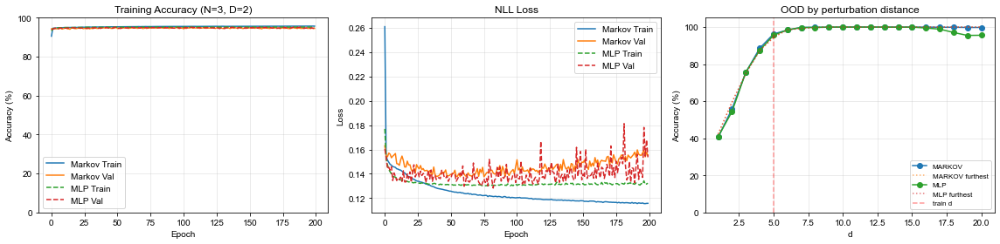


Run: N=3, D=2, seed=3
Training time: 9901.60 seconds

Final Training Accuracy:
  Markov: 95.74%
  MLP: 95.26%

Final Validation Accuracy:
  Markov: 94.58%
  MLP: 94.90%


In [115]:
import pickle
import matplotlib.pyplot as plt

# Select which run to plot (param1=N, param2=D, param3=seed)
param1_select = 3  # N (context length)
param2_select = 2  # D (dimension)
param3_select = 3  # seed

path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_sphereodd_fin/"
results_path = path_base + f"{param1_select}_{param2_select}_{param3_select}/results.pkl"

# Load the results
with open(results_path, "rb") as f:
    data = pickle.load(f)

history = data["history"]
results = data["results"]
params = data["params"]
perturb_dist = params["perturb_dist"]

# Get model histories
h_m = history["markov"] if isinstance(history, dict) and "markov" in history else history
h_mlp = history.get("mlp") if isinstance(history, dict) else None

# Create 3-panel plot
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Panel 1: Training Accuracy
ax1 = axes[0]
ax1.plot(h_m["train_acc"], label="Markov Train")
ax1.plot(h_m["val_acc"], label="Markov Val")
if h_mlp is not None:
    ax1.plot(h_mlp["train_acc"], "--", label="MLP Train")
    ax1.plot(h_mlp["val_acc"], "--", label="MLP Val")
ax1.set_title(f"Training Accuracy (N={param1_select}, D={param2_select})")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy (%)")
ax1.set_ylim([0, 100])
ax1.grid(True, alpha=0.3)
ax1.legend()

# Panel 2: Training Loss
ax2 = axes[1]
ax2.plot(h_m["train_loss"], label="Markov Train")
ax2.plot(h_m["val_loss"], label="Markov Val")
if h_mlp is not None:
    ax2.plot(h_mlp["train_loss"], "--", label="MLP Train")
    ax2.plot(h_mlp["val_loss"], "--", label="MLP Val")
ax2.set_title("NLL Loss")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.grid(True, alpha=0.3)
ax2.legend()

# Panel 3: OOD Performance by Distance
ax3 = axes[2]
# Handle both single model and multi-model results
if isinstance(results, dict) and "markov" in results:
    # Multi-model case
    for name in results.keys():
        dists = sorted(results[name]["by_distance"].keys())
        accs = [results[name]["by_distance"][d] for d in dists]
        ax3.plot(dists, accs, "o-", label=name.upper())
        baseline = [results[name]["furthest_point_baseline"][d] for d in dists]
        ax3.plot(dists, baseline, ":", alpha=0.6, label=f"{name.upper()} furthest")
else:
    # Single model case
    dists = sorted(results["by_distance"].keys())
    accs = [results["by_distance"][d] for d in dists]
    ax3.plot(dists, accs, "o-", label="Markov")
    baseline = [results["furthest_point_baseline"][d] for d in dists]
    ax3.plot(dists, baseline, ":", alpha=0.6, label="Furthest baseline")

ax3.axvline(x=perturb_dist, color="r", linestyle="--", alpha=0.4, label="train d")
ax3.set_title("OOD by perturbation distance")
ax3.set_xlabel("d")
ax3.set_ylabel("Accuracy (%)")
ax3.set_ylim([0, 105])
ax3.grid(True, alpha=0.3)
ax3.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"\n{'='*70}")
print(f"Run: N={param1_select}, D={param2_select}, seed={param3_select}")
print(f"{'='*70}")
print(f"Training time: {data['execution_time']:.2f} seconds")
print(f"\nFinal Training Accuracy:")
if isinstance(history, dict) and "markov" in history:
    print(f"  Markov: {h_m['train_acc'][-1]:.2f}%")
    if h_mlp is not None:
        print(f"  MLP: {h_mlp['train_acc'][-1]:.2f}%")
else:
    print(f"  {h_m['train_acc'][-1]:.2f}%")

print(f"\nFinal Validation Accuracy:")
if isinstance(history, dict) and "markov" in history:
    print(f"  Markov: {h_m['val_acc'][-1]:.2f}%")
    if h_mlp is not None:
        print(f"  MLP: {h_mlp['val_acc'][-1]:.2f}%")
else:
    print(f"  {h_m['val_acc'][-1]:.2f}%")

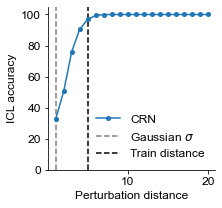

<Figure size 432x288 with 0 Axes>

In [134]:
import pickle
import matplotlib.pyplot as plt

fs = 12

# Select which run to plot (param1=N, param2=D, param3=seed)
param1_select = 4  # N (context length)
param2_select = 2  # D (dimension)
param3_select = 1  # seed

path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_sphereodd_fin/"
results_path = path_base + f"{param1_select}_{param2_select}_{param3_select}/results.pkl"

with open(results_path, "rb") as f:
    data = pickle.load(f)

results = data["results"]
perturb_dist = data["params"]["perturb_dist"]

fig, ax = plt.subplots(1, 1, figsize=(3, 3))

labels = ["CRN", "MLP"]
if isinstance(results, dict) and "markov" in results:
    #for (i, name) in enumerate(results.keys()):
    for (i, name) in enumerate(["markov"]):
        dists = sorted(results[name]["by_distance"].keys())
        accs = [results[name]["by_distance"][d] for d in dists]
        ax.plot(dists, accs, "o-", label=labels[i], markersize = 4)
        baseline = [results[name]["furthest_point_baseline"][d] for d in dists]
        #ax.plot(dists, baseline, ":", alpha=0.6, label=f"{name.upper()} furthest")
else:
    dists = sorted(results["by_distance"].keys())
    accs = [results["by_distance"][d] for d in dists]
    ax.plot(dists, accs, "o-", label="MLP")
    baseline = [results["furthest_point_baseline"][d] for d in dists]
    #ax.plot(dists, baseline, ":", alpha=0.6, label="Furthest baseline")

ax.axvline(x=1, color="gray", linestyle="--", alpha=1, label=r"Gaussian $\sigma$", zorder = -10)
ax.axvline(x=5, color="black", linestyle="--", alpha=1, label="Train distance", zorder = -10)

#ax.set_title(f"OOD by perturbation distance (N={param1_select}, D={param2_select})", fontsize=fs)
ax.set_xlabel("Perturbation distance", fontsize=fs)
ax.set_ylabel("ICL accuracy", fontsize=fs)
ax.set_ylim([0, 105])
ax.tick_params(labelsize=fs)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
#ax.grid(True, alpha=0.3)
ax.legend(fontsize=fs, frameon=False, loc='lower right')

plt.show()
fig.savefig(save_path + "SphereOddballDistance.png", dpi=300, bbox_inches="tight")

plt.tight_layout()
plt.show()

  Initialized Markov ICL Oddball model (N=5, L=5, z_dim=2)
  Rate encoder: linear
  Rate decoder: linear
  Parameters: 27,750
Loaded model: N=5, D=2, task=line
Visualizing 200 test episodes


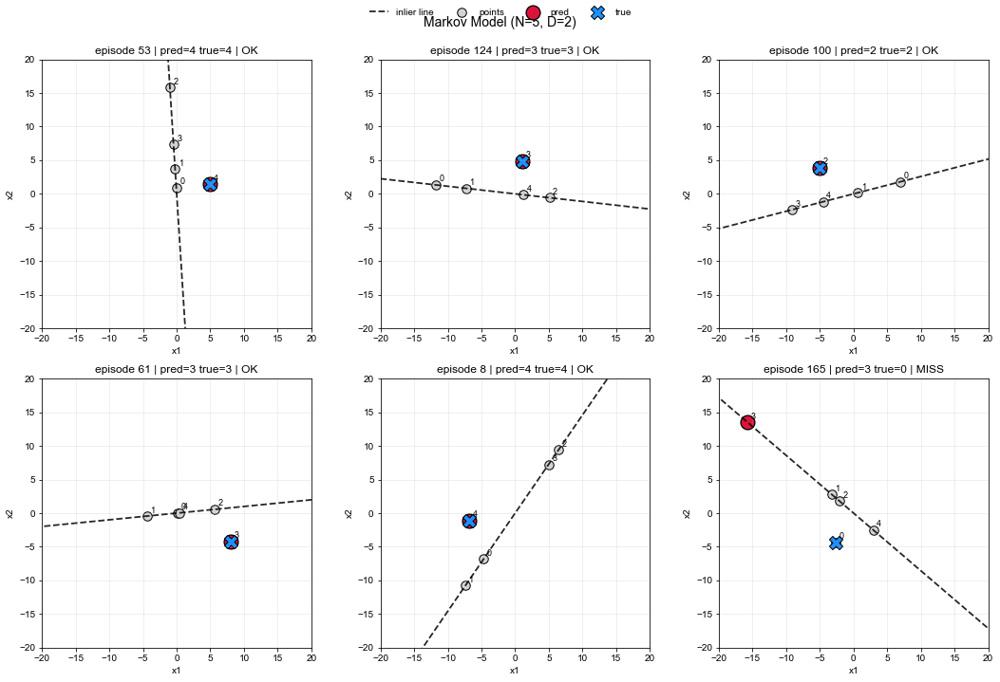

  Initialized MLP ICL Oddball model (N=5, z_dim=2, depth=4, width=64, activation=relu, dropout=0.0)
  Parameters: 9,349


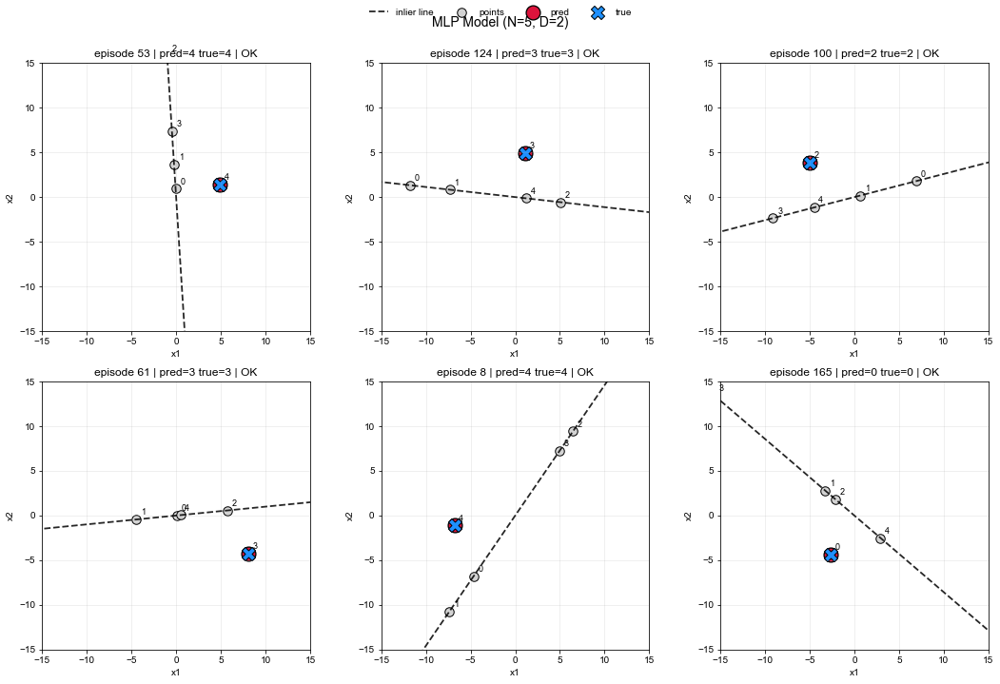

In [94]:
import pickle
import numpy as np
import torch
import matplotlib.pyplot as plt
from data_generation_oddball import generate_oddball_data
from models import MatrixTreeMarkovICLOddball, MLPICLOddball

def _fit_line_from_points(points_2d):
    """
    Fit line via PCA/SVD.
    Returns (center, direction_unit).
    """
    c = points_2d.mean(axis=0)
    X = points_2d - c
    _, _, vh = np.linalg.svd(X, full_matrices=False)
    v = vh[0]
    v = v / (np.linalg.norm(v) + 1e-12)
    return c, v

def _line_segment_from_center_dir(center, direction, xlim, ylim):
    """
    Build a long segment clipped by plot ranges for drawing.
    """
    span = max(xlim[1] - xlim[0], ylim[1] - ylim[0]) * 1.5
    t = np.array([-span, span])
    pts = center[None, :] + t[:, None] * direction[None, :]
    return pts[:, 0], pts[:, 1]

def plot_hyperplane_oddball_grid(
    model,
    data,
    device="cpu",
    method="direct_solve",
    temperature=1.0,
    seed=None,
    nrows=2,
    ncols=3,
    figsize=None,
    xlim=(-15, 15),
    ylim=(-15, 15),
):
    """
    Grid plot for hyperplane oddball in D=2 (line oddball).
    `data` is list of (z_context, target) with target 1-indexed.
    """
    n_episodes = nrows * ncols
    if len(data) < n_episodes:
        raise ValueError(f"Need at least {n_episodes} episodes in `data`.")

    rng = np.random.default_rng(seed)
    idxs = rng.choice(len(data), size=n_episodes, replace=False)

    if figsize is None:
        figsize = (5 * ncols, 5 * nrows)

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)

    model.eval()
    with torch.no_grad():
        for ax, data_idx in zip(axes, idxs):
            z_context, target = data[data_idx]
            if not torch.is_tensor(z_context):
                z_context = torch.tensor(z_context, dtype=torch.float32)

            z = z_context.detach().cpu().numpy()  # (N, 2)
            if z.shape[1] != 2:
                raise ValueError("This plotter expects D=2 so the hyperplane is a line.")

            true_idx = int(target) - 1

            # model prediction (0-based)
            log_probs = model(
                z_context.unsqueeze(0).to(device),
                method=method,
                temperature=temperature
            )
            pred_idx = int(log_probs.argmax(dim=1).item())

            # fit line from true inliers (all points except true oddball)
            inlier_mask = np.ones(len(z), dtype=bool)
            inlier_mask[true_idx] = False
            inliers = z[inlier_mask]
            center, direction = _fit_line_from_points(inliers)
            lx, ly = _line_segment_from_center_dir(center, direction, xlim, ylim)

            # draw line
            ax.plot(lx, ly, "--", color="black", linewidth=1.8, alpha=0.85, label="inlier line")

            # draw all points
            ax.scatter(z[:, 0], z[:, 1], c="lightgray", s=90, edgecolor="k", label="points")

            # predicted oddball
            ax.scatter(
                z[pred_idx, 0], z[pred_idx, 1],
                c="crimson", s=220, marker="o", edgecolor="k", linewidth=1.3, label="pred"
            )

            # true oddball
            ax.scatter(
                z[true_idx, 0], z[true_idx, 1],
                c="dodgerblue", s=200, marker="X", edgecolor="k", linewidth=1.0, label="true"
            )

            for i, (x, y) in enumerate(z):
                ax.text(x + 0.5, y + 0.5, str(i), fontsize=9)

            ok = pred_idx == true_idx
            ax.set_title(f"episode {data_idx} | pred={pred_idx} true={true_idx} | {'OK' if ok else 'MISS'}")
            ax.set_aspect("equal", adjustable="box")
            ax.grid(alpha=0.25)
            ax.set_xlabel("x1")
            ax.set_ylabel("x2")
            ax.set_xlim(*xlim)
            ax.set_ylim(*ylim)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    return fig, axes


# ============= Load saved model and parameters =============
# Select which run to visualize (param1=N, param2=D, param3=seed)
param1_select = 5  # N (context length)
param2_select = 2  # D (dimension) - MUST be 2 for hyperplane visualization
param3_select = 1  # seed

path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_lineodd_yesood2/"
results_path = path_base + f"{param1_select}_{param2_select}_{param3_select}/results.pkl"
model_path_markov = path_base + f"{param1_select}_{param2_select}_{param3_select}/model_markov.pt"
model_path_mlp = path_base + f"{param1_select}_{param2_select}_{param3_select}/model_mlp.pt"

# Load the results
with open(results_path, "rb") as f:
    data = pickle.load(f)

params = data["params"]

# Extract parameters
N = params["N"]
D = params["D"]
perturb_dist = params["perturb_dist"]
center_bound = params["center_bound"]
cluster_std = params["cluster_std"]
task_geometry = params["task_geometry"]
method = params["method"]
temperature = params["temperature"]

# Recreate the Markov model with saved parameters
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
markov_model = MatrixTreeMarkovICLOddball(
    n_nodes=params["n_nodes"],
    z_dim=params["z_dim"],
    N=N,
    learn_base_rates=params["learn_base_rates"],
    transform_func=params["transform_func"],
    sparsity_rho_edge=params["sparsity_rho_edge"],
    sparsity_rho_all=params["sparsity_rho_all"],
    sparsity_rho_edge_base_W=params["sparsity_rho_edge_base_W"],
    base_mask_value=params["base_mask_value"],
    rate_encoder_type=params["rate_encoder_type"],
    encoder_mlp_depth=params["encoder_mlp_depth"],
    encoder_mlp_width=params["encoder_mlp_width"],
    rate_decoder_type=params["rate_decoder_type"],
    decoder_mlp_depth=params["decoder_mlp_depth"],
    decoder_mlp_width=params["decoder_mlp_width"],
)

# Load saved weights
markov_model.load_state_dict(torch.load(model_path_markov, map_location=device))
markov_model.to(device)
markov_model.eval()

# Generate test data with same parameters
test_data = generate_oddball_data(
    n_samples=200,
    N=N,
    D=D,
    perturb_dist=perturb_dist,
    center_bound=center_bound,
    cluster_std=cluster_std,
    task_geometry=task_geometry,
    seed=60  # Different seed for test visualization
)

print(f"Loaded model: N={N}, D={D}, task={task_geometry}")
print(f"Visualizing {len(test_data)} test episodes")

# Create the grid plot
fig, axes = plot_hyperplane_oddball_grid(
    markov_model,
    test_data,
    device=device,
    method=method,
    temperature=temperature,
    seed=0,
    nrows=2,
    ncols=3,
    xlim=(-20, 20),
    ylim=(-20, 20)
)
plt.suptitle(f"Markov Model (N={N}, D={D})", fontsize=14, y=0.98)
plt.show()

# Optional: Create grid for MLP model if it exists
try:
    mlp_model = MLPICLOddball(
        z_dim=params["z_dim"],
        N=N,
        depth=params["mlp_baseline_depth"],
        hidden_width=params["mlp_baseline_width"],
        dropout=params["mlp_baseline_dropout"],
        activation=params["mlp_baseline_activation"],
    )
    mlp_model.load_state_dict(torch.load(model_path_mlp, map_location=device))
    mlp_model.to(device)
    mlp_model.eval()
    
    fig_mlp, axes_mlp = plot_hyperplane_oddball_grid(
        mlp_model,
        test_data,
        device=device,
        method=method,
        temperature=temperature,
        seed=0,
        nrows=2,
        ncols=3,
        xlim=(-15, 15),
        ylim=(-15, 15)
    )
    plt.suptitle(f"MLP Model (N={N}, D={D})", fontsize=14, y=0.98)
    plt.show()
except FileNotFoundError:
    print("MLP model not found - only showing Markov model")

  Initialized Markov ICL Oddball model (N=5, L=5, z_dim=2)
  Rate encoder: linear
  Rate decoder: linear
  Parameters: 27,750
Loaded model: N=5, D=2, task=line


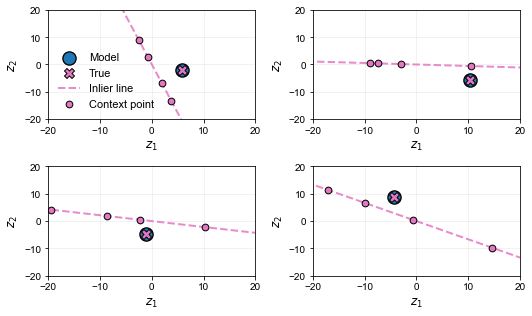

In [158]:
# ============================================================
# Hyperplane oddball plots, panel of 2x2, legend in one panel, no titles
# ============================================================
import pickle
import numpy as np
import torch
import matplotlib.pyplot as plt
from data_generation_oddball import generate_oddball_data
from models import MatrixTreeMarkovICLOddball, MLPICLOddball

def _fit_line_from_points(points_2d):
    """
    Fit line via PCA/SVD.
    Returns (center, direction_unit).
    """
    c = points_2d.mean(axis=0)
    X = points_2d - c
    _, _, vh = np.linalg.svd(X, full_matrices=False)
    v = vh[0]
    v = v / (np.linalg.norm(v) + 1e-12)
    return c, v

def _line_segment_from_center_dir(center, direction, xlim, ylim):
    """
    Build a long segment clipped by plot ranges for drawing.
    """
    span = max(xlim[1] - xlim[0], ylim[1] - ylim[0]) * 1.5
    t = np.array([-span, span])
    pts = center[None, :] + t[:, None] * direction[None, :]
    return pts[:, 0], pts[:, 1]

# ============= Load saved model and parameters =============
param1_select = 5  # N (context length)
param2_select = 2  # D (dimension) - MUST be 2 for hyperplane visualization
param3_select = 1  # seed

path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_lineodd_yesood2/"
results_path = path_base + f"{param1_select}_{param2_select}_{param3_select}/results.pkl"
model_path_markov = path_base + f"{param1_select}_{param2_select}_{param3_select}/model_markov.pt"

# Load the results
with open(results_path, "rb") as f:
    data = pickle.load(f)

params = data["params"]

# Extract parameters
N = params["N"]
D = params["D"]
perturb_dist = params["perturb_dist"]
center_bound = params["center_bound"]
cluster_std = params["cluster_std"]
task_geometry = params["task_geometry"]
method = params["method"]
temperature = params["temperature"]

# Recreate the Markov model with saved parameters
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
markov_model = MatrixTreeMarkovICLOddball(
    n_nodes=params["n_nodes"],
    z_dim=params["z_dim"],
    N=N,
    learn_base_rates=params["learn_base_rates"],
    transform_func=params["transform_func"],
    sparsity_rho_edge=params["sparsity_rho_edge"],
    sparsity_rho_all=params["sparsity_rho_all"],
    sparsity_rho_edge_base_W=params["sparsity_rho_edge_base_W"],
    base_mask_value=params["base_mask_value"],
    rate_encoder_type=params["rate_encoder_type"],
    encoder_mlp_depth=params["encoder_mlp_depth"],
    encoder_mlp_width=params["encoder_mlp_width"],
    rate_decoder_type=params["rate_decoder_type"],
    decoder_mlp_depth=params["decoder_mlp_depth"],
    decoder_mlp_width=params["decoder_mlp_width"],
)

# Load saved weights
markov_model.load_state_dict(torch.load(model_path_markov, map_location=device))
markov_model.to(device)
markov_model.eval()

# Generate test data with same parameters
PLOT_SEED = 8000 #8000
test_data = generate_oddball_data(
    n_samples=200,
    N=N,
    D=D,
    perturb_dist=perturb_dist,
    center_bound=center_bound,
    cluster_std=cluster_std,
    task_geometry=task_geometry,
    seed=PLOT_SEED
)

print(f"Loaded model: N={N}, D={D}, task={task_geometry}")

# --- Panel of 2x2 oddball episodes ---
fig, axes = plt.subplots(2, 2, figsize=(7.5, 4.5))
axes = axes.flatten()
fs = 12

# Set common limits
xlim = (-20, 20)
ylim = (-20, 20)

# Select 4 episodes to visualize
rng = np.random.default_rng(0)
episode_idxs = rng.choice(len(test_data), size=4, replace=False)

for i, (ax, data_idx) in enumerate(zip(axes, episode_idxs)):
    z_context, target = test_data[data_idx]
    if not torch.is_tensor(z_context):
        z_context = torch.tensor(z_context, dtype=torch.float32)

    z = z_context.detach().cpu().numpy()  # (N, 2)
    true_idx = int(target) - 1

    # Model prediction (0-based)
    with torch.no_grad():
        log_probs = markov_model(
            z_context.unsqueeze(0).to(device),
            method=method,
            temperature=temperature
        )
        pred_idx = int(log_probs.argmax(dim=1).item())

    # Fit line from true inliers (all points except true oddball)
    inlier_mask = np.ones(len(z), dtype=bool)
    inlier_mask[true_idx] = False
    inliers = z[inlier_mask]
    center, direction = _fit_line_from_points(inliers)
    lx, ly = _line_segment_from_center_dir(center, direction, xlim, ylim)

    truecol = "tab:pink"
    modelcol = "#1f77b4"
    
    ax.scatter(
        z[pred_idx, 0], z[pred_idx, 1],
        c=modelcol, s=175, marker="o", edgecolor="k", linewidth=1.3, label="Model", zorder=4
    )
    # True oddball
    ax.scatter(
        z[true_idx, 0], z[true_idx, 1],
        c=truecol, s=100, marker="X", edgecolor="k", linewidth=1.0, label="True", zorder=10
    )
    # Draw line
    ax.plot(lx, ly, "--", color=truecol, linewidth=2, alpha=0.85, label="Inlier line")
    # Draw all points
    ax.scatter(z[:, 0], z[:, 1], c=truecol, s=45, edgecolor="k", label="Context point", zorder=2)
    # Predicted oddball
    
    

    # Omit titles
    ax.set_xlabel("$z_1$", fontsize=fs)
    ax.set_ylabel("$z_2$", fontsize=fs)
    ax.grid(alpha=0.2)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    #ax.set_aspect("equal", adjustable="box")

    # Only show legend in the top-left panel (axes[0])
    if i == 0:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles, labels, loc="lower left", fontsize=fs-1, frameon=False, ncol=1)
    else:
        ax.legend().remove()

fig.tight_layout()
plt.show()

save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"
fig.savefig(save_path + "ICLLineOddballCurves.png", dpi=300, bbox_inches="tight")

  Initialized Markov ICL Oddball model (N=5, L=5, z_dim=2)
  Rate encoder: linear
  Rate decoder: linear
  Parameters: 27,750
Loaded model: N=5, D=2, task=sphere, d=5.0


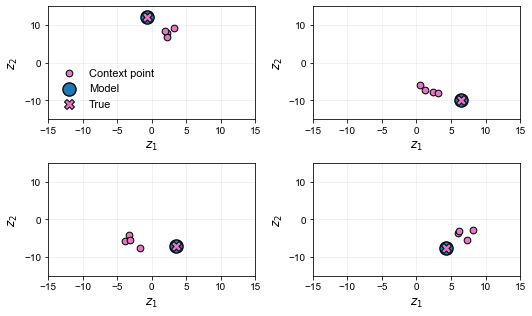

In [159]:
# ============================================================
# Sphere oddball plots, 2x2 panel, legend in one panel, no titles
# ============================================================
import pickle
import numpy as np
import torch
import matplotlib.pyplot as plt
from data_generation_oddball import generate_sphere_oddball_data
from models import MatrixTreeMarkovICLOddball

# ============= Load saved model and parameters =============
param1_select = 5  # N (context length)
param2_select = 2  # D (dimension) - MUST be 2 for visualization
param3_select = 3  # seed

path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_sphereodd_fin/"
results_path = path_base + f"{param1_select}_{param2_select}_{param3_select}/results.pkl"
model_path_markov = path_base + f"{param1_select}_{param2_select}_{param3_select}/model_markov.pt"

with open(results_path, "rb") as f:
    data = pickle.load(f)

params = data["params"]

N = params["N"]
D = params["D"]
perturb_dist = params["perturb_dist"]
center_bound = params["center_bound"]
cluster_std = params["cluster_std"]
method = params["method"]
temperature = params["temperature"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
markov_model = MatrixTreeMarkovICLOddball(
    n_nodes=params["n_nodes"],
    z_dim=params["z_dim"],
    N=N,
    learn_base_rates=params["learn_base_rates"],
    transform_func=params["transform_func"],
    sparsity_rho_edge=params["sparsity_rho_edge"],
    sparsity_rho_all=params["sparsity_rho_all"],
    sparsity_rho_edge_base_W=params["sparsity_rho_edge_base_W"],
    base_mask_value=params["base_mask_value"],
    rate_encoder_type=params["rate_encoder_type"],
    encoder_mlp_depth=params["encoder_mlp_depth"],
    encoder_mlp_width=params["encoder_mlp_width"],
    rate_decoder_type=params["rate_decoder_type"],
    decoder_mlp_depth=params["decoder_mlp_depth"],
    decoder_mlp_width=params["decoder_mlp_width"],
)

markov_model.load_state_dict(torch.load(model_path_markov, map_location=device))
markov_model.to(device)
markov_model.eval()

PLOT_SEED = 50
test_data = generate_sphere_oddball_data(
    n_samples=200,
    N=N,
    D=D,
    perturb_dist=perturb_dist,
    center_bound=center_bound,
    cluster_std=cluster_std,
    seed=PLOT_SEED,
)

print(f"Loaded model: N={N}, D={D}, task=sphere, d={perturb_dist}")

# --- 2x2 panel of sphere oddball episodes ---
nrows, ncols = 2, 2
n_episodes = nrows * ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(7.5, 4.5))
axes = np.array(axes).reshape(-1)
fs = 12

# Set colors to match line oddball styling
truecol = "tab:pink"
modelcol = "#1f77b4"

bound = 15
xlim = (-bound, bound)
ylim = (-bound, bound)

rng = np.random.default_rng(0)
episode_idxs = rng.choice(len(test_data), size=n_episodes, replace=False)

for i, (ax, data_idx) in enumerate(zip(axes, episode_idxs)):
    z_context, target = test_data[data_idx]
    if not torch.is_tensor(z_context):
        z_context = torch.tensor(z_context, dtype=torch.float32)

    z = z_context.detach().cpu().numpy()
    true_idx = int(target) - 1

    with torch.no_grad():
        log_probs = markov_model(
            z_context.unsqueeze(0).to(device),
            method=method,
            temperature=temperature,
        )
        pred_idx = int(log_probs.argmax(dim=1).item())

    # Draw all context points
    ax.scatter(
        z[:, 0], z[:, 1],
        c=truecol, s=45, edgecolor="k", label="Context point", zorder=2,
    )
    # Model prediction
    ax.scatter(
        z[pred_idx, 0], z[pred_idx, 1],
        c=modelcol, s=175, marker="o", edgecolor="k", linewidth=1.3, label="Model", zorder=4,
    )
    # True oddball
    ax.scatter(
        z[true_idx, 0], z[true_idx, 1],
        c=truecol, s=100, marker="X", edgecolor="k", linewidth=1.0, label="True", zorder=10,
    )

    ax.set_xlabel("$z_1$", fontsize=fs)
    ax.set_ylabel("$z_2$", fontsize=fs)
    ax.grid(alpha=0.2)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)

    # Only show legend in the top-left panel (axes[0])
    if i == 0:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles, labels, loc="lower left", fontsize=fs - 1, frameon=False, ncol=1)
    else:
        ax.legend().remove()

fig.tight_layout()
plt.show()

save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"
fig.savefig(save_path + "ICLSphereOddballCurves.png", dpi=300, bbox_inches="tight")

In [163]:
# ============================================================
# 3D isosurfaces: sphere oddball class probabilities (loaded model)
# ============================================================
import os
import pickle
import numpy as np
import torch
import plotly.graph_objects as go

from models import MatrixTreeMarkovICLOddball

# --- match sweep folders: N_D_seed/ ---
path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_sphereodd_fin/"
PLOT_N, PLOT_D, PLOT_SEED = 3, 1, 1
fs = 11

def load_sphere_oddball_model_from_run_dir(run_dir, device=None):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    run_dir = os.path.abspath(run_dir)
    with open(os.path.join(run_dir, "results.pkl"), "rb") as f:
        data = pickle.load(f)
    p = data["params"]

    model = MatrixTreeMarkovICLOddball(
        n_nodes=p["n_nodes"],
        z_dim=p["z_dim"],
        N=p["N"],
        learn_base_rates=p["learn_base_rates"],
        transform_func=p["transform_func"],
        sparsity_rho_edge=p["sparsity_rho_edge"],
        sparsity_rho_all=p["sparsity_rho_all"],
        sparsity_rho_edge_base_W=p["sparsity_rho_edge_base_W"],
        base_mask_value=p["base_mask_value"],
        rate_encoder_type=p["rate_encoder_type"],
        encoder_mlp_depth=p["encoder_mlp_depth"],
        encoder_mlp_width=p["encoder_mlp_width"],
        rate_decoder_type=p["rate_decoder_type"],
        decoder_mlp_depth=p["decoder_mlp_depth"],
        decoder_mlp_width=p["decoder_mlp_width"],
    )

    ck_m = os.path.join(run_dir, "model_markov.pt")
    if not os.path.isfile(ck_m):
        raise FileNotFoundError(f"No model_markov.pt in {run_dir}")
    model.load_state_dict(torch.load(ck_m, map_location=device, weights_only=True))
    model.to(device)
    return model, p

run_dir = os.path.join(path_base, f"{PLOT_N}_{PLOT_D}_{PLOT_SEED}")
model, params_loaded = load_sphere_oddball_model_from_run_dir(run_dir)
device = next(model.parameters()).device

N = int(params_loaded["N"])
D = int(params_loaded["D"])
method = params_loaded.get("method", "direct_solve")
temperature = float(params_loaded.get("temperature", 1.0))

assert N == 3 and D == 1, "This volume plot requires N=3 context points with D=1 scalar each."

# --- knobs ---
delta = 6
x_range = (-delta, delta)
grid_n = 50
colorscale = "Viridis"
save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"

# --- build 3D input grid: (x1, x2, x3) ---
x1 = np.linspace(*x_range, grid_n, dtype=np.float32)
x2 = np.linspace(*x_range, grid_n, dtype=np.float32)
x3 = np.linspace(*x_range, grid_n, dtype=np.float32)
X1, X2, X3 = np.meshgrid(x1, x2, x3, indexing="ij")

z_batch_np = np.stack([X1.ravel(), X2.ravel(), X3.ravel()], axis=1)
z_batch = torch.from_numpy(z_batch_np).unsqueeze(-1)

model.eval()
with torch.no_grad():
    out = model(z_batch.to(device), method=method, temperature=temperature)
    probs = torch.softmax(out, dim=1).cpu().numpy()

P_list = [
    probs[:, k].reshape(grid_n, grid_n, grid_n)
    for k in range(3)
]

stack = np.concatenate([P.ravel() for P in P_list])
vmin, vmax = np.percentile(stack, [0, 100])
if (not np.isfinite(vmin)) or (not np.isfinite(vmax)) or vmin == vmax:
    vmin, vmax = 0.0, 1.0

axis_titles = ("z<sub>1</sub>", "z<sub>2</sub>", "z<sub>3</sub>")

scene_config = dict(
    xaxis_title=axis_titles[0],
    yaxis_title=axis_titles[1],
    zaxis_title=axis_titles[2],
    xaxis=dict(
        showgrid=True,
        showbackground=False,
        gridcolor="whitesmoke",
        tickfont=dict(size=fs),
        title_font=dict(size=fs),
    ),
    yaxis=dict(
        showgrid=True,
        showbackground=False,
        gridcolor="whitesmoke",
        tickfont=dict(size=fs),
        title_font=dict(size=fs),
    ),
    zaxis=dict(
        showgrid=True,
        showbackground=False,
        gridcolor="whitesmoke",
        tickfont=dict(size=fs),
        title_font=dict(size=fs),
    ),
    aspectmode="cube",
    camera=dict(eye=dict(x=1.5, y=1.5, z=1.5)),
    bgcolor="white",
)

layout_config = dict(
    width=600,
    height=400,
    margin=dict(l=0, r=0, t=0, b=0),
    font=dict(family="Arial, sans-serif", size=fs, color="black"),
)

surface_count = 10
common_iso = dict(
    x=X1.ravel(),
    y=X2.ravel(),
    z=X3.ravel(),
    isomin=vmin,
    isomax=vmax,
    surface_count=20,
    showscale=False,
    caps=dict(x_show=False, y_show=False, z_show=False),
    colorscale=colorscale,
    cmin=vmin,
    cmax=vmax,
)

figs = []
for k, Pk in enumerate(P_list, start=1):
    fig = go.Figure()
    fig.add_trace(go.Isosurface(value=Pk.ravel(), **common_iso))
    fig.update_scenes(scene_config)
    fig.update_layout(**layout_config)
    figs.append(fig)

for fig in figs:
    fig.show()

# --- optional save ---
for k, fig in enumerate(figs, start=1):
    fig.write_image(
        save_path + f"SphereOddballProbLabel{k}_N{PLOT_N}_D{PLOT_D}_seed{PLOT_SEED}.png",
        scale=3,
    )

  Initialized Markov ICL Oddball model (N=3, L=3, z_dim=1)
  Rate encoder: linear
  Rate decoder: linear
  Parameters: 10,150


/var/folders/vz/mzz963fn35g6stbyn1w_x0jc0000gn/T/ipykernel_14747/1206765818.py:14: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.

/var/folders/vz/mzz963fn35g6stbyn1w_x0jc0000gn/T/ipykernel_14747/1206765818.py:20: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.



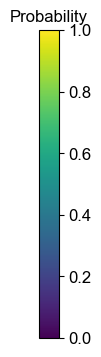

In [8]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colorbar import ColorbarBase
import matplotlib.cm as cm

# Set global font to Arial
plt.rcParams['font.family'] = 'Arial'

# Create figure for colorbar only
fig_cb, ax_cb = plt.subplots(figsize=(0.25, 4))
# Create colorbar
fs = 12
norm = mcolors.Normalize(vmin=0, vmax=1)
cmap = cm.get_cmap('viridis')  # Match your colorscale
cb = ColorbarBase(ax_cb, cmap=cmap, norm=norm, orientation='vertical')

# Put label as title instead of label
ax_cb.set_title('Probability', fontsize=fs, fontname='Arial')
cb.ax.tick_params(labelsize=fs)
plt.tight_layout()
plt.savefig(save_path + "SphereOddballProbColorbar.png", dpi=300, bbox_inches='tight')
plt.show()

# DB plots

0
{'B': 1,
 'D': 4,
 'K': 128,
 'L': 128,
 'N': 7,
 'add_mlp': False,
 'add_qk': False,
 'base_mask_value': -inf,
 'batch_size': 50,
 'db_lambda': 100.0,
 'db_phi0': 100.0,
 'decoder_mlp_depth': 2,
 'decoder_mlp_width': 32,
 'encoder_mlp_depth': 2,
 'encoder_mlp_width': 32,
 'epochs': 1000,
 'epsilon': 0.001,
 'equal_norm': False,
 'exact_copy': True,
 'hidden_map': 'crn',
 'input_proj_dim': 4,
 'input_proj_mode': 'identity',
 'input_proj_scale': 1,
 'learn_base_rates': True,
 'learn_rate_decoder': True,
 'learn_rate_encoder': True,
 'lr': 0.0025,
 'method': 'direct_solve',
 'min_max_choice': None,
 'mlp_baseline_activation': 'relu',
 'mlp_baseline_depth': 2,
 'mlp_baseline_dropout': 0.0,
 'mlp_baseline_width': 32,
 'n_nodes': 5,
 'offset': 0.0,
 'qk_dim': 4,
 'rate_decoder_type': 'linear',
 'rate_encoder_type': 'linear',
 'rate_param': 'db_split',
 'seed': 5,
 'shuffle_context': True,
 'sparsity_rho_all': 1.0,
 'sparsity_rho_edge': 1.0,
 'sparsity_rho_edge_base_W': 1.0,
 'temperature'

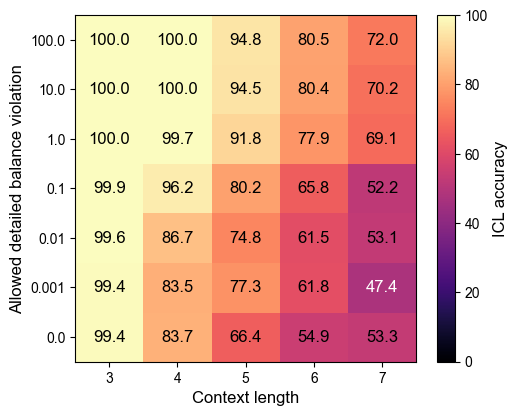

In [16]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Arial'

param1_values = [3, 4, 5, 6, 7]
param2_values = [0.0, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
param3_values = [1, 2, 3, 4, 5]
path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_db_seed_f/"

counts = 0
results_grid = np.zeros((len(param1_values), len(param2_values), len(param3_values)))
for i, param1 in enumerate(param1_values):
    for j, param2 in enumerate(param2_values):
        for k, param3 in enumerate(param3_values):
            path = f"{path_base}{param1}_{param2}_{param3}/"
            results_path = path + "results.pkl"
            try:
                with open(results_path, "rb") as file:
                    data = pickle.load(file)
                results = data['results']['markov']
                history = data['history']['markov']
                icl_acc = [val for val in history['icl_acc'] if val is not None]
                results_grid[i, j, k] = np.max(icl_acc)
            except Exception as e:
                print(f"Error loading results from {results_path}")
                counts += 1
print(counts)

# Print loaded params for the last file loaded, if available.
try:
    import pprint
    pprint.pprint(data['params'])
except Exception:
    print("No data['params'] available for pprint.")

# use this formatting for number plotting with color adaptation
fig, ax = plt.subplots(figsize=(5.5, 4.5))
fs = 12

avg_grid = np.mean(results_grid, axis=2)
im = ax.imshow(
    avg_grid.T,
    cmap='magma',
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=100
)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("ICL accuracy", size=fs)
ax.set_xlabel('Context length', fontsize=fs)
ax.set_ylabel('Allowed detailed balance violation', fontsize=fs)
ax.set_xticks(range(len(param1_values)), param1_values)
ax.set_yticks(range(len(param2_values)), param2_values)

# Number plotting with color adaptation
for (i, j), val in np.ndenumerate(avg_grid):
    if np.isnan(val):
        display_text = ""
        txt_color = "black"
    else:
        display_text = f"{val:.1f}"
        txt_color = "black" if val >= 50 else "white"
    ax.text(
        i, j, display_text,
        ha="center", va="center",
        color=txt_color,
        fontsize=fs-2 if not np.isnan(val) and val < 10 else fs
    )

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
fig.savefig(save_path + 'SI_ICLAccuracyDB.png', dpi=300, bbox_inches='tight')

# ablation

{   'K': 128,
    'L': 128,
    'D': 4,
    'N': 2,
    'B': 1,
    'epsilon': 0.001,
    'seed': 1,
    'exact_copy': True,
    'shuffle_context': True,
    'offset': 0.0,
    'min_max_choice': None,
    'unique_labels': False,
    'equal_norm': False,
    'n_nodes': 2,
    'add_qk': False,
    'add_mlp': False,
    'transform_func': 'exp',
    'learn_base_rates': True,
    'rate_encoder_type': 'linear',
    'encoder_mlp_depth': 2,
    'encoder_mlp_width': 32,
    'rate_decoder_type': 'linear',
    'decoder_mlp_depth': 2,
    'decoder_mlp_width': 32,
    'rate_param': 'db_split',
    'db_phi0': 1000000.0,
    'db_lambda': 100.0,
    'hidden_map': 'crn',
    'learn_rate_encoder': True,
    'learn_rate_decoder': True,
    'qk_dim': 4,
    'mlp_baseline_depth': 2,
    'mlp_baseline_width': 32,
    'mlp_baseline_dropout': 0.0,
    'mlp_baseline_activation': 'relu',
    'sparsity_rho_edge': 1.0,
    'sparsity_rho_all': 1.0,
    'sparsity_rho_edge_base_W': 1.0,
    'base_mask_value': -inf,


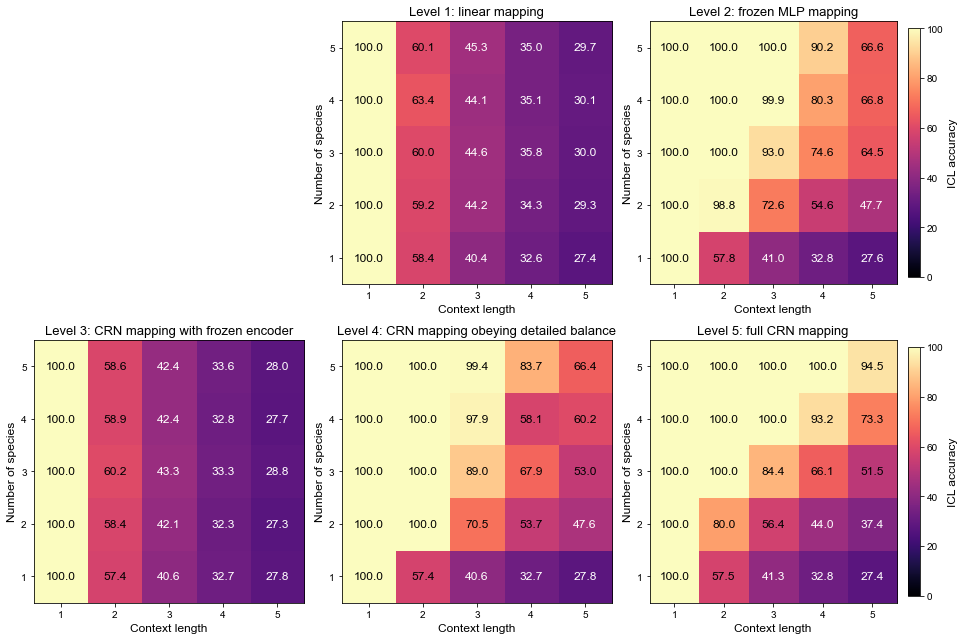

In [15]:
# Adapted heatmap plotting: numbers overlay with text color based on value

import torch
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time
import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

# Define the grid configuration
L_values = [1, 2, 3, 4, 5]
param1_values = [1, 2, 3, 4, 5]  # x
param2_values = [1, 2, 3, 4, 5]  # y
param3_values = [1, 2, 3, 4, 5]  # third axis (seeds or repeat)
def get_path_base(L):
    return f"/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_n_nodes_seed_L{L}"


def print_params_from_results(path):
    """
    Load the results.pkl from the given path and pretty print its 'params' dict.
    
    Parameters:
    - path (str): The directory containing 'results.pkl'
    """
    import pickle
    from pprint import pprint

    results_path = f"{path}results.pkl"
    with open(results_path, "rb") as file:
        data = pickle.load(file)
    params = data['params']
    pprint(params, sort_dicts=False, indent=4, width=80)


tag_dict = {1: "_relu_directed"}
tag_dict = {1: "_identity_directed", 2: "_identity_directed"}
tag_dict = {1: "_identity_directed", 2: "_id_mlp_8"}

tag_dict = {1: "_f", 2: "_f", 4: "_f_db", 5: "_f"}

#tag_dict = {1: "_identity_directed", 2: ""}

results_grid_avgs = []
failed_counts = []
example_params = []

for L in L_values:
    counts = 0
    results_grid = np.zeros((len(param1_values), len(param2_values), len(param3_values)))
    path_base = get_path_base(L)
    for i, param1 in enumerate(param1_values):
        for j, param2 in enumerate(param2_values):
            for k, param3 in enumerate(param3_values):
                tag = tag_dict.get(L, "")
                path = path_base + tag + f"/{param1}_{param2}_{param3}/"
                results_path = path + "results.pkl"
                try:
                    with open(results_path, "rb") as file:
                        data = pickle.load(file)
                    results = data['results']['markov']
                    history = data['history']['markov']
                    icl_acc = [val for val in history['icl_acc'] if val is not None]
                    results_grid[i, j, k] = np.max(icl_acc)
                except Exception:
                    counts += 1
                    pass
    failed_counts.append(counts)
    results_grid_avg = np.mean(results_grid, axis=2)
    results_grid_avgs.append(results_grid_avg)
    try:
        example_params.append(data['params'])
    except Exception:
        example_params.append(None)

print_params_from_results(get_path_base(5) +"/2_2_1/")

fig, axes = plt.subplots(2, 3, figsize=(13.5, 9))
fs = 12
for ax in axes.flat:
    ax.axis('off')

heatmap_positions = [
    (0,1),
    (0,2),
    (1,0),
    (1,1),
    (1,2),
]

titles = ["Level 1: linear mapping", 
          "Level 2: frozen MLP mapping", 
          "Level 3: CRN mapping with frozen encoder", 
          "Level 4: CRN mapping obeying detailed balance", 
          "Level 5: full CRN mapping", 
          ]
for L_index, ((row, col), avg_grid) in enumerate(zip(heatmap_positions, results_grid_avgs)):
    ax = axes[row, col]
    ax.axis('on')
    im = ax.imshow(
        avg_grid.T,
        cmap='magma',
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=100
    )
    ax.set_title(titles[L_index], fontsize=fs+1)
    ax.set_xlabel('Context length', fontsize=fs)
    ax.set_ylabel('Number of species', fontsize=fs)
    ax.set_xticks(range(len(param1_values)), param1_values)
    ax.set_yticks(range(len(param2_values)), param2_values)

    # Number plotting with color adaptation
    for (i, j), val in np.ndenumerate(avg_grid):
        if np.isnan(val):
            display_text = ""
            txt_color = "black"
        else:
            display_text = f"{val:.1f}"
            txt_color = "black" if val >= 50 else "white"
        ax.text(
            i, j, display_text,
            ha="center", va="center",
            color=txt_color,
            fontsize=fs-2 if not np.isnan(val) and val < 10 else fs
        )

    if col == 2:
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label("ICL accuracy", size=fs)

axes[0, 0].set_visible(False)
plt.tight_layout()

save_path = '/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/'
#fig.savefig(save_path + 'ICLAccuracy_Ablation.png', dpi=300, bbox_inches='tight')

In [ ]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Arial"

# --- sweep axes (edit to match your folder names param1_param2_param3/) ---
# param1: N (context length), param2: D (dimension), param3: seed
param1_values = [3, 4, 5]    # N (context length)
param2_values = [2, 3, 4]    # D (dimension)
param2_values = [1, 2, 3]    # D (dimension)
#param2_values = [1, 2, 3, 4, 5]    # D (dimension)
param3_values = [1, 2, 3, 4, 5]  # seed

path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/N_D_seed_sphereodd_fin/"
tag = "_Sphere"

fac = 0.8
figsize = (4.75*fac, 4.2*fac)
# Which distance to extract accuracy for (or 'train' for training distance, or 'mean' for average)
DISTANCE_TO_EXTRACT = 'train'  # Options: 'train', 'mean', or a specific distance like 5

def _extract_accuracy_at_distance(results_dict, target_dist='train', train_dist=5.0):
    """
    Extract test accuracy from results at a specific distance.
    """
    if not isinstance(results_dict, dict) or "by_distance" not in results_dict:
        return np.nan
    
    by_dist = results_dict["by_distance"]
    
    if target_dist == 'train':
        # Get accuracy at training distance
        return float(by_dist.get(train_dist, np.nan))
    elif target_dist == 'mean':
        # Get mean accuracy across all distances
        accs = [v for v in by_dist.values() if v is not None]
        return float(np.mean(accs)) if accs else np.nan
    else:
        # Get accuracy at specific distance
        return float(by_dist.get(target_dist, np.nan))

results_grid_markov = np.full(
    (len(param1_values), len(param2_values), len(param3_values)), np.nan, dtype=float
)
results_grid_mlp = np.full(
    (len(param1_values), len(param2_values), len(param3_values)), np.nan, dtype=float
)

for i, param1 in enumerate(param1_values):
    for j, param2 in enumerate(param2_values):
        for k, param3 in enumerate(param3_values):
            path = path_base + f"{param1}_{param2}_{param3}/"
            results_path = path + "results.pkl"
            try:
                with open(results_path, "rb") as f:
                    data = pickle.load(f)
                
                results = data.get("results", {})
                params = data.get("params", {})
                train_dist = params.get("perturb_dist", 5.0)
                
                train_dist = 5
                # Handle multi-model results
                if isinstance(results, dict):
                    if "markov" in results:
                        results_grid_markov[i, j, k] = _extract_accuracy_at_distance(
                            results["markov"], DISTANCE_TO_EXTRACT, train_dist
                        )
                    else:
                        # Single model case
                        results_grid_markov[i, j, k] = _extract_accuracy_at_distance(
                            results, DISTANCE_TO_EXTRACT, train_dist
                        )
                    
                    if "mlp" in results:
                        results_grid_mlp[i, j, k] = _extract_accuracy_at_distance(
                            results["mlp"], DISTANCE_TO_EXTRACT, train_dist
                        )
                        
            except Exception as e:
                print(f"Error loading {results_path}: {e}")

save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"
fs = 12

# --- Single heatmap for Markov ---
fig_markov, ax_markov = plt.subplots(figsize=figsize)
grid = results_grid_markov
results_grid_avg = np.nanmean(grid, axis=2)
# Accuracy typically ranges from 0 to 100 (percent)
vmin, vmax = 0.0, 100.0
im = ax_markov.imshow(
    results_grid_avg.T,
    cmap="magma",  # Higher accuracy is better
    aspect="auto",
    origin="lower",
    vmin=vmin,
    vmax=vmax,
)
# Show numbers on the grid
for (i, j), val in np.ndenumerate(results_grid_avg):
    label = f"{val:.1f}" if not np.isnan(val) else "N/A"
    ax_markov.text(
        i, j, label,
        ha="center", va="center",
        color="white" if not np.isnan(val) and val < 50 else "black",
        fontsize=fs
    )
ax_markov.set_title("CRN", fontsize=fs+2)
ax_markov.set_xlabel("Context length", fontsize=fs)
ax_markov.set_ylabel("Dimension", fontsize=fs)
ax_markov.set_xticks(range(len(param2_values)), param2_values)
ax_markov.set_yticks(range(len(param1_values)), param1_values)
cbar = fig_markov.colorbar(im, ax=ax_markov, shrink=0.98, pad=0.04)
cbar.set_label(f"ICL accuracy", size=fs)

plt.tight_layout()
plt.show()
fig_markov.savefig(save_path + "AccuracyHeatmaps_CRN" + tag + ".png", dpi=300, bbox_inches="tight")

# --- Single heatmap for MLP ---
fig_mlp, ax_mlp = plt.subplots(figsize=figsize)
grid = results_grid_mlp
results_grid_avg = np.nanmean(grid, axis=2)
# Accuracy typically ranges from 0 to 100 (percent)
vmin, vmax = 0.0, 100.0
im = ax_mlp.imshow(
    results_grid_avg.T,
    cmap="magma",  # Higher accuracy is better
    aspect="auto",
    origin="lower",
    vmin=vmin,
    vmax=vmax,
)
# Show numbers on the grid
for (i, j), val in np.ndenumerate(results_grid_avg):
    label = f"{val:.1f}" if not np.isnan(val) else "N/A"
    ax_mlp.text(
        i, j, label,
        ha="center", va="center",
        color="white" if not np.isnan(val) and val < 50 else "black",
        fontsize=fs
    )
ax_mlp.set_title("MLP", fontsize=fs+2)
ax_mlp.set_xlabel("Context length", fontsize=fs)
ax_mlp.set_ylabel("Dimension", fontsize=fs)
ax_mlp.set_xticks(range(len(param2_values)), param2_values)
ax_mlp.set_yticks(range(len(param1_values)), param1_values)
cbar = fig_mlp.colorbar(im, ax=ax_mlp, shrink=0.98, pad=0.04)
cbar.set_label(f"ICL accuracy", size=fs)

plt.tight_layout()
plt.show()
# fig_mlp.savefig(save_path + "AccuracyHeatmaps_MLP" + tag + ".png", dpi=300, bbox_inches="tight")

# Print summary
print(f"\nNon-NaN values - Markov: {np.sum(~np.isnan(results_grid_markov))}/{results_grid_markov.size}")
print(f"Non-NaN values - MLP: {np.sum(~np.isnan(results_grid_mlp))}/{results_grid_mlp.size}")

# wta vs qk

Detected model types: ['wta', 'qk']

wta results array (context_len, data_dim, seed):
[[[ 70.  100.   99.8 100.   99.8  99.6 100.  100.   68.6 100.  100.
   100.  100.  100.   99.8 100.  100.   77.2  70.6 100.  100.   65.6
   100.   90.8 100. ]
  [100.  100.  100.  100.  100.  100.  100.  100.   99.6 100.   99.8
   100.  100.  100.   99.8 100.  100.  100.   99.8  99.2  99.8 100.
    98.8  67.  100. ]
  [ 99.6  99.8 100.  100.  100.  100.  100.  100.   99.  100.  100.
   100.   99.4  99.8 100.  100.  100.   74.6  99.6 100.  100.   99.8
    99.4  99.8 100. ]
  [ 99.4  99.8 100.   98.4 100.   99.6 100.   98.6  91.  100.  100.
   100.  100.   99.6 100.   99.2  99.4 100.   99.6  99.6  99.6 100.
   100.   68.8 100. ]
  [ 74.  100.   99.6 100.   98.6 100.  100.   99.4  99.8  99.6  72.
   100.   99.4  99.2  99.4  99.  100.   97.8 100.   98.6  99.2  99.4
   100.  100.  100. ]
  [ 98.2  98.4  99.2  99.2  99.2  98.6  99.4  98.2  99.   99.8  99.6
    99.6  99.6 100.   99.2  99.8  99.8  99.  100.  

C:\Users\csfloyd\AppData\Local\Temp\ipykernel_14180\3224110239.py:98: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  model_cmap = cm.get_cmap('tab10')


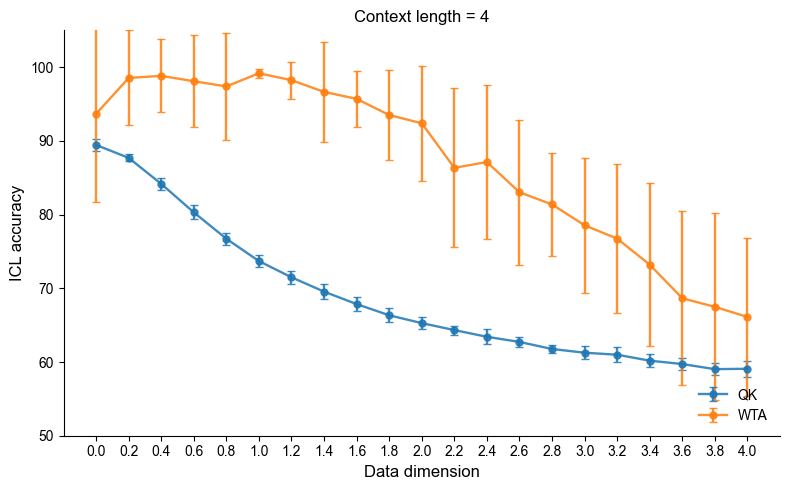

In [ ]:
# Import necessary components
import torch

# Import from refactored modular structure
from data_generation import GaussianMixtureModel, generate_icl_gmm_data
from datasets import ICLGMMDataset, collate_fn
from models import MatrixTreeMarkovICL
from training import train_model
from evaluation import test_icl

from torch.utils.data import DataLoader
import os
import time

import pickle
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
import numpy as np

param2_values = np.arange(0.0, 4.2, 0.2)   # data dimension
param2_values[-2] = 3.8
param1_values = [4]  # context length
param3_values = range(25)      # seeds

path_base = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/D_mean_class_spread_seed_wta_qk_sd4/"



def extract_best_icl(history_obj, metric = "icl_acc"):
    """
    Return dict[model_name -> best icl_acc] from a history object.

    Supports:
      1) single-model history: {'icl_acc': [...], ...}
      2) multi-model history: {'markov': {'icl_acc': [...]}, 'qk': {'icl_acc': [...]}, ...}
    """
    # Single-model case
    if isinstance(history_obj, dict) and metric in history_obj:
        vals = [v for v in history_obj[metric] if v is not None]
        return {"single": np.max(vals) if len(vals) > 0 else np.nan}

    # Multi-model case
    out = {}
    if isinstance(history_obj, dict):
        for model_name, model_hist in history_obj.items():
            if isinstance(model_hist, dict) and metric in model_hist:
                vals = [v for v in model_hist[metric] if v is not None]
                out[model_name] = np.max(vals) if len(vals) > 0 else np.nan
    return out

# model_results[model_name] -> shape (n_param1, n_param2, n_param3). Each entry: icl_acc for (param1, param2, param3/seed)
model_results = {}

for i, param1 in enumerate(param1_values):
    for j, param2 in enumerate(param2_values):
        
        for k, seed in enumerate(param3_values):
            run_dir = f"{path_base}{param1}_{param2}_{seed}/"
            results_path = f"{run_dir}results.pkl"
            if not os.path.exists(results_path):
                print(f"Results path does not exist: {results_path}")
                continue
                
            with open(results_path, "rb") as f:
                data = pickle.load(f)
            history = data.get("history", {})
            best_icl_by_model = extract_best_icl(history, metric = "icl_acc")
            for model_name, best_icl in best_icl_by_model.items():
                if model_name not in model_results:
                    model_results[model_name] = np.full(
                        (len(param1_values), len(param2_values), len(param3_values)),
                        np.nan,
                    )
                model_results[model_name][i, j, k] = best_icl

print("Detected model types:", list(model_results.keys()))
for model_name, grid in model_results.items():
    print(f"\n{model_name} results array (context_len, data_dim, seed):")
    print(grid)

# ---- Plotting: One row per data dimension (param2) ----
import matplotlib.cm as cm
import matplotlib.colors as mcolors

fs = 12
x_positions = np.arange(len(param2_values))  # data dimension on x-axis NOW
model_names_sorted = sorted(model_results.keys())
n_rows = len(param1_values)  # context lengths: one row per context len now
fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=1,
    figsize=(8, 5),
    sharex=True,
    sharey=True,
    squeeze=False
)
cmap = cm.viridis
model_cmap = cm.get_cmap('tab10')
norm_model = mcolors.Normalize(vmin=0, vmax=max(len(model_names_sorted)-1, 1))
axes = axes.flatten()

model_names = ["CRN", "MLP"]
for row_idx, param1 in enumerate(param1_values):
    ax = axes[row_idx]
    for model_idx, model_name in enumerate(model_names_sorted):
        grid = model_results[model_name]  # (context_len, data_dim, seed)
        # FIX: param1 selects the row (context_len), param2 is data_dim (x-axis)
        i = row_idx
        y_mean = np.nanmean(grid[i, :, :], axis=1)
        y_std = np.nanstd(grid[i, :, :], axis=1)
        color = model_cmap(model_idx)
        display_names = {"qk": "QK", "wta": "WTA"}
        label = display_names.get(model_name, model_name)
        ax.errorbar(
            x_positions + (model_idx - (len(model_names_sorted)-1)/2) * 0.0,
            y_mean,
            yerr=y_std,
            linestyle="-",
            linewidth=1.7,
            marker="o",
            markersize=5,
            capsize=3,
            label=label,
            color=color,
            alpha=0.86
        )
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_ylabel("ICL accuracy", fontsize=fs)
    ax.set_ylim(50, 105)
    #ax.grid(axis="y", alpha=0.3)
    ax.set_xticks(x_positions)
    ax.set_xticklabels([f"{round(v, 1)}" for v in param2_values])   # data dims, previously context lens, rounded to 1 decimal
    ax.set_title(f"Context length = {param1}", fontsize=fs)
    if row_idx == len(param1_values)-1:
        ax.legend(fontsize=fs-2, frameon=False, loc="lower right", ncol=1)

axes[-1].set_xlabel("Data dimension", fontsize=fs)

plt.tight_layout()
plt.show()

# save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"
# fig.savefig(save_path + f"SI_WTAvsQK.png", dpi=300, bbox_inches="tight")


C:\Users\csfloyd\AppData\Local\Temp\ipykernel_14180\2328755894.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  model_cmap = cm.get_cmap("tab10")
C:\Users\csfloyd\AppData\Local\Temp\ipykernel_14180\2328755894.py:145: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_.set_xticklabels(new_labels)
C:\Users\csfloyd\AppData\Local\Temp\ipykernel_14180\2328755894.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_.set_yticklabels(new_labels)
C:\Users\csfloyd\AppData\Local\Temp\ipykernel_14180\2328755894.py:145: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_.s

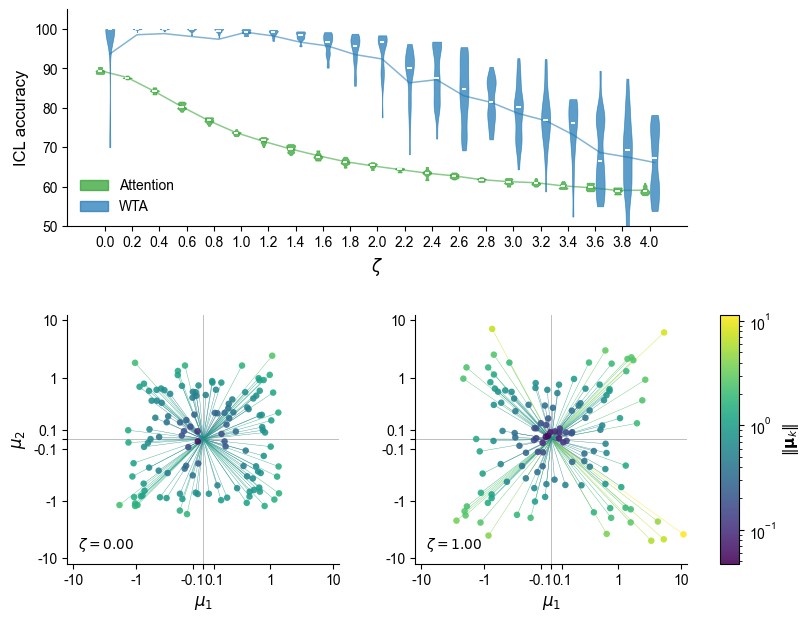

In [ ]:
# ---- Combined figure: violins (top) + 2D class-mean scatters (bottom) ----
import matplotlib.cm as cm
from matplotlib.patches import Patch
from matplotlib.colors import LogNorm
from matplotlib.ticker import SymmetricalLogLocator, NullFormatter
from data_generation import GaussianMixtureModel, generate_icl_gmm_data

fs = 12
omit_percentile_low = 5
omit_percentile_high = 95

fig = plt.figure(figsize=(8, 7.2))
gs = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.15], hspace=0.38)
ax_v = fig.add_subplot(gs[0])
gs_bot = gs[1].subgridspec(1, 2, wspace=0.28)
ax_sc0 = fig.add_subplot(gs_bot[0, 0])
ax_sc1 = fig.add_subplot(gs_bot[0, 1])
axes_sc = [ax_sc0, ax_sc1]

# ============================================================
# Top: compact violin plots
# ============================================================
model_names_sorted = sorted(model_results.keys())
n_models = len(model_names_sorted)
model_cmap = cm.get_cmap("tab10")
display_names = {"qk": "Attention", "wta": "WTA"}

group_width = 0.72
violin_width = group_width / max(n_models, 1)
row_idx = 0
legend_handles = []

for model_idx, model_name in enumerate(model_names_sorted):
    grid = model_results[model_name]
    color = "#2ca02c" if model_name == "qk" else "#1f77b4"  # blue from tab10
    offset = (model_idx - (n_models - 1) / 2.0) * violin_width

    data_for_violins = []
    positions = []
    for j in range(len(param2_values)):
        vals = grid[row_idx, j, :]
        vals = vals[~np.isnan(vals)]
        if len(vals) == 0:
            continue
        p_low = np.percentile(vals, omit_percentile_low)
        p_high = np.percentile(vals, omit_percentile_high)
        trimmed_vals = vals[(vals >= p_low) & (vals <= p_high)]
        if len(trimmed_vals) == 0:
            continue
        data_for_violins.append(np.asarray(trimmed_vals, dtype=float))
        positions.append(j + offset)

    if not data_for_violins:
        continue

    parts = ax_v.violinplot(
        data_for_violins,
        positions=positions,
        widths=violin_width * 0.92,
        showmeans=False,
        showmedians=True,
        showextrema=False,
        bw_method=0.35,
    )
    for body in parts["bodies"]:
        body.set_facecolor(color)
        body.set_edgecolor(color)
        body.set_alpha(0.72)
        body.set_linewidth(0.5)
    if parts.get("cmedians") is not None:
        parts["cmedians"].set_color("white")
        parts["cmedians"].set_linewidth(1.4)
        parts["cmedians"].set_alpha(0.95)

    y_mean = np.nanmean(grid[row_idx, :, :], axis=1)
    ax_v.plot(
        np.arange(len(param2_values)) + offset,
        y_mean,
        color=color,
        linewidth=1.1,
        alpha=0.55,
        zorder=1,
    )
    legend_handles.append(
        Patch(
            facecolor=color,
            edgecolor=color,
            alpha=0.72,
            label=display_names.get(model_name, model_name),
        )
    )

ax_v.spines["top"].set_visible(False)
ax_v.spines["right"].set_visible(False)
ax_v.set_ylabel("ICL accuracy", fontsize=fs)
ax_v.set_ylim(50, 105)
ax_v.set_xticks(np.arange(len(param2_values)))
ax_v.set_xticklabels([f"{round(v, 1)}" for v in param2_values])
ax_v.set_xlabel(r"$\zeta$", fontsize=fs)
ax_v.legend(
    handles=legend_handles,
    fontsize=fs - 2,
    frameon=False,
    loc="lower left",
    ncol=1,
)

# ============================================================
# Bottom: 2D class-mean scatters (shared log color scale)
# ============================================================
K, D, L = 128, 2, 128
epsilon = 1e-3
seed = 0
spread_cfgs = [
    ("Low spread", 0.0),
    ("Mean-norm spread", 1.0),
]

gmms = {}
for title, spread in spread_cfgs:
    gmms[spread] = GaussianMixtureModel(
        K=K, D=D, L=L, epsilon=epsilon, seed=seed,
        offset=0.0, use_offset=False,
        mean_anisotropy=None, mean_norm_spread=spread,
    )

all_means = np.concatenate(
    [gmms[s].class_means.detach().cpu().numpy() for _, s in spread_cfgs],
    axis=0,
)
all_norms = np.linalg.norm(all_means, axis=1)
norm = LogNorm(vmin=max(all_norms.min(), 1e-6), vmax=all_norms.max())
cmap = plt.get_cmap("viridis")

linthresh, linscale = 0.4, 0.6
lim = max(np.max(np.abs(all_means)) * 1.15, 1.5)

def remove_zero_tick(ax_, axis="x"):
    ticks = ax_.get_xticks() if axis == "x" else ax_.get_yticks()
    new_labels = [
        "" if np.isclose(t, 0) else (f"{t:.1f}" if abs(t) < 1 else f"{t:.0f}")
        for t in ticks
    ]
    if axis == "x":
        ax_.set_xticklabels(new_labels)
    else:
        ax_.set_yticklabels(new_labels)

sc = None
for ax, (title, spread) in zip(axes_sc, spread_cfgs):
    means = gmms[spread].class_means.detach().cpu().numpy()
    norms = np.linalg.norm(means, axis=1)

    sc = ax.scatter(
        means[:, 0], means[:, 1],
        c=norms, cmap=cmap, norm=norm,
        s=22, alpha=0.88, linewidths=0, zorder=10,
    )
    for i in range(means.shape[0]):
        ax.plot(
            [0, means[i, 0]], [0, means[i, 1]],
            color=cmap(norm(norms[i])),
            linewidth=0.3, alpha=0.88, zorder=5,
        )

    ax.axhline(0, color="0.75", linewidth=0.7, zorder=1)
    ax.axvline(0, color="0.75", linewidth=0.7, zorder=1)
    ax.set_xscale("symlog", linthresh=linthresh, linscale=linscale)
    ax.set_yscale("symlog", linthresh=linthresh, linscale=linscale)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.xaxis.set_major_locator(SymmetricalLogLocator(linthresh=linthresh, base=10))
    ax.yaxis.set_major_locator(SymmetricalLogLocator(linthresh=linthresh, base=10))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.yaxis.set_minor_formatter(NullFormatter())
    remove_zero_tick(ax, "x")
    remove_zero_tick(ax, "y")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlabel(r"$\mu_1$", fontsize=fs)
    ax.text(
        0.04, 0.04,
        rf"$\zeta = {spread:.2f}$",
        transform=ax.transAxes, va="bottom", ha="left", fontsize=fs - 2,
    )

axes_sc[0].set_ylabel(r"$\mu_2$", fontsize=fs)

# Leave room on the right for the colorbar, then lock the violin
# to the actual left/right of the two scatter axes.
plt.tight_layout(rect=[0.0, 0.0, 0.90, 1.0])

# Set white facecolor for the figure
fig.patch.set_facecolor('white')

cax = ax_sc1.inset_axes([1.12, 0.0, 0.07, 1.0])
cbar = fig.colorbar(sc, cax=cax)
cbar.set_label(r"$\|\mathbf{\mu}_k\|$", fontsize=fs - 1)

fig.canvas.draw()
p0 = ax_sc0.get_position()
p1 = ax_sc1.get_position()
pv = ax_v.get_position()
ax_v.set_position([p0.x0, pv.y0, p1.x1 - p0.x0, pv.height])

plt.show()

save_path = "/Users/csfloyd/Dropbox/Projects/MarkovComputation/Figures/"
#fig.savefig(save_path + f"SI_WTAvsQK.png", dpi=300, bbox_inches="tight")

In [1]:
import pickle
with open("/Users/csfloyd/Dropbox/Projects/MarkovComputation/DirsICL/D_mean_class_spread_seed_wta_qk_sd4/4_0.0_0/results.pkl", "rb") as f:
    data = pickle.load(f)
print(data["params"]["D"])
print(data["params"]["mean_norm_spread"], data["params"]["N"])

4
0.0 4
